# I1 토출량(FT)이 목표(SV)를 넘은 원인 규명 — 2026-09-29 07:00~11:00

## 질문

`g_s_SV_I1`(목표 토출량)과 `Scale_Out___FT_I1`(실측 토출량)은 거의 같아야 한다. 평소 안정구간 괴리는
±1~2% 수준이다(`parkkt/SV_유량_추종_분석.ipynb`). 그런데 **9/29 오전 근무 내내 FT 가 SV 보다 약 9% 높았다.**
서서히 오른 게 아니라 근무 시작부터 높았으니, 누군가 계수를 바꾼 게 아니냐는 게 출발점이다.

확인할 것 세 가지:
1. FT 와 SV 의 관계를 바꿀 수 있는 **계수가 PLC 에 무엇이 있나**
2. 그 계수가 **실제로 바뀌었나** — 바뀌었다면 언제, 무엇이(자동/수동)
3. 계수가 아니라면 **무엇이 바뀌었나**, 그리고 PLC 가 그걸 감지했나

## 결론 요약 (근거는 각 섹션)

| 질문 | 답 | 섹션 |
|---|---|---|
| 펌프가 FT 를 보고 SV 를 맞추나? | **아니다. 개루프.** Hz = SV × Auto-Cal 계수 × Gain. FT 는 운전 중 제어에 안 들어간다 | §1 |
| 9/29 에 계수가 바뀌었나? | **안 바뀌었다.** 기간 중 바뀐 건 Auto-Cal 2회(9/27 11:40, 9/30 15:27)뿐이고, Hz/SV 비율이 9/28~9/30 15시까지 일정 | §2, §4 |
| FT 계측 스케일(Imp/L·비중·Offset)은? | 안 바뀌었다. FT/Hz 는 펌프 슬립 곡선 하나로 전 기간이 설명된다 | §2, §5 |
| 그럼 무엇이 바뀌었나? | **ISO1 라인 하류 유로 저항이 열렸다**(헤드 ISO 노즐 추정). PT↓ → 펌프 내부 누설↓ → 같은 Hz 에서 실제 유량↑ | §5~§7 |
| 9/29 만의 일인가? | 아니다. 9/30 오전, 9/30 오후, 10/1 주간에도 같은 현상 | §3 |
| 언제 바뀌었나? | 9/28 23:58~9/29 06:13 야간 정지 중에 열렸고, **9/29 11:23:01~07 증압 도중 6초에 걸쳐** 원래대로 조여졌다 | §6 |
| Auto-Cal 은 언제 누르나? | **사람이 HMI 에서, 자동운전을 내린 상태에서만** 시작된다. 한 달(9/7~10/7) 3회뿐, 정기 루틴 아님 — 9/27 셧다운 중, 9/30·10/5 생산 중 1.5~7분 정지 | §2-4 |
| 9/30 Auto-Cal 은 왜? | 15:08 저항↑로 덜 나오자 → 자동 정지 → 저항 풀림 → Auto-Cal → 재개 → 다시 열림. **노즐 조정과 Auto-Cal 이 한 세션**으로 보인다 | §6-2 |
| 토출량 이상을 판정하는 곳이 있나? | **없다.** 알람 220개 중 유량·샷량·혼합비 관련 0개. 사출은 **시간**으로 끝나고, 샷별 실측 g 은 HMI 리포트로 넘기기만 한다 | §8 |
| 실제 품질 영향은? | 그 리포트 데이터로 보면 9/29 오전 **샷별 ISO/POL 혼합비가 +7% 안팎** 틀어진 채 생산됐다(P2/I2 쌍은 그대로) | §8-4 |
| 펌프 이상과 배관 이상은 어떻게 가르나? | Hz/SV(제어) · 펌프 잔차(펌프계) · K(배관) 를 따로 본다. 인버터 피드백이 없어도 **유량계가 회전계 역할**을 한다. 펌프 지표는 재료온도 보정이 필요 | §10 |
| 온도는 식에 어떻게 넣나? | 절대온도는 **지수 안**(Andrade μ=A·e^(B/T))에 넣는다. 단순 치환은 0.34%/℃ 라 실제(ISO 2.2, 폴리올 6.6%/℃)의 1/6~1/20. **ISO 는 펌프 누설 항, 폴리올은 배관 압력 항**에 들어간다 | §11 |
| 누가/무엇이 감지·보정했나? | **PLC 에는 감지·보정 로직이 없다.** 저압 알람은 증압 중 PT ≤ 30 이 1초 지속돼야 하는데 단발 dip 뿐이라 한 번도 안 걸림. 기계적 수동 조작으로 추정 → **현장 확인 필요** | §8 |

## 목차
- §0 준비
- §1 PLC 로직 — FT 와 Hz 는 어떻게 계산되나
- §2 계수 태그 — DB 에 있나, 바뀌었나, **Auto-Cal 은 언제 누르나**
- §3 실측 데이터 — 이상 구간 찾기
- §4 제어측(Hz/SV) 과 실측(FT/SV) 을 나란히
- §5 FT 스케일은 그대로인가 — 펌프 슬립 곡선
- §6 9/29 전환 순간 확대 · **9/30 Auto-Cal 조정 세션**
- §7 원인 위치 좁히기 — 같은 헤드의 P1, 탱크/온도, 순환운전(20Hz)
- §8 토출량 이상을 판정하는 곳이 있나 — 알람 목록, 사출 종료 조건, 샷 리포트 혼합비
- §9 결론 · 현장 확인 요청 · 한계
- §10 진단 지표 정리 — 제어·펌프계·배관·계측 가르기, 인버터 피드백 없이 펌프계 보는 법, 지표 계산 함수
- §11 온도(점도) 보정 — 원료 점도표, 지수식 vs 근사식, 온도가 유량·압력 어디에 들어가나, I1·P1 실측 검증

---
## §0. 준비

- 데이터는 `LogExtractor` 로 받고, 받은 결과는 `cache/ftsv_*.pkl` 로 저장한다(`*.pkl` 은 gitignore).
  캐시가 있으면 DB 를 다시 치지 않는다.
- PLC IL 원본은 옆 리포 `../HDI_Relay/backend/IL_file/` 에 있다. **UTF-16LE + CRLF** 라서 그냥 grep 하면
  아무것도 안 잡힌다. 여기서는 `encoding="utf-16"` 으로 읽는다.
- 펌프는 I1 하나만 받는다. 태그 구성이 틱 개수를 바꾸므로(`SV_유량_추종_분석.ipynb` 참고) P1 은 따로 받는다.

In [1]:
import os, re, sys, pickle, struct, warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

ROOT_DIR = os.path.abspath(os.getcwd())          # .../KTA/DB_Log
if ROOT_DIR not in sys.path:
    sys.path.insert(0, ROOT_DIR)

matplotlib.rcParams["font.family"] = "AppleGothic"   # macOS
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 30)

from influxdb_client.client.warnings import MissingPivotFunction
warnings.simplefilter("ignore", MissingPivotFunction)
from Log_Extractor import LogExtractor

IL_DIR = os.path.normpath(os.path.join(ROOT_DIR, "..", "HDI_Relay", "backend", "IL_file"))
CACHE_DIR = os.path.join(ROOT_DIR, "cache")
os.makedirs(CACHE_DIR, exist_ok=True)

MAIN_START, MAIN_END = "2026-09-22 00:00:00", "2026-10-02 00:00:00"   # I1 주 데이터 (9/24~27 은 추석 셧다운)
AUX_START, AUX_END = "2026-09-28 18:00:00", "2026-10-01 16:00:00"     # I1 보조 태그 · P1 비교
STEADY_MIN = 5    # Hz 가 바뀐 뒤 이 틱 수 이상 지난 틱만 안정구간 (전류_이상구간_비교_9월29일.ipynb 와 동일)

# 색 — 팀 노트북과 같은 팔레트 (BLUE/ORANGE/CRITICAL 조합은 CVD 검증 통과)
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, CRITICAL = "#2a78d6", "#eb6834", "#d03b3b"
DOW = "월화수목금토일"
print("IL 경로:", IL_DIR, "| 존재:", os.path.isdir(IL_DIR))

IL 경로: /Users/jeonjae/Desktop/KTA/HDI_Relay/backend/IL_file | 존재: True


In [2]:
_EX = None
def extractor():
    global _EX
    if _EX is None:
        _EX = LogExtractor(env_path=os.path.join(ROOT_DIR, ".env"))
    return _EX


def cached(name, fn):
    """cache/<name>.pkl 이 있으면 그걸 쓰고, 없으면 fn() 결과를 저장한다."""
    path = os.path.join(CACHE_DIR, name + ".pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            obj = pickle.load(f)
        print(f"[cache] {name}")
        return obj
    obj = fn()
    with open(path, "wb") as f:
        pickle.dump(obj, f)
    return obj


def to_utc(kst):
    return pd.Timestamp(kst).tz_localize("Asia/Seoul").tz_convert("UTC").strftime("%Y-%m-%dT%H:%M:%SZ")


def raw_events(tags, start_kst, stop_kst, chunk_days=3):
    """피벗 없이 (시각, 태그, 값) 이벤트를 그대로 받는다.

    로거는 '값이 바뀐 순간' + 300초 스냅샷만 남기므로, 상수성 태그(계수·설정값)는
    이렇게 받으면 **바뀐 시각이 그대로** 보인다. 태그 필터는 정규식으로 pushdown 한다.
    """
    ex = extractor()
    out, t, end = [], pd.Timestamp(start_kst), pd.Timestamp(stop_kst)
    while t < end:
        u = min(t + pd.Timedelta(days=chunk_days), end)
        q = f"""from(bucket: "{ex.bucket}")
            |> range(start: {to_utc(t)}, stop: {to_utc(u)})
            |> filter(fn: (r) => r._measurement == "plc_line2")
            |> filter(fn: (r) => r.tag_name =~ {LogExtractor._tag_regex(tags)})
            |> keep(columns: ["_time", "_value", "tag_name"])"""
        df = ex.query_api.query_data_frame(q)
        if isinstance(df, list):
            df = pd.concat(df) if df else pd.DataFrame()
        if not df.empty:
            out.append(df[["_time", "tag_name", "_value"]])
        t = u
    if not out:
        return pd.DataFrame(columns=["_time", "tag_name", "_value"])
    df = pd.concat(out)
    df["_time"] = pd.to_datetime(df["_time"]).dt.tz_convert("Asia/Seoul").dt.tz_localize(None)
    return df.sort_values("_time").reset_index(drop=True)


def change_points(ev):
    """태그별로 직전 값과 달라진 행만 남긴다 (각 태그의 첫 행 포함)."""
    keep = ev.groupby("tag_name")["_value"].transform(lambda v: v.ne(v.shift()))
    return ev[keep.to_numpy(dtype=bool)]


def read_il(fname):
    with open(os.path.join(IL_DIR, fname), encoding="utf-16") as f:
        return f.read().splitlines()


def show_il(fname, pattern, n_lines, before=0):
    """pattern 이 처음 나오는 줄부터 n_lines 줄을 원본 줄번호와 함께 찍는다."""
    lines = read_il(fname)
    idx = next(i for i, l in enumerate(lines) if re.search(pattern, l))
    for i in range(max(0, idx - before), min(len(lines), idx + n_lines)):
        print(f"{fname}:{i + 1:<5d} {lines[i]}")


def style_ax(ax):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=8)
    ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

---
## §1. PLC 로직 — FT 와 Hz 는 어떻게 계산되나

### 1-1. FT(`Scale_Out___FT_I1`) — 유량계 펄스를 g/s 로 바꾸는 식

고속카운터 CH1 이 ISO1 유량계 펄스를 센다. 500ms 마다 카운트 차이 × 2 = 초당 펄스수(`Flow_FRQ_I1`).

In [3]:
show_il("HSC_Control.il", r"CH_01\s+ISO1 Flow", 57)

HSC_Control.il:86    CMT	======================= 고속카운터 CH_01  ISO1 Flow =================
HSC_Control.il:87    LOAD	_RUN
HSC_Control.il:88    OUT	_12_CH1_CNTEN
HSC_Control.il:89    OUT	_12_CH1_AUXEN
HSC_Control.il:90    LOAD	Auto_Running
HSC_Control.il:91    OR	_12_CH1_CRY
HSC_Control.il:92    OUT	_12_CH1_PREEN
HSC_Control.il:93    LOADP	T1910
HSC_Control.il:94    DMOV	_12_CH1_CNT_LV PRE_CNT_I1
HSC_Control.il:95    LOADN	T1910
HSC_Control.il:96    DMOV	_12_CH1_CNT_LV NOW_CNT_I1
HSC_Control.il:97    DSUBU	NOW_CNT_I1 PRE_CNT_I1 CNT_QTY_I1
HSC_Control.il:98    DMULU	CNT_QTY_I1 2 CNT_QTY_I1
HSC_Control.il:99    DMOV	CNT_QTY_I1 HSC_CH1_FRQ_VL
HSC_Control.il:100   LOAD	_RUN
HSC_Control.il:101   MPUSH
HSC_Control.il:102   ANDD<	0 HSC_CH1_FRQ_VL
HSC_Control.il:103   D2R	HSC_CH1_FRQ_VL Flow_FRQ_I1
HSC_Control.il:104   MLOAD
HSC_Control.il:105   AND NOT	Pump_Run_I1
HSC_Control.il:106   RMOV	0.000000e+000 Flow_FRQ_I1
HSC_Control.il:107   MLOAD
HSC_Control.il:108   RMUL	Flow_FRQ_I1 1.000000e+000 F

정리하면 (단위: 0.1 g/s):

$$FT = \underbrace{\frac{10000}{\texttt{Imp\_L\_FT\_I1\_Real}}}_{\text{L 당 펄스}} \times \underbrace{\texttt{Specific\_gravity\_FT\_I1\_Real}}_{\text{비중}} \times \underbrace{\texttt{Flow\_FRQ\_I1}}_{\text{초당 펄스}} \; (\text{200ms 평균}) + \texttt{OffSet\_FT\_I1}$$

→ **계측측 계수는 세 개**: `Imp_L_FT_I1_Real`(D00672), `Specific_gravity_FT_I1_Real`(D00674), `OffSet_FT_I1`(D00676).
셋 다 HMI 에서 사람이 입력하는 값이다(IL 안에서 쓰는 곳이 없다).

### 1-2. Hz 지령 — SV 에서 바로 계산한다 (FT 피드백 없음)

`Auto_Cal_Done_I1 = 1` 이면 Auto-Cal 결과로 아날로그 출력을 정한다.

In [4]:
show_il("Calibration.il", r"I2R\s+g_s_SV_I1 A_CAL_g_SV_R_I1", 31, before=1)
print()
show_il("Pump_Control.il", r"MOV\s+Max_Capa Max_Capa_I1", 27, before=1)

Calibration.il:349   LOAD	_ON
Calibration.il:350   I2R	g_s_SV_I1 A_CAL_g_SV_R_I1
Calibration.il:351   LOAD	Auto_Cal_Done_I1
Calibration.il:352   OR	A_CAL_Data_Rec_Done_I1
Calibration.il:353   MPUSH
Calibration.il:354   AND<	g_s_SV_I1 Cal_FT_Buff_I1_1st
Calibration.il:355   RMOV	Cal_Scale_Buff_I1_1st A_CAL_Ana_g_Factor_SV_I1
Calibration.il:356   MLOAD
Calibration.il:357   AND>	g_s_SV_I1 Cal_FT_Buff_I1_2nd
Calibration.il:358   RMOV	Cal_Scale_Buff_I1_2nd A_CAL_Ana_g_Factor_SV_I1
Calibration.il:359   MLOAD
Calibration.il:360   AND>	g_s_SV_I1 Cal_FT_Buff_I1_3rd
Calibration.il:361   RMOV	Cal_Scale_Buff_I1_3rd A_CAL_Ana_g_Factor_SV_I1
Calibration.il:362   MLOAD
Calibration.il:363   AND>	g_s_SV_I1 Cal_FT_Buff_I1_4th
Calibration.il:364   RMOV	Cal_Scale_Buff_I1_4th A_CAL_Ana_g_Factor_SV_I1
Calibration.il:365   MLOAD
Calibration.il:366   AND>	g_s_SV_I1 Cal_FT_Buff_I1_5th
Calibration.il:367   RMOV	Cal_Scale_Buff_I1_5th A_CAL_Ana_g_Factor_SV_I1
Calibration.il:368   MPOP
Calibration.il:369   AND>	g_

- `A_CAL_Ana_g_Factor_SV_I1` = SV 가 속한 구간의 보정계수(`Cal_Scale_Buff_I1_1st~6th`). 구간 경계는 `Cal_FT_Buff_I1_*`
- `A_CAL_g_SV_Ana_I1` = **SV × 구간계수 × `A_CAL_g_SV_Gain_I1`** → `Ana_Out_I1` → `Hz_Out_I1`
- `Auto_Cal_Done_I1 = 0` 이면 `gs_Speed_Convert` 를 쓴다 — 이것도 순수 산술식이다(아래).

In [5]:
show_il("Pump_Control.il", r"SBRT\s+gs_Speed_Convert", 42)

Pump_Control.il:3627  SBRT	gs_Speed_Convert
Pump_Control.il:3628  LOAD	_RUN
Pump_Control.il:3629  MOV	16000 Ana_Out_Max
Pump_Control.il:3630  LOAD=	Pump_rpm 0
Pump_Control.il:3631  OR=	Pump_Capa 0
Pump_Control.il:3632  OR=	Ana_Out_Max 0
Pump_Control.il:3633  SET	Err
Pump_Control.il:3634  MOV	0 Max_Capa
Pump_Control.il:3635  MOV	0 Ana_Out
Pump_Control.il:3636  MOV	0 Hz_Out
Pump_Control.il:3637  JMP	Skip_gs
Pump_Control.il:3638  LOAD<>	Pump_rpm 0
Pump_Control.il:3639  AND<>	Pump_Capa 0
Pump_Control.il:3640  AND<>	Ana_Out_Max 0
Pump_Control.il:3641  RST	Err
Pump_Control.il:3642  LOAD	_RUN
Pump_Control.il:3643  I2R	g_s_SV g_s_SV_R
Pump_Control.il:3644  I2R	Pump_rpm Pump_rpm_R
Pump_Control.il:3645  I2R	Pump_Capa Pump_Capa_R
Pump_Control.il:3646  I2R	Ana_Out_Max Ana_Out_Max_R
Pump_Control.il:3647  I2R	Gain Gain_R
Pump_Control.il:3648  I2R	Pump_Hz_Max Pump_Hz_Max_R
Pump_Control.il:3649  LOAD	_RUN
Pump_Control.il:3650  RDIV	Pump_rpm_R 6.000000e+001 Max_Capa_R
Pump_Control.il:3651  RMUL	Max_Cap

### 1-3. FT 는 어디에 쓰이나 — 제어에 들어가는 곳이 있는지 전수 검색

In [6]:
for fname in sorted(f for f in os.listdir(IL_DIR) if f.endswith(".il")):
    for i, l in enumerate(read_il(fname)):
        if re.search(r"\b(Scale_Out___FT_I1|FT_R_Avg_I1|FT_R_I1|D00677)\b", l):
            print(f"{fname}:{i + 1:<5d} {l}")

CIM.il:61    MOV	D00677 R30302
Calibration.il:315   DIVP	D00677 1 D10110[Z002]
Calibration.il:320   ANDR<	0.000000e+000 FT_R_Avg_I1
Calibration.il:321   RDIVP	A_CAL_Ana_Out_Rec_R_I1 FT_R_Avg_I1 A_CAL_Ana_g_Factor_I1
HSC_Control.il:122   RMOV	Flow_Actal_Value_I1 FT_R_I1
HSC_Control.il:125   RADD	FT_R_I1 FT_R_Sum_I1 FT_R_Sum_I1
HSC_Control.il:130   RDIV	FT_R_Sum_I1 FT_Sum_CNT_R_I1 FT_R_Avg_I1
HSC_Control.il:132   ANDR<	0.000000e+000 FT_R_Avg_I1
HSC_Control.il:133   ANDR<	FT_R_Avg_I1 1.000000e+004
HSC_Control.il:134   R2I	FT_R_Avg_I1 Scale_Out___FT_I1
HSC_Control.il:136   ANDR>=	0.000000e+000 FT_R_Avg_I1
HSC_Control.il:137   MOV	0 Scale_Out___FT_I1
HSC_Control.il:139   ADD	OffSet_FT_I1 Scale_Out___FT_I1 Scale_Out___FT_I1


FT 는 **계산되는 곳(HSC_Control)** 과 **Auto-Cal 이 계수를 만들 때 기록하는 곳(Calibration)** 에만 나온다.
운전 중 Hz 를 정하는 식에는 FT 가 없다. 즉:

> **이 펌프는 FT 를 보고 SV 를 맞추지 않는다.** 사이클 초반에 FT 가 낮다가 SV 근처로 올라오는 건
> 제어가 쫓아가는 게 아니라 증압 램프다. 그래서 **배관 쪽 조건이 Auto-Cal 할 때와 달라지면
> FT ≠ SV 가 되고, PLC 는 그걸 되돌리지 않는다.**

### 1-4. Auto-Cal 과 Gain Set — 제어측 계수를 바꾸는 두 경로

**(a) Auto-Cal** — HMI 에서 `CAL_START_SEL_HMI_I1` 선택 + `A_CAL_Start_HD1_PB` → 30 Hz 부터 5 Hz 씩 6단계
올리며 각 단계의 FT 를 기록하고, 구간계수 = (그 Hz 의 아날로그값) / FT 로 만든다.

In [7]:
show_il("Calibration.il", r"Data 기록~~\s+ISO1", 26)

Calibration.il:312   CMT	///////////////////////  Data 기록~~  ISO1  ////////////////////////////
Calibration.il:313   LOADP	A_CAL_Data_Write_I1
Calibration.il:314   MOVP	A_CAL_START_Hz_I1 D10100[Z002]
Calibration.il:315   DIVP	D00677 1 D10110[Z002]
Calibration.il:316   MOVP	Scale_Out___PT_I1 D10120[Z002]
Calibration.il:317   SCAL2	A_CAL_START_Hz_I1 Pump_Hz_Max_I1 Ana_Out_Max 0 A_CAL_Ana_Out_Rec_I_I1
Calibration.il:318   I2R	A_CAL_Ana_Out_Rec_I_I1 A_CAL_Ana_Out_Rec_R_I1
Calibration.il:319   MPUSH
Calibration.il:320   ANDR<	0.000000e+000 FT_R_Avg_I1
Calibration.il:321   RDIVP	A_CAL_Ana_Out_Rec_R_I1 FT_R_Avg_I1 A_CAL_Ana_g_Factor_I1
Calibration.il:322   MLOAD
Calibration.il:323   RMULP	A_CAL_Ana_g_Factor_I1 1.000000e+000 A_CAL_Ana_g_Factor_I1
Calibration.il:324   MLOAD
Calibration.il:325   MUL	Z002 2 Z002
Calibration.il:326   MLOAD
Calibration.il:327   RMOVP	A_CAL_Ana_g_Factor_I1 D10130[Z002]
Calibration.il:328   MPOP
Calibration.il:329   DIV	Z002 2 Z002
Calibration.il:330   LOADP	A_CAL_Da

**(b) Gain Set** — 테스트샷 후 HMI 가 쓰는 레지스터(`D00328`·`D00334` 등, IL 에 쓰는 곳이 없음 = HMI 입력)
비율로 `A_CAL_g_SV_Gain_I1` 에 곱한다. 트리거는 `M00124`(HMI 버튼) 상승엣지.

In [8]:
show_il("Calibration.il", r"LOAD NOT\s+인젝션_HD1_P1_Sig", 27)

Calibration.il:2372  LOAD NOT	인젝션_HD1_P1_Sig
Calibration.il:2373  AND NOT	인젝션_HD1_P2_Sig
Calibration.il:2374  AND NOT	인젝션_HD2_P1_Sig
Calibration.il:2375  AND NOT	인젝션_HD2_P2_Sig
Calibration.il:2376  AND NOT	인젝션_HD3_P1_Sig
Calibration.il:2377  AND NOT	인젝션_HD3_P2_Sig
Calibration.il:2378  AND NOT	인젝션_HD4_P1_Sig
Calibration.il:2379  AND NOT	인젝션_HD4_P2_Sig
Calibration.il:2380  NOT
Calibration.il:2381  RMOVP	0.000000e+000 D00334
Calibration.il:2382  RMOVP	1.000000e+000 D00336
Calibration.il:2383  LOADP	M00120
Calibration.il:2384  MPUSH
Calibration.il:2385  AND	Cal_HD1_SEL
Calibration.il:2386  RMOV	D00328 D00338
Calibration.il:2387  MLOAD
Calibration.il:2388  AND	Cal_HD2_SEL
Calibration.il:2389  RMOV	D00330 D00338
Calibration.il:2390  MLOAD
Calibration.il:2391  AND	Cal_HD3_SEL
Calibration.il:2392  RMOV	D00332 D00338
Calibration.il:2393  MPOP
Calibration.il:2394  AND	Cal_HD4_SEL
Calibration.il:2395  RMOV	D00326 D00338
Calibration.il:2396  LOAD	M00120
Calibration.il:2397  ANDR>	D00334 0.000000e+

### 1-5. 정리 — "그 계수" 후보 전체

| 구분 | 변수 (주소) | 쓰는 주체 | 영향 |
|---|---|---|---|
| 계측 | `Imp_L_FT_I1_Real` (D00672, REAL) | HMI 수동 | FT 값 자체 |
| 계측 | `Specific_gravity_FT_I1_Real` (D00674, REAL) | HMI 수동 | FT 값 자체 |
| 계측 | `OffSet_FT_I1` (D00676) | HMI 수동 | FT 값 자체 |
| 제어 | `Cal_Scale_Buff_I1_1st~6th` (D10130~, REAL) → `A_CAL_Ana_g_Factor_SV_I1` (D03128) | **Auto-Cal** (HMI 버튼으로 시작) | Hz 지령 |
| 제어 | `A_CAL_g_SV_Gain_I1` (D03132, REAL) | Auto-Cal 시 1.0 리셋, **Gain Set**(HMI 무게 입력 + M00124) | Hz 지령 |
| 제어(Cal 미사용시) | `Gain_I1`, `Pump_rpm_I1`, `Pump_Capa_I1` | HMI 수동 | Hz 지령 |

어느 것도 PLC 가 스스로(사람 조작 없이) 바꾸지 않는다.

---
## §2. 계수 태그 — DB 에 있나, 바뀌었나

### 2-1. 어떤 태그가 DB 에 기록되나

9/29 07:00~08:00 한 시간으로 존재 여부만 확인한다. 기록되는 태그는 300초 스냅샷 때문에 최소 12회 찍힌다.

In [9]:
COEF_ADDR = {
    "Imp_L_FT_I1_Real": "D00672", "Specific_gravity_FT_I1_Real": "D00674", "OffSet_FT_I1": "D00676",
    "A_CAL_Ana_g_Factor_SV_I1": "D03128", "A_CAL_g_SV_Gain_I1": "D03132", "A_CAL_g_SV_Ana_I1": "D03136",
    "Cal_Scale_Buff_I1_1st": "D10130", "Cal_FT_Buff_I1_1st": "D10110",
    "Auto_Cal_Done_I1": "K00021", "CAL_START_SEL_HMI_I1": "K00011", "Cal_Set_Start_HD1": "D01360.0",
    "A_CAL_Result_L_QTY_HMI_I1": "D00907", "A_CAL_Result_H_QTY_HMI_I1": "D00906",
    "Gain_I1": "D00844", "Pump_rpm_I1": "D00841", "Pump_Capa_I1": "D00842",
    "D00328": "D00328", "D00334": "D00334", "D00336": "D00336", "M00124": "M00124",
}
probe = cached("ftsv_probe_20260929_0700", lambda: raw_events(list(COEF_ADDR), "2026-09-29 07:00", "2026-09-29 08:00"))
cnt = probe.groupby("tag_name").size()
tbl = pd.DataFrame({"주소": list(COEF_ADDR.values()),
                    "1시간 기록수": [int(cnt.get(t, 0)) for t in COEF_ADDR]}, index=list(COEF_ADDR))
tbl["DB기록"] = np.where(tbl["1시간 기록수"] > 0, "O", "X (미수집)")
tbl

[cache] ftsv_probe_20260929_0700


,주소,1시간 기록수,DB기록
Imp_L_FT_I1_Real,D00672,12,O
Specific_gravity_FT_I1_Real,D00674,12,O
OffSet_FT_I1,D00676,12,O
A_CAL_Ana_g_Factor_SV_I1,D03128,0,X (미수집)
A_CAL_g_SV_Gain_I1,D03132,0,X (미수집)
A_CAL_g_SV_Ana_I1,D03136,0,X (미수집)
Cal_Scale_Buff_I1_1st,D10130,0,X (미수집)
Cal_FT_Buff_I1_1st,D10110,0,X (미수집)
Auto_Cal_Done_I1,K00021,12,O
CAL_START_SEL_HMI_I1,K00011,12,O


- **제어측 핵심 계수(`A_CAL_Ana_g_Factor_SV_I1`, `A_CAL_g_SV_Gain_I1`, `Cal_Scale_Buff_*`)는 DB 에 없다.**
  그래서 §4 에서 **Hz/SV 비율**(= 구간계수 × Gain 의 곱이 그대로 드러나는 값)로 간접 확인한다.
- Auto-Cal 시작/완료 비트, 결과값, FT 계측 계수, Gain Set 입력 레지스터는 기록된다.

### 2-2. 주의 — REAL 태그는 하위 16bit 만 기록된다

`Specific_gravity_FT_I1_Real` 값이 39322 로 찍혀 있다. REAL(32bit float) 의 **하위 워드만** 정수로 읽힌 것이다.

In [10]:
for name, v in [("ISO 비중 1.20", 1.20), ("POL 비중 1.03", 1.03)]:
    hi, lo = divmod(struct.unpack(">I", struct.pack(">f", v))[0], 0x10000)
    print(f"{name}: float bits = 0x{hi:04X}{lo:04X} → 하위워드 {lo}")

ISO 비중 1.20: float bits = 0x3F99999A → 하위워드 39322
POL 비중 1.03: float bits = 0x3F83D70A → 하위워드 55050


DB 의 `Specific_gravity_FT_I1_Real = 39322`, `Specific_gravity_FT_P1_Real = 55050` 과 정확히 일치한다.
즉 **REAL 계수는 하위워드로만 변화를 볼 수 있다** — 값이 바뀌면 하위워드도 거의 항상 바뀌지만 100% 보장은
아니다. 그래서 §5 에서 데이터로 한 번 더 검증한다.

### 2-3. 9/22 ~ 10/3 계수 변화 이력

In [11]:
COEF_TAGS = [
    "Imp_L_FT_I1_Real", "Specific_gravity_FT_I1_Real", "OffSet_FT_I1", "Auto_Cal_Done_I1", "Gain_I1",
    "Pump_rpm_I1", "Pump_Capa_I1", "Pump_Hz_Max_I1", "Max_Capa_I1",
    "CAL_START_SEL_HMI_I1", "Cal_Set_Start_HD1", "A_CAL_Result_H_QTY_HMI_I1", "A_CAL_Result_L_QTY_HMI_I1",
    "Imp_L_FT_P1_Real", "Specific_gravity_FT_P1_Real", "OffSet_FT_P1", "Auto_Cal_Done_P1", "Gain_P1",
    "Cal_HD1_SEL", "Cal_HD1_ISO1_SEL", "Cal_HD1_POLY1_SEL", "Cal_HD1_POLY2_SEL", "Cal_HD1_ISO2_SEL",
    "Test_Shot_Set_HD1", "Test_Shot_Clean_Delay", "Cal_HD1_ISO1_g_s", "Cal_HD1_Pour_Time",
    "D00326", "D00328", "D00330", "D00332", "D00334", "D00336", "D00338", "M00120", "M00124",
    "Test_Injection_Start", "Test_Injection_Done", "Test_Shot_Set",
]
coef_ev = cached("ftsv_coef_events_20260922_20261004",
                 lambda: raw_events(COEF_TAGS, "2026-09-22 00:00", "2026-10-04 00:00"))
coef_chg = change_points(coef_ev)
summary = (coef_chg.groupby("tag_name")["_value"]
           .agg(변화횟수=lambda v: len(v) - 1, 처음값="first", 마지막값="last")
           .reindex(COEF_TAGS))
summary.sort_values("변화횟수")

[cache] ftsv_coef_events_20260922_20261004


,변화횟수,처음값,마지막값
tag_name,,,
Imp_L_FT_I1_Real,0,20480,20480
D00334,0,0,0
D00326,0,13107,13107
Cal_HD1_Pour_Time,0,10,10
Cal_HD1_ISO1_g_s,0,1300,1300
D00336,0,0,0
D00338,0,0,0
M00120,0,0,0
M00124,0,0,0


- **FT 계측 계수(I1·P1 모두), `Gain_I1`, 펌프 사양값은 기간 내 변화 0회.**
- `Cal_HD1_*_SEL`, `D00328`, `Test_Shot_*` 은 자주 바뀐다 — 테스트샷/캘리 화면 조작 흔적이다.
  Gain Set 트리거 `M00124` 는 변화 0회다. 다만 `M00124` 는 짧은 펄스라 로거가 놓칠 수 있고, `D00336` 같은
  REAL 은 1.0(0x3F800000)도 하위워드 0 으로 찍혀서 이것만으로는 약한 증거다. **결정적 근거는 §4 다** —
  Gain Set 이 실행됐다면 Hz/SV 가 그 순간 계단식으로 바뀌어야 하는데, Auto-Cal 때 말고는 바뀌지 않는다.
- 실제로 실행된 건 **Auto-Cal** 이다. 시간순으로 보면:

In [12]:
AC_TAGS = ["Auto_Cal_Done_I1", "Auto_Cal_Done_P1", "CAL_START_SEL_HMI_I1", "Cal_Set_Start_HD1",
           "A_CAL_Result_L_QTY_HMI_I1", "A_CAL_Result_H_QTY_HMI_I1"]
first_t = coef_ev["_time"].min()
ac = coef_chg[coef_chg.tag_name.isin(AC_TAGS) & (coef_chg["_time"] > first_t + pd.Timedelta(minutes=10))]
ac[["_time", "tag_name", "_value"]].reset_index(drop=True)

,_time,tag_name,_value
0,2026-09-27 11:40:13.751111,Auto_Cal_Done_P1,0
1,2026-09-27 11:40:13.751111,Auto_Cal_Done_I1,0
2,2026-09-27 11:40:15.880723,CAL_START_SEL_HMI_I1,1
3,2026-09-27 11:40:15.880723,A_CAL_Result_H_QTY_HMI_I1,0
4,2026-09-27 11:40:15.880723,Cal_Set_Start_HD1,1
5,2026-09-27 11:40:15.880723,A_CAL_Result_L_QTY_HMI_I1,0
6,2026-09-27 11:40:20.096795,A_CAL_Result_L_QTY_HMI_I1,1019
7,2026-09-27 11:40:20.096795,A_CAL_Result_H_QTY_HMI_I1,1019
8,2026-09-27 11:40:24.353031,A_CAL_Result_H_QTY_HMI_I1,1156
9,2026-09-27 11:40:30.711682,A_CAL_Result_H_QTY_HMI_I1,1305


| 회차 | 시각 | 내용 |
|---|---|---|
| 1 | **9/27(일) 11:40:13 ~ 11:40:43** | 추석 연휴 중. `CAL_START_SEL_HMI_I1`=1 → 30~55 Hz 에서 FT 1019 → 1678 기록 → 완료 |
| 2 | **9/30(수) 15:27:26 ~ 15:27:56** | 같은 절차. FT 1044 → 1728 |

둘 다 **HMI 에서 사람이 시작한 것**이다(선택 비트 + 시작 버튼). 9/29 오전에는 아무 계수 이벤트도 없다.

### 2-4. Auto-Cal 은 누가, 언제, 어떤 조건에서 누르나

**(a) 시작 조건** — HD1 Auto-Cal 시작부:

In [13]:
show_il("Calibration.il", r"Auto Calibration Start HD1", 37)

Calibration.il:58    CMT	/////////////////////// Auto Calibration Start HD1 ////////////////////////////
Calibration.il:59    LOADP	A_CAL_Start_HD1_PB
Calibration.il:60    AND NOT	Cal_Set_Start_HD1
Calibration.il:61    OUT	CAL_START_ON_P_HD1
Calibration.il:62    LOAD	Cal_Set_Start_HD1
Calibration.il:63    OUT	A_CAL_Start_HD1_PL
Calibration.il:64    LOADP	A_CAL_Start_HD1_PB
Calibration.il:65    AND	Cal_Set_Start_HD1
Calibration.il:66    AND NOT	Auto_Start_Warning
Calibration.il:67    LOAD	CAL_START_SEL_HMI_P1
Calibration.il:68    AND NOT	Pump_Run_P1
Calibration.il:69    OR LOAD
Calibration.il:70    LOAD	CAL_START_SEL_HMI_I1
Calibration.il:71    AND NOT	Pump_Run_I1
Calibration.il:72    OR LOAD
Calibration.il:73    LOAD	CAL_START_SEL_HMI_P2
Calibration.il:74    AND NOT	Pump_Run_P2
Calibration.il:75    OR LOAD
Calibration.il:76    LOAD	CAL_START_SEL_HMI_I2
Calibration.il:77    AND NOT	Pump_Run_I2
Calibration.il:78    OR LOAD
Calibration.il:79    OR NOT	Prepare
Calibration.il:80    RST	Cal_

| 조건 | 의미 |
|---|---|
| `A_CAL_Start_HD1_PB` 상승엣지 + `CAL_START_SEL_HMI_*` | 시작 버튼 + 보정할 펌프 선택. 둘 다 IL 에서 SET 하는 곳이 없다 = **HMI 터치로만** 켜진다 |
| `AND NOT Auto_Start_Warning` | `Auto_Start_Warning` 은 자동운전 래치(`Preparation.il`, 이 비트가 켜지고 경고시간 뒤 `Auto_Running`). **자동운전 중에는 시작 불가** |
| 선택 펌프 `Pump_Run`, `Prepare` | 펌프가 돌고 있고 설비가 준비 상태여야 한다. 아니면 즉시 RST |

PLC 가 스스로 Auto-Cal 을 시작하는 로직은 없다. **사람이 라인을 수동으로 내리고 눌러야만** 돈다.

**(b) 실행 이력 — DB 전 기간(9/7 ~ 10/7), 전 펌프**

In [14]:
PUMPS16 = [f"{t}{i}" for i in range(1, 9) for t in "PI"]
CALH_TAGS = ([f"Auto_Cal_Done_{p}" for p in PUMPS16] + [f"CAL_START_SEL_HMI_{p}" for p in PUMPS16]
             + [f"Cal_Set_Start_HD{h}" for h in range(1, 5)] + ["Auto_Running", "Auto_Start_Warning", "Prepare"])
calh = cached("ftsv_autocal_history_20260907_20261007",
              lambda: raw_events(CALH_TAGS, "2026-09-07 09:00", "2026-10-07 12:00"))
ch = change_points(calh)
ch = ch[ch["_time"] > ch.groupby("tag_name")["_time"].transform("min")]   # 각 태그의 첫 기록(구간 시작값)은 변화가 아님
print(f"기간 {calh['_time'].min():%m/%d %H:%M} ~ {calh['_time'].max():%m/%d %H:%M}")

done = ch[ch.tag_name.str.startswith("Auto_Cal_Done_")].assign(pump=lambda d: d.tag_name.str[14:])
starts = done[done["_value"] == 0].sort_values("_time")
ends = done[done["_value"] == 1]
starts = starts.assign(run=(starts["_time"].diff() > pd.Timedelta(seconds=10)).cumsum())   # 10초 안에 시작한 펌프는 한 번의 실행
asw = ch[ch.tag_name == "Auto_Start_Warning"][["_time", "_value"]]

rows = []
for _, g in starts.groupby("run"):
    t0 = g["_time"].min()
    t1 = ends[(ends["_time"] >= t0) & ends.pump.isin(g.pump)]["_time"].min()
    off = asw[(asw["_time"] <= t0) & (asw["_value"] == 0)]["_time"].max()
    on = asw[(asw["_time"] > t0) & (asw["_value"] == 1)]["_time"].min()
    rows.append({"시작": t0, "요일": DOW[t0.dayofweek], "소요_초": round((t1 - t0).total_seconds()),
                 "펌프": ", ".join(sorted(g.pump)), "자동운전_정지": off, "자동운전_재개": on,
                 "정지_분": round((on - off).total_seconds() / 60, 1)})
cal_runs = pd.DataFrame(rows)
cal_runs

[cache] ftsv_autocal_history_20260907_20261007
기간 09/07 14:29 ~ 10/07 11:50


,시작,요일,소요_초,펌프,자동운전_정지,자동운전_재개,정지_분
0,2026-09-27 11:40:13.751111,일,30,"I1, P1",2026-09-23 23:57:42.020490,2026-09-28 06:50:02.147785,6172.3
1,2026-09-30 15:27:26.587558,수,30,"I1, P1",2026-09-30 15:23:09.156042,2026-09-30 15:30:31.272080,7.4
2,2026-10-05 15:00:30.423294,월,31,"I2, P2",2026-10-05 14:59:38.566224,2026-10-05 15:01:16.298289,1.6


- **한 달에 3번뿐이다.** 근무 시작 전 같은 정해진 시각도, 주기도 없다.
- 9/27 은 추석 셧다운 중(정비 시간대로 추정). **9/30·10/5 는 평일 오후 생산 도중에 자동운전을 1.5~7분 내리고** 눌렀다.
  → "이상하다고 느낀 사람이 그때그때 라인을 잠깐 세우고 누르는" 방식으로 보인다.
- DB 기록이 9/7 부터라 그 이전(예: 정기 정비 때 보정하는 습관이 있는지)은 이 데이터로 알 수 없다.
- Auto-Cal 결과가 운전 중 Hz 에 어떻게 들어가는지는 §4-2 에서 숫자로 확인한다.

---
## §3. 실측 데이터 — 이상 구간 찾기

### 3-1. 로딩 · 안정구간 틱 · 사이클 요약

- 사이클 = `Pump_BuildUp_I1` 이 켜졌다 꺼지는 1회
- 안정구간 = Hz 가 바뀐 뒤 `STEADY_MIN` 틱 이상 지난 틱, 알람 없음
- 사이클마다 안정구간 중앙값으로 `SV, Hz, FT, PT` 와 비율들을 만든다

In [15]:
MAIN_TAGS = ["g_s_SV_I1", "Scale_Out___FT_I1", "Hz_Out_I1", "Ana_Out_I1", "Pump_BuildUp_I1",
             "Scale_Out___PT_I1", "Scale_Out___TT_I1", "Auto_Cal_Done_I1", "AL_Line_Bit"]
raw = cached("ftsv_I1_main_20260922_20261002",
             lambda: extractor().get_data(MAIN_START, MAIN_END, MAIN_TAGS))
df = raw.ffill().reset_index()
print(f"{len(df):,}행  {df.Time.min()} ~ {df.Time.max()}")

bu = df["Pump_BuildUp_I1"].fillna(0).astype(int)
df["cyc"] = (bu.diff().fillna(0) != 0).cumsum()
on = df[bu == 1].copy()
on["hz_grp"] = (on["Hz_Out_I1"].diff().fillna(0) != 0).cumsum()
on["since_hz"] = on.groupby("hz_grp").cumcount()
ticks = on[(on.since_hz >= STEADY_MIN) & (on.g_s_SV_I1 > 0) & (on.Hz_Out_I1 > 0)
           & (on.AL_Line_Bit.fillna(0) == 0)].copy()
ticks = ticks.rename(columns={"g_s_SV_I1": "SV", "Hz_Out_I1": "Hz", "Scale_Out___FT_I1": "FT",
                              "Scale_Out___PT_I1": "PT"})
ticks["FT_SV"], ticks["Hz_SV"], ticks["FT_Hz"] = ticks.FT / ticks.SV, ticks.Hz / ticks.SV, ticks.FT / ticks.Hz

cyc = (ticks.groupby("cyc")
       .agg(t0=("Time", "min"), t1=("Time", "max"), n=("FT", "size"), SV=("SV", "median"), Hz=("Hz", "median"),
            FT=("FT", "median"), PT=("PT", "median"), FT_SV=("FT_SV", "median"), Hz_SV=("Hz_SV", "median"),
            FT_Hz=("FT_Hz", "median"))
       .query("n >= 10").sort_values("t0").reset_index())
cyc["PTn"] = cyc.PT / cyc.Hz * 1000        # PT / Hz — 슬립 곡선의 x (§5)
cyc["K"] = cyc.PT / cyc.FT ** 2 * 1e5      # 오리피스 계수 PT/FT² (§7)
print(f"안정구간 틱 {len(ticks):,}개 · 사이클 {len(cyc):,}개")

[cache] ftsv_I1_main_20260922_20261002
1,356,185행  2026-09-22 00:00:00.051014 ~ 2026-10-01 23:59:59.607072
안정구간 틱 187,967개 · 사이클 13,057개


### 3-2. 저압 구간 자동 검출

PT 는 SV 에 선형으로 따라간다(`parkkt/PT_SV_비례관계_검증.ipynb`). **9/29 이전 데이터로 정상 PT 식을 만들고**
사이클마다 `PT / 정상PT` 를 구한다. 0.85 미만이 7사이클 이동중앙값으로 이어지는 구간을 "저압 구간"으로 잡고,
사이에 낀 짧은 정상 구간(20사이클 미만)은 하나로 합친다.

In [16]:
pre = cyc[cyc.t0 < "2026-09-29"]
a1, a0 = np.polyfit(pre.SV, pre.PT, 1)
cyc["PT_ratio"] = cyc.PT / (a1 * cyc.SV + a0)
print(f"정상 PT 식 (9/22~9/28): PT = {a1:.4f} × SV {a0:+.1f}")


def detect_episodes(c, th=0.85, win=7, min_cycles=8, bridge_cycles=20):
    low = (c.PT_ratio < th).astype(int).rolling(win, center=True, min_periods=1).median()
    run = (low.diff().fillna(0) != 0).cumsum()
    runs = c.assign(low=low, run=run).groupby("run").agg(
        start=("t0", "min"), end=("t1", "max"), n=("t0", "size"), low=("low", "first"))
    eps, bridge_ok = [], False
    for _, r in runs.iterrows():
        if r.low == 1 and r.n >= min_cycles:
            if eps and bridge_ok:
                eps[-1]["end"] = r.end
            else:
                eps.append({"start": r.start, "end": r.end})
            bridge_ok = True
        elif r.low == 0 and r.n >= bridge_cycles:
            bridge_ok = False
    return eps


EPISODES = [(e["start"], e["end"]) for e in detect_episodes(cyc)]
cyc["EP"] = 0
for k, (s, e) in enumerate(EPISODES, 1):
    cyc.loc[(cyc.t0 >= s) & (cyc.t0 <= e), "EP"] = k

ep_tbl = (cyc[cyc.EP > 0].groupby("EP")
          .agg(시작=("t0", "min"), 끝=("t1", "max"), 사이클=("t0", "size"), PT비=("PT_ratio", "median"),
               FT_SV=("FT_SV", "median"), Hz_SV=("Hz_SV", "median"), FT_Hz=("FT_Hz", "median")))
normal_ref = cyc[(cyc.EP == 0) & (cyc.t0 >= "2026-09-28")].agg(
    {"PT_ratio": "median", "FT_SV": "median", "Hz_SV": "median", "FT_Hz": "median"})
print("정상 구간(9/28~) 중앙값:", normal_ref.round(4).to_dict())
num = ["PT비", "FT_SV", "Hz_SV", "FT_Hz"]
ep_tbl[num] = ep_tbl[num].round(4)
ep_tbl

정상 PT 식 (9/22~9/28): PT = 0.1300 × SV -64.5
정상 구간(9/28~) 중앙값: {'PT_ratio': 1.0759, 'FT_SV': 1.0174, 'Hz_SV': 3.0273, 'FT_Hz': 0.3381}


,시작,끝,사이클,PT비,FT_SV,Hz_SV,FT_Hz
EP,,,,,,,
1,2026-09-29 06:50:25.776724,2026-09-29 11:21:44.665271,518,0.7653,1.0991,3.0273,0.3630
2,2026-09-30 09:23:40.342364,2026-09-30 12:48:21.677765,375,0.8408,1.0992,3.0273,0.3631
3,2026-09-30 15:44:16.399903,2026-09-30 20:48:49.395122,554,0.7391,1.0608,2.9025,0.3676
4,2026-10-01 07:54:47.907056,2026-10-01 15:25:10.116981,843,0.8188,1.0463,2.9023,0.3622


**저압 구간이 4번 있었다.** 9/29 오전(질문한 구간)이 처음이고, 9/30 오전 · 9/30 오후 · 10/1 주간에도 반복된다.
모든 구간에서 PT 가 같은 SV 의 정상값보다 16~26% 낮고 FT/SV 는 1.05~1.10 이다.
**Hz/SV 는 같은 기간 정상값과 동일하다** (구간 3·4 의 2.902 는 9/30 15:27 Auto-Cal 이후의 정상값).
9/30 15:44 구간은 Auto-Cal 이 끝나고 약 16분 뒤에 시작한다.

### 3-3. 일·시간대별 표 — FT/SV, Hz/SV

사이클 20개 미만인 칸은 비운다.

In [17]:
cyc["day"] = cyc.t0.dt.strftime("%m/%d") + "(" + cyc.t0.dt.dayofweek.map(lambda d: DOW[d]) + ")"
cyc["hour"] = cyc.t0.dt.hour


def hour_day_table(col, data=cyc, min_n=20):
    val = data.pivot_table(index="hour", columns="day", values=col, aggfunc="median")
    n = data.pivot_table(index="hour", columns="day", values=col, aggfunc="size")
    return val.where(n >= min_n).dropna(axis=1, how="all").round(3)


print("■ FT / SV (사이클 중앙값)")
display(hour_day_table("FT_SV"))
print("■ Hz / SV  — 제어 계수의 곱 (Auto-Cal 구간계수 × Gain)")
display(hour_day_table("Hz_SV"))

■ FT / SV (사이클 중앙값)


day,09/22(화),09/23(수),09/28(월),09/29(화),09/30(수),10/01(목)
hour,,,,,,
6,1.023,1.018,NaN,1.089,NaN,NaN
7,1.027,1.017,1.000,1.094,1.028,0.999
8,1.023,1.017,1.007,1.103,1.032,1.046
9,1.026,1.027,1.017,1.099,1.089,1.044
10,1.021,1.025,1.017,1.090,1.102,1.046
11,1.022,1.021,1.000,1.021,1.099,1.043
12,1.024,1.024,0.992,1.017,1.099,1.043
13,1.026,1.024,0.984,1.019,1.005,1.047
14,1.024,1.027,0.974,1.023,1.004,1.048


■ Hz / SV  — 제어 계수의 곱 (Auto-Cal 구간계수 × Gain)


day,09/22(화),09/23(수),09/28(월),09/29(화),09/30(수),10/01(목)
hour,,,,,,
6,2.948,2.948,NaN,3.027,NaN,NaN
7,2.948,2.948,3.027,3.027,3.027,2.902
8,2.948,2.948,3.027,3.027,3.027,2.902
9,2.948,2.948,3.027,3.027,3.027,2.902
10,2.948,2.948,3.027,3.027,3.027,2.902
11,2.948,2.948,3.027,3.027,3.027,2.902
12,2.948,2.948,3.027,3.027,3.027,2.902
13,2.948,2.948,3.027,3.027,3.027,2.902
14,2.948,2.948,3.027,3.027,3.027,2.902


---
## §4. 제어측(Hz/SV) 과 실측(FT/SV) 을 나란히

계수가 바뀌었다면 **Hz/SV 가 계단식으로** 바뀌어야 한다. 9/24~9/27 셧다운 구간은 잘라내고 이어 붙였다.

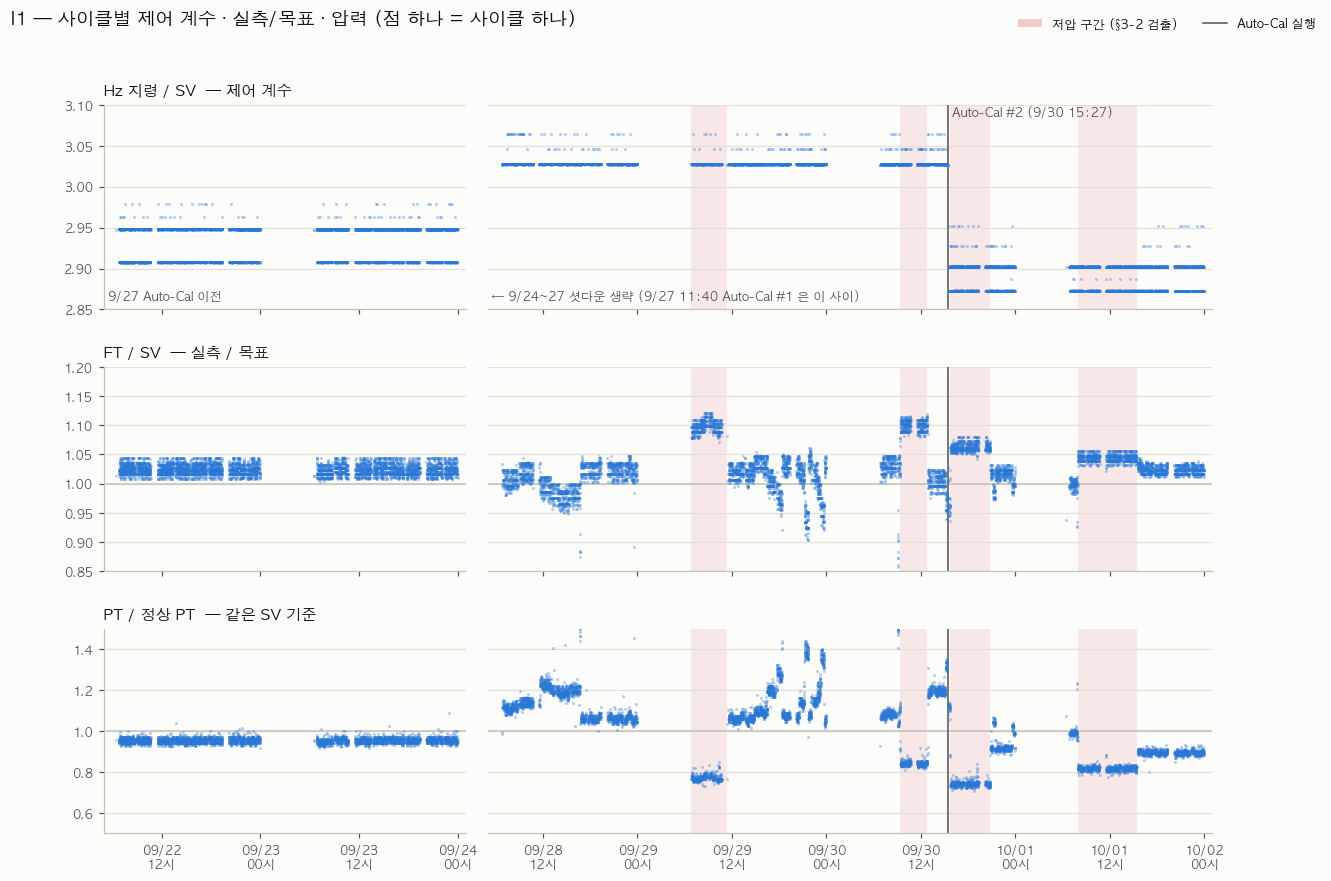

In [18]:
AUTOCAL = [(pd.Timestamp("2026-09-27 11:40:43"), "Auto-Cal #1 (9/27 11:40)"),
           (pd.Timestamp("2026-09-30 15:27:56"), "Auto-Cal #2 (9/30 15:27)")]
LEFT = (pd.Timestamp("2026-09-22 05:00"), pd.Timestamp("2026-09-24 01:00"))
RIGHT = (pd.Timestamp("2026-09-28 05:00"), pd.Timestamp("2026-10-02 01:00"))


def shade_episodes(ax, lo, hi):
    for s, e in EPISODES:
        if e >= lo and s <= hi:
            ax.axvspan(max(s, lo), min(e, hi), color=CRITICAL, alpha=0.10, lw=0, zorder=0)


panels = [("Hz_SV", "Hz 지령 / SV  — 제어 계수", (2.85, 3.10), None),
          ("FT_SV", "FT / SV  — 실측 / 목표", (0.85, 1.20), 1.0),
          ("PT_ratio", "PT / 정상 PT  — 같은 SV 기준", (0.5, 1.5), 1.0)]
fig, axes = plt.subplots(3, 2, figsize=(13, 8.6), sharex="col", sharey="row", facecolor=SURFACE,
                         gridspec_kw={"width_ratios": [2, 4], "wspace": 0.04, "hspace": 0.28})
for r, (col, title, ylim, ref) in enumerate(panels):
    for k, (lo, hi) in enumerate([LEFT, RIGHT]):
        ax = axes[r, k]
        style_ax(ax)
        shade_episodes(ax, lo, hi)
        if ref is not None:
            ax.axhline(ref, color=AXIS, lw=1, zorder=1)
        d = cyc[(cyc.t0 >= lo) & (cyc.t0 < hi)]
        ax.scatter(d.t0, d[col].clip(*ylim), s=4, color=BLUE, alpha=0.35, lw=0, zorder=3)
        for t, label in AUTOCAL:
            if lo <= t < hi:
                ax.axvline(t, color=INK2, lw=1, zorder=2)
                if r == 0:
                    ax.text(t, ylim[1], " " + label, color=INK2, fontsize=8, va="top", ha="left")
        ax.set_xlim(lo, hi)
        ax.set_ylim(*ylim)
        ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d\n%H시"))
        if k == 1:
            ax.spines["left"].set_visible(False)
            ax.tick_params(axis="y", left=False)
    axes[r, 0].set_title(title, loc="left", color=INK, fontsize=10, fontweight="bold")
axes[0, 0].text(LEFT[0], 2.86, " 9/27 Auto-Cal 이전", color=INK2, fontsize=8, va="bottom")
axes[0, 1].text(RIGHT[0], 2.86, " ← 9/24~27 셧다운 생략 (9/27 11:40 Auto-Cal #1 은 이 사이)", color=INK2,
                fontsize=8, va="bottom")
fig.legend(handles=[Patch(facecolor=CRITICAL, alpha=0.25, label="저압 구간 (§3-2 검출)"),
                    Line2D([], [], color=INK2, lw=1, label="Auto-Cal 실행")],
           loc="upper right", bbox_to_anchor=(0.98, 0.985), ncol=2, fontsize=8, frameon=False)
fig.suptitle("I1 — 사이클별 제어 계수 · 실측/목표 · 압력 (점 하나 = 사이클 하나)", x=0.06, ha="left",
             color=INK, fontsize=12, fontweight="bold")
plt.show()

읽는 법:
- **위 (Hz/SV)** — 계수는 Auto-Cal 때 **두 번만** 계단식으로 바뀐다(주된 줄 2.948 → 3.027 → 2.902). 빨간 구간에서는
  변화가 없다. 2~3줄로 갈라지는 건 SV 가 속한 Auto-Cal 구간(레시피)마다 구간계수가 달라서이고, 줄들이 Auto-Cal 때만
  함께 움직인다.
- **가운데 (FT/SV)** — 빨간 구간에서만 위로 뜬다.
- **아래 (PT)** — 같은 구간에서 정확히 같이 내려간다.

→ **제어 계수는 그대로인데 압력이 떨어지고 유량이 늘었다.** 9/29 오전의 원인은 계수가 아니다.

### 4-2. Hz/SV 줄들의 정체 — Auto-Cal 기록값으로 맞춰보기

Auto-Cal 은 k 번째 단계에서 `구간계수 = (Hz_k 의 아날로그값) / FT_k` 를 저장하고, 운전 중에는
`Hz = SV × 구간계수 × Gain` 을 쓴다. 아날로그 환산이 상쇄되므로 **Hz/SV = Gain × Hz_k / FT_k** 여야 한다.

In [19]:
CAL_FT = {"Auto-Cal #1 (9/27)": [1019, 1156, 1305], "Auto-Cal #2 (9/30)": [1044, 1206, 1355]}   # §2-3 의 Result 값
periods = {"Auto-Cal #1 (9/27)": ("2026-09-28", "2026-09-30 15:27"), "Auto-Cal #2 (9/30)": ("2026-09-30 15:28", "2026-10-02")}
rows = []
for name, fts in CAL_FT.items():
    a, b = periods[name]
    obs = cyc[(cyc.t0 >= a) & (cyc.t0 < b)].Hz_SV.round(3).value_counts(normalize=True)
    for k, (hz, ft) in enumerate(zip([3000, 3500, 4000], fts), 1):
        pred = hz / ft
        share = obs[np.abs(obs.index - pred) < 0.0015].sum()
        rows.append({"보정": name, "단계": f"{hz / 100:.0f} Hz", "기록 FT": ft, "Hz/FT (예측 Hz/SV)": round(pred, 4),
                     "이 값으로 운전한 사이클 비율": f"{share:.0%}"})
pd.DataFrame(rows)

,보정,단계,기록 FT,Hz/FT (예측 Hz/SV),이 값으로 운전한 사이클 비율
0,Auto-Cal #1 (9/27),30 Hz,1019,2.9441,0%
1,Auto-Cal #1 (9/27),35 Hz,1156,3.0277,97%
2,Auto-Cal #1 (9/27),40 Hz,1305,3.0651,1%
3,Auto-Cal #2 (9/30),30 Hz,1044,2.8736,38%
4,Auto-Cal #2 (9/30),35 Hz,1206,2.9022,60%
5,Auto-Cal #2 (9/30),40 Hz,1355,2.9520,1%


예측값과 실제 운전 중 Hz/SV 가 소수 셋째 자리까지 맞는다(위 그림 위 패널의 여러 줄이 바로 이 구간별 값).
0% 인 단계는 그 기간에 해당 구간으로 떨어지는 레시피 SV 가 없었던 것이다.
→ **운전 중 Hz 는 Auto-Cal 순간에 잰 "Hz 당 FT" 를 그대로 비례 적용한 것**이고, Gain 은 1.0 그대로다
(테스트샷 Gain Set 미실행 — §2-3 의 결정적 근거). 그래서 **Auto-Cal 은 누른 순간의 노즐 상태를 찍어 둔
사진**이고, 이후 노즐이 바뀌면 FT/SV 는 그대로 벌어진다.

참고로 Auto-Cal 을 안 쓸 때의 명판 이론식(`gs_Speed_Convert`)은 Hz/SV = `Pump_Hz_Max / Max_Capa` = 6000/2300 = **2.609** 다.
실제 보정값(2.87~3.07)은 이보다 10~18% 크다 — 유량계 기준으로 SV 를 내려면 명판 계산보다 더 돌려야 한다는 뜻이고,
그래서 명판값 대신 실측 보정을 쓰는 것이다.

---
## §5. FT 스케일은 그대로인가 — 펌프 슬립 곡선

용적식 펌프의 실토출량은 `Q = D·n − k·P` 다(D: 회전당 배제용적, n: 회전수, k·P: 압력에 비례하는 내부 누설).
양변을 n(=Hz) 으로 나누면:

$$\frac{FT}{Hz} = D - k \cdot \frac{PT}{Hz}$$

즉 **FT/Hz 는 PT/Hz 의 직선**이어야 한다. 만약 누가 `Imp_L`·비중을 바꿨다면 저압 구간의 점들은
이 직선에서 **통째로 몇 % 위로** 떠야 한다. 직선 위에 그대로 올라가면 FT 스케일은 그대로이고,
유량이 늘어난 건 **압력이 줄어서 누설이 줄어든 실제 현상**이다.

직선은 **저압 구간을 뺀 정상 사이클**로만 맞춘다(9/28~10/1, 9/29 오전과 같은 날들).

In [20]:
fit_base = cyc[(cyc.t0 >= "2026-09-28") & (cyc.EP == 0)]
b1, b0 = np.polyfit(fit_base.PTn, fit_base.FT_Hz, 1)
r_fit = np.corrcoef(fit_base.PTn, fit_base.FT_Hz)[0, 1]
cyc["slip_pred"] = b0 + b1 * cyc.PTn
cyc["slip_resid_pct"] = (cyc.FT_Hz / cyc.slip_pred - 1) * 100
print(f"정상 사이클 적합: FT/Hz = {b0:.4f} {b1:+.6f} × (PT/Hz×1000),  r = {r_fit:.3f},  n = {len(fit_base):,}")

grp = np.select([cyc.EP > 0, cyc.t0 < "2026-09-27"], ["저압 구간 " + cyc.EP.astype(str), "정상 9/22~23 (적합 미사용)"],
                "정상 9/28~10/1 (적합 사용)")
(cyc.assign(그룹=grp).groupby("그룹")
 .agg(사이클=("FT", "size"), FT_SV=("FT_SV", "median"), PT비=("PT_ratio", "median"),
      잔차_중앙값_pct=("slip_resid_pct", "median"), 잔차_표준편차_pct=("slip_resid_pct", "std"))
 .round(3))

정상 사이클 적합: FT/Hz = 0.4294 -0.003471 × (PT/Hz×1000),  r = -0.935,  n = 5,746


,사이클,FT_SV,PT비,잔차_중앙값_pct,잔차_표준편차_pct
그룹,,,,,
저압 구간 1,518,1.099,0.765,-0.764,0.813
저압 구간 2,375,1.099,0.841,0.971,0.634
저압 구간 3,554,1.061,0.739,0.730,0.596
저압 구간 4,843,1.046,0.819,0.690,0.490
정상 9/22~23 (적합 미사용),5020,1.024,0.955,0.657,0.773
정상 9/28~10/1 (적합 사용),5747,1.017,1.076,0.169,1.200


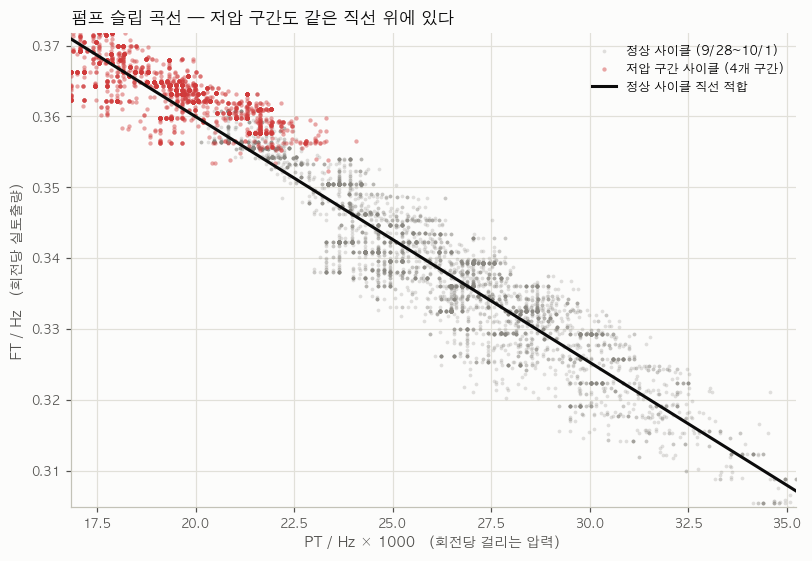

In [21]:
fig, ax = plt.subplots(figsize=(8.5, 5.6), facecolor=SURFACE)
style_ax(ax)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
nrm = cyc[(cyc.t0 >= "2026-09-28") & (cyc.EP == 0)]
epi = cyc[cyc.EP > 0]
ax.scatter(nrm.PTn, nrm.FT_Hz, s=6, color=MUTED, alpha=0.25, lw=0, zorder=2, label="정상 사이클 (9/28~10/1)")
ax.scatter(epi.PTn, epi.FT_Hz, s=8, color=CRITICAL, alpha=0.45, lw=0, zorder=3, label="저압 구간 사이클 (4개 구간)")
xs = np.linspace(cyc.PTn.quantile(0.002), cyc.PTn.quantile(0.998), 50)
ax.plot(xs, b0 + b1 * xs, color=INK, lw=2, zorder=4, label="정상 사이클 직선 적합")
ax.set_xlim(xs.min(), xs.max())
ax.set_ylim(cyc.FT_Hz.quantile(0.002), cyc.FT_Hz.quantile(0.998))
ax.set_xlabel("PT / Hz × 1000   (회전당 걸리는 압력)", color=INK2, fontsize=9)
ax.set_ylabel("FT / Hz   (회전당 실토출량)", color=INK2, fontsize=9)
ax.set_title("펌프 슬립 곡선 — 저압 구간도 같은 직선 위에 있다", loc="left", color=INK, fontsize=11,
             fontweight="bold")
ax.legend(loc="upper right", fontsize=8, frameon=False)
plt.show()

- 정상 사이클은 직선 하나로 잘 설명된다(r ≈ −0.94).
- **저압 구간의 점들도 같은 직선 위에 있다** — 잔차 중앙값이 ±1% 안이고, 정상 산포 수준이다.
  계측 스케일이 바뀌었다면 7~9% 위로 떠 있어야 한다.
- 9/22~23(적합에 안 쓴 다른 날)도 같은 직선에 올라간다 → **FT 계측은 기간 내내 일관됐다.**

> **결론: FT 는 거짓말을 하지 않았다.** 압력이 떨어진 만큼 펌프가 실제로 더 토출했고, 유량계가 그걸 잰 것이다.

---
## §6. 9/29 전환 순간 확대

SV = 1210 사이클만 골라서(같은 레시피끼리 비교) 9/28 밤 ~ 9/29 점심을 본다.

직전 정상 사이클: 2026-09-28 23:56:41.404566  →  저압 첫 사이클: 2026-09-29 06:50:25.776724
저압 마지막 사이클: 2026-09-29 11:21:36.220536  →  복귀 첫 사이클: 2026-09-29 11:22:50.254296
■ 5분 넘는 펌프 정지 (FT = 0)
                         min                        max                     길이
0 2026-09-28 23:58:51.538742 2026-09-29 06:13:05.497849 0 days 06:14:13.959107
1 2026-09-29 11:04:26.723257 2026-09-29 11:17:54.702429 0 days 00:13:27.979172

재가동 직후 순환운전(첫 40틱) 중앙값: PT 24, FT 733  (정상 순환은 PT 36 / FT 722 — §7-3)


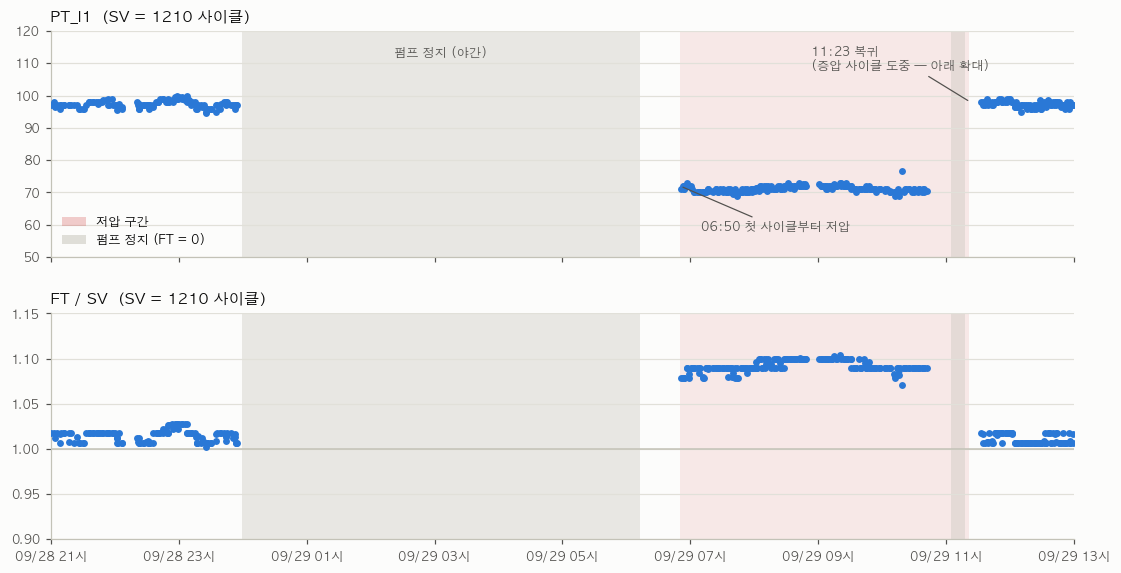

In [22]:
lo, hi = pd.Timestamp("2026-09-28 21:00"), pd.Timestamp("2026-09-29 13:00")
z = cyc[(cyc.t0 >= lo) & (cyc.t0 < hi) & (cyc.SV == 1210)]
ep_s, ep_e = EPISODES[0]
last_before = cyc[cyc.t0 < ep_s].t0.max()
first_after = cyc[cyc.t0 > ep_e].t0.min()
print(f"직전 정상 사이클: {last_before}  →  저압 첫 사이클: {ep_s}")
print(f"저압 마지막 사이클: {cyc[cyc.EP == 1].t0.max()}  →  복귀 첫 사이클: {first_after}")

# 펌프 정지 = FT 가 0 인 구간. 정지 중에도 Hz 지령은 순환값(2000) 으로 남아 있어서 Hz 로는 못 잡는다.
w = df[(df.Time >= lo) & (df.Time < hi)]
zero = w.Scale_Out___FT_I1 == 0
run = (zero != zero.shift()).cumsum()
stops = w[zero].groupby(run[zero]).Time.agg(["min", "max"])
stops["길이"] = stops["max"] - stops["min"]
stops = stops[stops["길이"] > pd.Timedelta(minutes=5)].reset_index(drop=True)
print("■ 5분 넘는 펌프 정지 (FT = 0)")
print(stops.to_string())
pump_off = (stops.loc[0, "min"], stops.loc[0, "max"])
restart = w[(w.Time > pump_off[1]) & (w.Scale_Out___FT_I1 > 300)].head(40)
print(f"\n재가동 직후 순환운전(첫 40틱) 중앙값: PT {restart.Scale_Out___PT_I1.median():.0f}, "
      f"FT {restart.Scale_Out___FT_I1.median():.0f}  (정상 순환은 PT 36 / FT 722 — §7-3)")

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, facecolor=SURFACE,
                         gridspec_kw={"hspace": 0.25})
for ax, (col, title, ref) in zip(axes, [("PT", "PT_I1  (SV = 1210 사이클)", None),
                                        ("FT_SV", "FT / SV  (SV = 1210 사이클)", 1.0)]):
    style_ax(ax)
    shade_episodes(ax, lo, hi)
    for _, s in stops.iterrows():
        ax.axvspan(s["min"], s["max"], color=AXIS, alpha=0.35, lw=0, zorder=0)
    if ref is not None:
        ax.axhline(ref, color=AXIS, lw=1, zorder=1)
    ax.plot(z.t0, z[col], "o", ms=3.5, color=BLUE, zorder=3)
    ax.set_title(title, loc="left", color=INK, fontsize=10, fontweight="bold")
    ax.set_xlim(lo, hi)
axes[0].set_ylim(50, 120)
axes[1].set_ylim(0.9, 1.15)
if pump_off:
    axes[0].text(pump_off[0] + (pump_off[1] - pump_off[0]) / 2, 115, "펌프 정지 (야간)", color=INK2,
                 fontsize=8, ha="center", va="top")
axes[0].annotate(f"{ep_s:%H:%M} 첫 사이클부터 저압", xy=(ep_s, 72), xytext=(ep_s + pd.Timedelta(minutes=20), 58),
                 color=INK2, fontsize=8, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
axes[0].annotate("11:23 복귀\n(증압 사이클 도중 — 아래 확대)",
                 xy=(first_after, 98), xytext=(first_after - pd.Timedelta(minutes=150), 108),
                 color=INK2, fontsize=8, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
axes[1].xaxis.set_major_locator(mdates.HourLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%d %H시"))
axes[0].legend(handles=[Patch(facecolor=CRITICAL, alpha=0.25, label="저압 구간"),
                        Patch(facecolor=AXIS, alpha=0.5, label="펌프 정지 (FT = 0)")],
               loc="lower left", fontsize=8, frameon=False)
plt.show()

- **시작**: 9/28 23:58 펌프 정지 → 9/29 06:13 재가동. **재가동 첫 순환운전부터 이미 저압**이다(PT 23~25).
  서서히 변한 게 아니라 **야간 정지 중에 바뀌었다.**
- 11:04~11:18 에 13분짜리 정지가 한 번 더 있는데, 그 뒤에도 여전히 저압이다 → 복귀는 이 정지 중이 아니다.
- **복귀**: 11:22:50 에 시작한 증압 사이클 **도중에** 일어났다. 틱 단위로 보면:

                      Time  Pump_BuildUp_I1  Hz_Out_I1  Scale_Out___FT_I1  Scale_Out___PT_I1    K
2026-09-29 11:23:00.237137              1.0     3935.0             1405.0               82.0 4.15
2026-09-29 11:23:00.763138              1.0     3935.0             1405.0               80.0 4.05
2026-09-29 11:23:01.290822              1.0     3935.0             1405.0               77.0 3.90
2026-09-29 11:23:01.815991              1.0     3935.0             1405.0               79.0 4.00
2026-09-29 11:23:02.330426              1.0     3935.0             1417.0               88.0 4.38
2026-09-29 11:23:02.840842              1.0     3935.0             1417.0               89.0 4.43
2026-09-29 11:23:03.361883              1.0     3935.0             1380.0               89.0 4.67
2026-09-29 11:23:04.390496              1.0     3935.0             1380.0               90.0 4.73
2026-09-29 11:23:04.911502              1.0     3935.0             1380.0               94.0 4.94
2026-09-29 11:23:05.

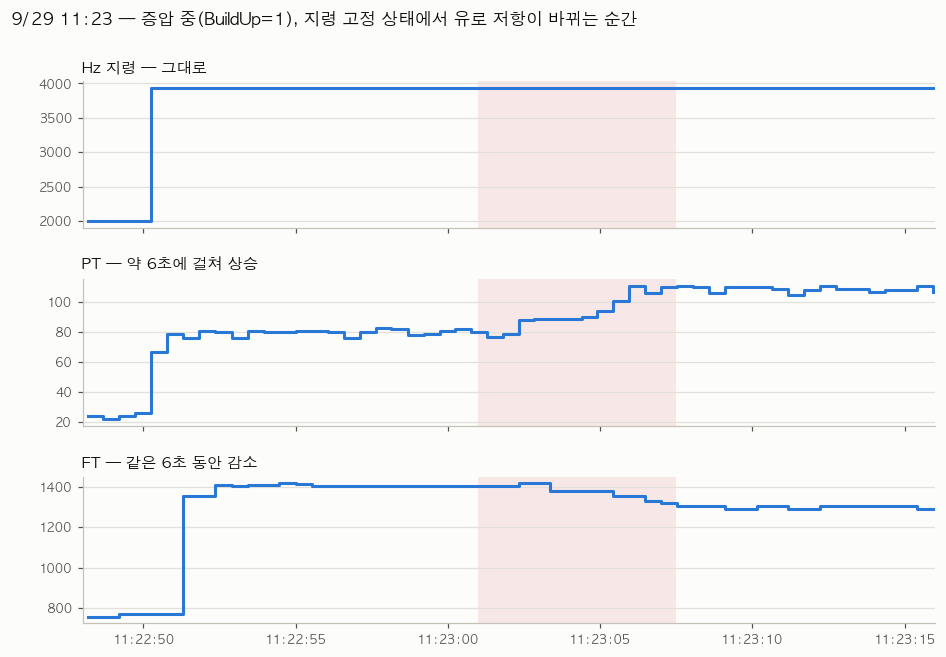

In [23]:
lo, hi = pd.Timestamp("2026-09-29 11:22:48"), pd.Timestamp("2026-09-29 11:23:16")
t = df[(df.Time >= lo) & (df.Time < hi)].copy()
t["K"] = (t.Scale_Out___PT_I1 / t.Scale_Out___FT_I1.replace(0, np.nan) ** 2 * 1e5).round(2)
ramp = t[(t.Time >= "2026-09-29 11:23:00") & (t.Time < "2026-09-29 11:23:09")]
print(ramp[["Time", "Pump_BuildUp_I1", "Hz_Out_I1", "Scale_Out___FT_I1", "Scale_Out___PT_I1", "K"]]
      .drop_duplicates(subset=["Hz_Out_I1", "Scale_Out___FT_I1", "Scale_Out___PT_I1"]).to_string(index=False))

fig, axes = plt.subplots(3, 1, figsize=(10, 6.4), sharex=True, facecolor=SURFACE, gridspec_kw={"hspace": 0.35})
for ax, (col, title) in zip(axes, [("Hz_Out_I1", "Hz 지령 — 그대로"), ("Scale_Out___PT_I1", "PT — 약 6초에 걸쳐 상승"),
                                   ("Scale_Out___FT_I1", "FT — 같은 6초 동안 감소")]):
    style_ax(ax)
    ax.axvspan(pd.Timestamp("2026-09-29 11:23:01"), pd.Timestamp("2026-09-29 11:23:07.5"), color=CRITICAL,
               alpha=0.10, lw=0, zorder=0)
    ax.step(t.Time, t[col], where="post", color=BLUE, lw=2, zorder=3)
    ax.set_title(title, loc="left", color=INK, fontsize=10, fontweight="bold")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
axes[2].set_xlim(lo, hi)
fig.suptitle("9/29 11:23 — 증압 중(BuildUp=1), 지령 고정 상태에서 유로 저항이 바뀌는 순간", x=0.06, ha="left",
             color=INK, fontsize=11, fontweight="bold")
plt.show()

- **Hz 지령은 3935 그대로**인데, 11:23:01 → 11:23:07 사이 **약 6초에 걸쳐** PT 77 → 110, FT 1405 → 1305,
  K 3.9 → 6.5 로 바뀐다. 이 사이클의 앞부분은 저압, 뒷부분은 정상이다.
- 제어 지령이 그대로이니 PLC 가 한 일이 아니다. 운전 중에 **하류 저항이 6초에 걸쳐 조여진 것**이다.
  솔레노이드 밸브 전환(1초 이내)보다는 **사람이 노즐 나사나 수동 밸브를 돌리는 속도**에 가깝다(추정).
- 다른 전환들은 사이클 시작의 과도구간과 겹쳐서 틱 단위로 이렇게 깔끔하게 잘리지 않았다. 여기서는 9/29 만 확정한다.

### 6-2. 9/30 15:27 Auto-Cal 전후 — 노즐 조정과 Auto-Cal 이 한 세션

§2-4 의 9/30 실행을 분 단위로 본다. K(= PT/FT² × 10⁵, 유로 저항)는 Hz·SV 와 무관하게 저항 자체를 보여주므로
증압·순환·Auto-Cal 스텝을 가리지 않고 한 축에 놓을 수 있다. 정상은 6.5 근처, 클수록 꽉 조인 상태다.

자동운전 정지 15:23:09 → Auto-Cal 15:27:26~15:27:56 → 자동운전 재개 15:30:31


,구간,시각,K 중앙값,K 범위(분 중앙값),FT/SV (안정 사이클),사이클
0,정상 운전,14:50:00~15:08:00,7.63,7.6~7.9,1.005,45
1,15:08 이후 ~ 자동 정지,15:08:00~15:23:09,9.19,7.9~9.3,0.970,37
2,자동 정지 중 (Auto-Cal 전),15:23:09~15:27:26,7.50,6.3~9.3,1.004,3
3,Auto-Cal 중,15:27:26~15:27:56,6.16,6.2~6.2,NaN,0
4,재개 직후,15:30:31~15:41:00,7.86,6.9~8.0,0.960,21
5,15:44 이후,15:44:00~16:00:00,4.29,4.2~4.4,1.060,33


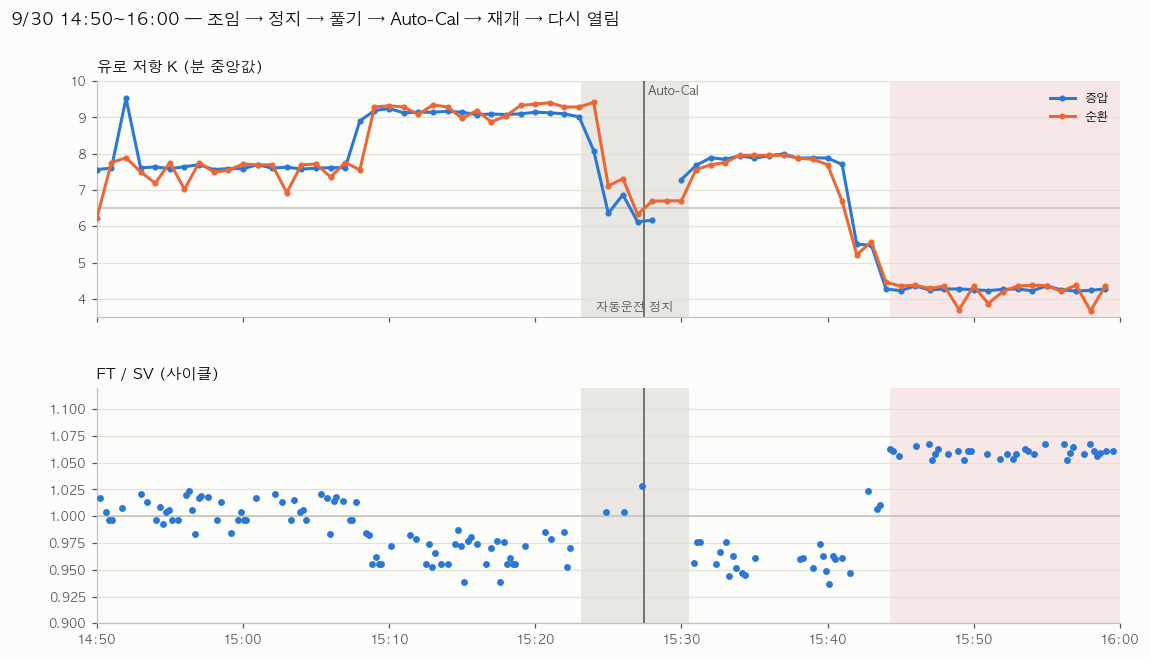

In [24]:
r930 = cal_runs[cal_runs["시작"].dt.date == pd.Timestamp("2026-09-30").date()].iloc[0]
AUTO_OFF, AUTO_ON, CAL_T0 = r930["자동운전_정지"], r930["자동운전_재개"], r930["시작"]
CAL_T1 = CAL_T0 + pd.Timedelta(seconds=int(r930["소요_초"]))
print(f"자동운전 정지 {AUTO_OFF:%H:%M:%S} → Auto-Cal {CAL_T0:%H:%M:%S}~{CAL_T1:%H:%M:%S} → 자동운전 재개 {AUTO_ON:%H:%M:%S}")

lo, hi = pd.Timestamp("2026-09-30 14:50"), pd.Timestamp("2026-09-30 16:00")
w = df[(df.Time >= lo) & (df.Time < hi) & (df.Scale_Out___FT_I1 > 300)].copy()
w["K"] = w.Scale_Out___PT_I1 / w.Scale_Out___FT_I1 ** 2 * 1e5
w["mode"] = np.where(w.Pump_BuildUp_I1 == 1, "증압", np.where(w.Hz_Out_I1 == 2000, "순환", "Auto-Cal 스텝"))
km = w.groupby([w.Time.dt.floor("min"), "mode"]).K.median().unstack()
cz = cyc[(cyc.t0 >= lo) & (cyc.t0 < hi)]

windows = [("14:50", "15:08", "정상 운전"), ("15:08", AUTO_OFF, "15:08 이후 ~ 자동 정지"),
           (AUTO_OFF, CAL_T0, "자동 정지 중 (Auto-Cal 전)"), (CAL_T0, CAL_T1, "Auto-Cal 중"),
           (AUTO_ON, "15:41", "재개 직후"), ("15:44", "16:00", "15:44 이후")]
rows = []
for a, b, name in windows:
    a = pd.Timestamp(f"2026-09-30 {a}") if isinstance(a, str) else a
    b = pd.Timestamp(f"2026-09-30 {b}") if isinstance(b, str) else b
    ww, cc = w[(w.Time >= a) & (w.Time < b)], cz[(cz.t0 >= a) & (cz.t0 < b)]
    rows.append({"구간": name, "시각": f"{a:%H:%M:%S}~{b:%H:%M:%S}", "K 중앙값": round(ww.K.median(), 2),
                 "K 범위(분 중앙값)": f"{ww.groupby(ww.Time.dt.floor('min')).K.median().min():.1f}~"
                                      f"{ww.groupby(ww.Time.dt.floor('min')).K.median().max():.1f}",
                 "FT/SV (안정 사이클)": round(cc.FT_SV.median(), 3) if len(cc) else None, "사이클": len(cc)})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True, facecolor=SURFACE, gridspec_kw={"hspace": 0.3})
for ax in axes:
    style_ax(ax)
    shade_episodes(ax, lo, hi)
    ax.axvspan(AUTO_OFF, AUTO_ON, color=AXIS, alpha=0.35, lw=0, zorder=0)
    ax.axvline(CAL_T0, color=INK2, lw=1, zorder=2)
for col, color in [("증압", BLUE), ("순환", ORANGE)]:
    axes[0].plot(km.index, km[col], color=color, lw=2, marker="o", ms=3, zorder=3, label=col)
axes[0].axhline(6.5, color=AXIS, lw=1, zorder=1)
axes[0].set_ylim(3.5, 10)
axes[0].set_title("유로 저항 K (분 중앙값)", loc="left", color=INK, fontsize=10, fontweight="bold")
axes[0].text(CAL_T0, 9.9, " Auto-Cal", color=INK2, fontsize=8, va="top")
axes[0].text(AUTO_OFF + (AUTO_ON - AUTO_OFF) / 2, 3.6, "자동운전 정지", color=INK2, fontsize=8, ha="center", va="bottom")
axes[0].legend(loc="upper right", fontsize=8, frameon=False)
axes[1].axhline(1.0, color=AXIS, lw=1, zorder=1)
axes[1].plot(cz.t0, cz.FT_SV, "o", ms=3.5, color=BLUE, zorder=3)
axes[1].set_ylim(0.9, 1.12)
axes[1].set_title("FT / SV (사이클)", loc="left", color=INK, fontsize=10, fontweight="bold")
axes[1].xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, 10)))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[1].set_xlim(lo, hi)
fig.suptitle("9/30 14:50~16:00 — 조임 → 정지 → 풀기 → Auto-Cal → 재개 → 다시 열림", x=0.06, ha="left",
             color=INK, fontsize=11, fontweight="bold")
plt.show()

| 순서 | 일어난 일 | 결과 |
|---|---|---|
| 1 | 15:08 경 생산 중에 저항이 커진다 (K 7.6 → 9 대) | FT/SV 0.97 — **덜 나온다** |
| 2 | 15:23 자동운전 정지 | |
| 3 | 정지 중 15:24~25 에 저항이 풀린다 (K 9 대 → 7 → 6 대) | 노즐을 연 것으로 추정 |
| 4 | 15:27 **Auto-Cal** — 이 순간의 저항(K ≈ 6.1~6.3)이 계수 표에 박힌다 | Hz/SV 3.027 → 2.902 (−4%) |
| 5 | 15:30 자동운전 재개. 저항이 보정 때보다 조금 큰 상태(K 7~8) | FT/SV 0.96 — **또 덜 나온다** |
| 6 | 15:41~44 생산 중 단계적으로 열린다 (K → 5 → 4 대) | FT/SV 1.06 — **이번엔 더 나온다**, 20:48 까지 |

30분 남짓 사이에 **조임 → 정지 → 풀기 → Auto-Cal → 재개 → 다시 풀기**가 이어진다. 누군가 FT 가 SV 와 안 맞는 걸
보고 노즐과 Auto-Cal 을 오가며 맞추려 한 흐름으로 읽힌다. 단 15:08 의 저항 증가가 사람이 조인 건지 부분 막힘인지,
3·6 이 노즐 조작인지는 PLC 신호로는 구분되지 않는다(추정). 확실한 건 **보정 후에 저항이 또 바뀌어서 보정이 무의미해졌다**는 점이다.

---
## §7. 원인 위치 좁히기

### 7-1. 같은 헤드의 POL(P1) 은?

P1 과 I1 은 같은 HD1 헤드에 붙는 짝이다. 레시피·금형·헤드 전체의 문제라면 P1 도 같이 움직여야 한다.
레시피 하나씩(I1 SV=1210, P1 SV=2680 — 각자 가장 많은 SV) 골라 9/28 18~24시 대비 PT 를 지수로 본다.

In [25]:
P1_TAGS = ["Pump_BuildUp_P1", "g_s_SV_P1", "Scale_Out___FT_P1", "Scale_Out___PT_P1", "Scale_Out___PT_HD_P1",
           "Hz_Out_P1", "Scale_Out___TT_P1"]
p1 = cached("ftsv_P1_20260928_20261001", lambda: extractor().get_data(AUX_START, AUX_END, P1_TAGS))
p = p1.ffill().reset_index()
p = p[(p.Pump_BuildUp_P1 == 1) & (p.g_s_SV_P1 > 0) & (p.Hz_Out_P1 > 0)].copy()
p["hz_grp"] = (p.Hz_Out_P1.diff().fillna(0) != 0).cumsum()
p = p[p.groupby("hz_grp").cumcount() >= STEADY_MIN]
p["FT_SV"] = p.Scale_Out___FT_P1 / p.g_s_SV_P1
P1_SV = p.g_s_SV_P1.value_counts().index[0]

hourly = pd.DataFrame({
    "I1_PT": ticks[ticks.SV == 1210].groupby(ticks.Time.dt.floor("h")).PT.median(),
    "I1_FT_SV": ticks[ticks.SV == 1210].groupby(ticks.Time.dt.floor("h")).FT_SV.median(),
    "P1_PT": p[p.g_s_SV_P1 == P1_SV].groupby(p.Time.dt.floor("h")).Scale_Out___PT_P1.median(),
    "P1_FT_SV": p[p.g_s_SV_P1 == P1_SV].groupby(p.Time.dt.floor("h")).FT_SV.median(),
    "n_P1": p[p.g_s_SV_P1 == P1_SV].groupby(p.Time.dt.floor("h")).size(),
}).loc[AUX_START:AUX_END]
hourly = hourly[hourly.n_P1 >= 200].drop(columns="n_P1")
ref = hourly.loc["2026-09-28 18:00":"2026-09-28 23:59"].median()
hourly["I1_PT지수"] = hourly.I1_PT / ref.I1_PT
hourly["P1_PT지수"] = hourly.P1_PT / ref.P1_PT
print(f"P1 비교 레시피 SV = {P1_SV:.0f}")
hourly.round(3)

[cache] ftsv_P1_20260928_20261001
P1 비교 레시피 SV = 2680


,I1_PT,I1_FT_SV,P1_PT,P1_FT_SV,I1_PT지수,P1_PT지수
Time,,,,,,
2026-09-28 18:00:00,97.0,1.017,124.0,0.997,1.000,1.000
2026-09-28 20:00:00,98.0,1.017,124.0,0.997,1.010,1.000
2026-09-28 21:00:00,97.0,1.017,124.0,0.997,1.000,1.000
2026-09-28 22:00:00,97.0,1.017,124.0,0.997,1.000,1.000
2026-09-28 23:00:00,97.0,1.016,124.0,0.997,1.000,1.000
2026-09-29 07:00:00,70.0,1.089,124.0,0.997,0.722,1.000
2026-09-29 08:00:00,72.0,1.099,124.0,0.997,0.742,1.000
2026-09-29 09:00:00,72.0,1.099,124.0,0.997,0.742,1.000
2026-09-29 10:00:00,70.0,1.089,124.0,0.997,0.722,1.000


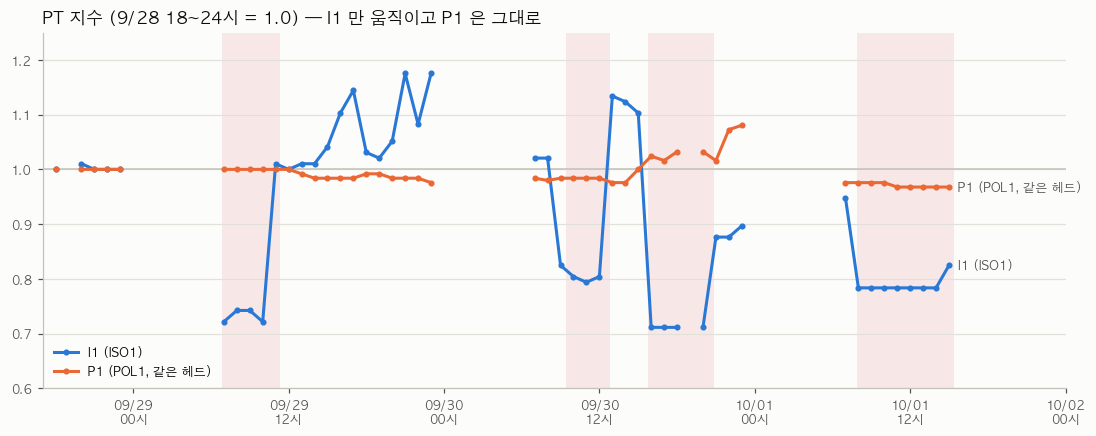

In [26]:
full = hourly[["I1_PT지수", "P1_PT지수"]].asfreq("h")    # 빈 시간은 NaN 으로 → 선이 끊긴다
lo, hi = full.index.min() - pd.Timedelta(hours=1), full.index.max() + pd.Timedelta(hours=1)
fig, ax = plt.subplots(figsize=(12, 4.2), facecolor=SURFACE)
style_ax(ax)
shade_episodes(ax, lo, hi)
ax.axhline(1.0, color=AXIS, lw=1, zorder=1)
for col, color, name in [("I1_PT지수", BLUE, "I1 (ISO1)"), ("P1_PT지수", ORANGE, "P1 (POL1, 같은 헤드)")]:
    ax.plot(full.index, full[col], color=color, lw=2, marker="o", ms=3, zorder=3, label=name)
    last = full[col].dropna()
    ax.text(last.index[-1] + pd.Timedelta(minutes=40), last.iloc[-1], name, color=INK2, fontsize=8, va="center")
ax.set_xlim(lo, hi + pd.Timedelta(hours=8))
ax.set_ylim(0.6, 1.25)
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d\n%H시"))
ax.set_title("PT 지수 (9/28 18~24시 = 1.0) — I1 만 움직이고 P1 은 그대로", loc="left", color=INK,
             fontsize=11, fontweight="bold")
ax.legend(loc="lower left", fontsize=8, frameon=False)
plt.show()

**P1 은 저압 구간과 무관하다.** PT 지수는 0.97~1.08 안에서 I1 과 상관없이 움직이고, FT/SV 는 0.99~1.00 그대로다.
→ 레시피·금형·헤드 전체가 아니라 **ISO1 라인에만 생긴 변화**다.

### 7-2. ISO1 라인의 다른 신호 — 스케일 계수, 탱크 레벨, 온도

In [27]:
I1X_TAGS = ["Pump_BuildUp_I1", "g_s_SV_I1", "Scale_Out___PT_I1", "Scale_Out___PT_HD_I1", "Scale_Out___LT_I1",
            "Scale_Out___LT_STK_I1", "Scale_Out___TT_EX_I1", "Scale_Out___TT_JK_I1", "Scale_Out___TT_STK_I1",
            "Scale_Out___TT_I1", "Gain___PT_I1", "OffSet___PT_I1", "Scale_Max___PT_I1", "Gain___PT_HD_I1",
            "OffSet___PT_HD_I1", "Scale_Max___PT_HD_I1", "Para_DM_Press_H_Set_I1", "Para_DM_Press_L_Set_I1",
            "Pump_Cir_SPD_Set_I1"]
i1x = cached("ftsv_I1_aux_20260928_20261001", lambda: extractor().get_data(AUX_START, AUX_END, I1X_TAGS))
x = i1x.ffill()
CONST = ["Gain___PT_I1", "OffSet___PT_I1", "Scale_Max___PT_I1", "Para_DM_Press_H_Set_I1",
         "Para_DM_Press_L_Set_I1", "Pump_Cir_SPD_Set_I1"]
print("■ PT 스케일 · 압력 알람 설정 · 순환속도 — 기간 내 고유값")
for t in CONST:
    print(f"  {t:26s} {sorted(x[t].dropna().unique())}")

x = x.reset_index()
x = x[(x.Pump_BuildUp_I1 == 1) & (x.g_s_SV_I1 == 1210)].copy()
x["상태"] = "정상"
for s, e in EPISODES:
    x.loc[(x.Time >= s) & (x.Time <= e), "상태"] = "저압 구간"
cols = {"Scale_Out___PT_I1": "PT", "Scale_Out___LT_I1": "탱크레벨", "Scale_Out___TT_I1": "재료온도"}
print("\n■ SV=1210 증압 중 중앙값 (PT_HD·TT_EX·TT_JK·STK 는 이 라인에서 0 = 미사용 채널)")
x.groupby("상태")[list(cols)].median().rename(columns=cols)

[cache] ftsv_I1_aux_20260928_20261001
■ PT 스케일 · 압력 알람 설정 · 순환속도 — 기간 내 고유값
  Gain___PT_I1               [np.float64(1000.0)]
  OffSet___PT_I1             [np.float64(0.0)]
  Scale_Max___PT_I1          [np.float64(450.0)]
  Para_DM_Press_H_Set_I1     [np.float64(200.0)]
  Para_DM_Press_L_Set_I1     [np.float64(30.0)]
  Pump_Cir_SPD_Set_I1        [np.float64(2000.0)]

■ SV=1210 증압 중 중앙값 (PT_HD·TT_EX·TT_JK·STK 는 이 라인에서 0 = 미사용 채널)


,PT,탱크레벨,재료온도
상태,,,
저압 구간,73.0,60.0,217.5
정상,99.0,61.0,217.0


- PT 스케일 계수(`Gain/OffSet/Scale_Max___PT_I1`)는 그대로 → **PT 가 낮게 찍힌 건 실제 압력이 낮아서**다.
- 탱크 레벨·재료온도도 정상 구간과 같다 → 점도·흡입 조건 변화가 아니다.
- 헤드측 압력(`PT_HD_I1`) 채널은 이 설비에서 0(미사용)이라, 펌프 출구 PT 하나로 판단해야 한다.

### 7-3. 순환운전(20 Hz 고정) — SV 도, 보정계수도 안 쓰는 운전

증압이 아닐 때 펌프는 `Pump_Cir_SPD_Set_I1` = 2000 (20.00 Hz) 고정으로 순환한다. 여기에는 SV 도 Auto-Cal 계수도
**전혀 개입하지 않는다.** 이 운전에서도 같은 변화가 보이면, 원인은 제어가 아니라 유로(배관/노즐) 쪽이다.

추가로 오리피스(노즐) 압력손실은 `ΔP ∝ Q²` 이므로 **`K = PT / FT²` 는 유로 저항 그 자체**다.
증압과 순환에서 K 가 같은 값으로 같이 움직이면 **두 운전이 같은 저항을 지난다**는 뜻이다.

In [28]:
circ = df[(df.Pump_BuildUp_I1 == 0) & (df.Hz_Out_I1 == 2000) & (df.Scale_Out___FT_I1 > 0)].copy()
circ["K"] = circ.Scale_Out___PT_I1 / circ.Scale_Out___FT_I1 ** 2 * 1e5
circ["상태"] = "정상"
for s, e in EPISODES:
    circ.loc[(circ.Time >= s) & (circ.Time <= e), "상태"] = "저압 구간"
cyc["상태"] = np.where(cyc.EP > 0, "저압 구간", "정상")

sub_c = circ[circ.Time >= "2026-09-28"]
sub_b = cyc[cyc.t0 >= "2026-09-28"]
pd.concat({
    "순환 20Hz": sub_c.groupby("상태").agg(PT=("Scale_Out___PT_I1", "median"), FT=("Scale_Out___FT_I1", "median"),
                                         K=("K", "median")),
    "증압 (전 SV)": sub_b.groupby("상태").agg(PT=("PT", "median"), FT=("FT", "median"), K=("K", "median")),
}).round(2)

PT       FT     K
          상태                        
순환 20Hz   저압 구간  27.0   758.00  4.53
          정상     36.0   722.00  6.68
증압 (전 SV) 저압 구간  63.0  1187.75  4.43
          정상     87.5  1137.50  6.54

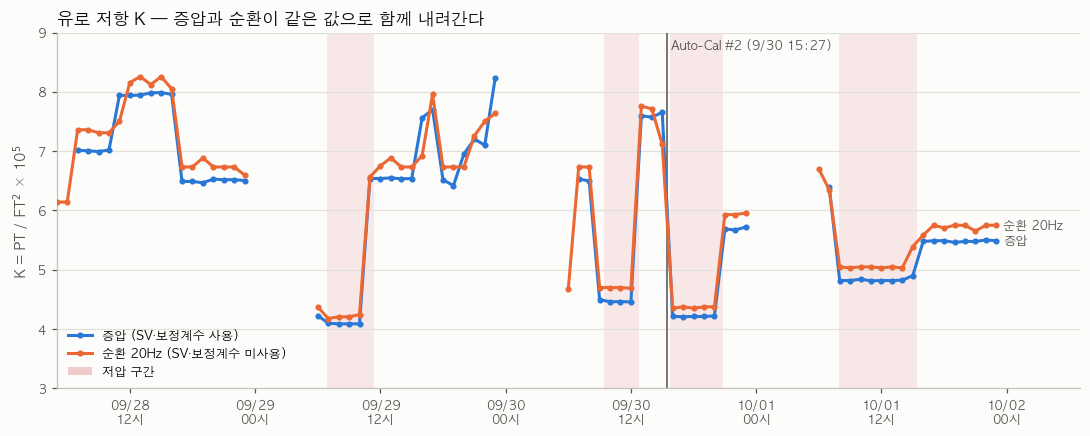

In [29]:
lo, hi = pd.Timestamp("2026-09-28 05:00"), pd.Timestamp("2026-10-02 01:00")
kb = cyc.set_index("t0").K.loc[lo:hi].resample("h").median()
kc = circ.set_index("Time").K.loc[lo:hi].resample("h").median()
nb_ = cyc.set_index("t0").K.loc[lo:hi].resample("h").size()
nc_ = circ.set_index("Time").K.loc[lo:hi].resample("h").size()
kb, kc = kb.where(nb_ >= 20), kc.where(nc_ >= 500)

fig, ax = plt.subplots(figsize=(12, 4.2), facecolor=SURFACE)
style_ax(ax)
shade_episodes(ax, lo, hi)
for s, color, name in [(kb, BLUE, "증압 (SV·보정계수 사용)"), (kc, ORANGE, "순환 20Hz (SV·보정계수 미사용)")]:
    ax.plot(s.index, s.values, color=color, lw=2, marker="o", ms=3, zorder=3, label=name)
    last = s.dropna()
    ax.text(last.index[-1] + pd.Timedelta(minutes=40), last.iloc[-1], name.split(" (")[0], color=INK2,
            fontsize=8, va="center")
for t, label in AUTOCAL:
    if lo <= t < hi:
        ax.axvline(t, color=INK2, lw=1, zorder=2)
        ax.text(t, 8.9, " " + label, color=INK2, fontsize=8, va="top")
ax.set_xlim(lo, hi + pd.Timedelta(hours=6))
ax.set_ylim(3, 9)
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d\n%H시"))
ax.set_ylabel(r"K = PT / FT$^2$ × 10$^5$", color=INK2, fontsize=9)
ax.set_title("유로 저항 K — 증압과 순환이 같은 값으로 함께 내려간다", loc="left", color=INK, fontsize=11,
             fontweight="bold")
ax.legend(handles=ax.get_legend_handles_labels()[0] + [Patch(facecolor=CRITICAL, alpha=0.25, label="저압 구간")],
          loc="lower left", fontsize=8, frameon=False)
plt.show()

- **순환운전(20 Hz 고정)에서도** 저압 구간마다 PT 가 내려가고 FT 가 올라간다. SV·Auto-Cal 이 개입하지 않는 운전이므로
  **제어 계수 원인은 완전히 배제된다.**
- 증압과 순환의 K 가 **같은 수준에서 같이** 내려간다(정상 6.5~6.7 → 저압 4.4~4.5, 약 −32%)
  → 두 운전이 지나는 **같은 저항(오리피스형)이 열렸다.** K 가 1/3 줄었다는 건 유효 단면적이 약 20% 넓어진 것과
  같다($A \propto 1/\sqrt{K}$).
- 9/29 은 06:13 재가동 직후 순환운전부터 이미 K 가 낮았다 → **야간 정지 중에 바뀐 것**이다(§6 과 일치).
- **K 는 정상값 하나가 아니다.** 4.2 · 4.8 · 5.5 · 6.5 · 7.0 · 8.0 처럼 여러 수준을 오가고, 수준마다 평평하다.
  반대 방향도 있다 — 9/28 오후, 9/29 밤처럼 K 가 8 근처로 **높을 때는 FT/SV 가 0.94~0.98 로 덜 토출**된다(§3-3 표).
  즉 이 저항은 **수시로 조정되는 값**이고, 9/29 오전은 그중 가장 크게 열린 경우다.
- 증압·순환이 공통으로 지나는 오리피스형 저항은 **헤드의 ISO 노즐**이 가장 유력하다(고압 순환은 노즐을 통해 돈다).
  계단식으로 여러 수준에 고정되는 모양도 **나사식 노즐 조정**과 잘 맞는다. 단, 이건 데이터로 하는 추정이고
  PLC 신호로 확인되는 것은 아니다.

---
## §8. 토출량 이상을 판정하는 곳이 있나

토출량이 많거나 적으면 원하는 양이 안 들어간 것이니 문제인데, PLC 는 무엇으로 그걸 판단하는지 본다.

### 8-1. 알람 전체 목록 — 무엇을 감시하나

`Alarm.il` 의 알람(`OUTCMT`) 전부를 이름으로 분류한다.

In [30]:
alarm_names = [l.split("\t", 1)[1].strip() for l in read_il("Alarm.il") if l.startswith("OUTCMT")]
CATS = [("유량·샷량·혼합비", r"\bFT\b|_FT|FT_|Flow|유량|Qty|Ratio|비율|토출량|발포량|중량|Weight|_g_"),
        ("펌프 토출·흡입 압력", r"Press|Pressure"),
        ("펌프 트립", r"Pump_Trip"),
        ("탱크 레벨·온도", r"Tank|Level|Temp"),
        ("로봇", r"^RB|로봇"),
        ("기구 (오프닝·클로징·실린더·리밋·센서·대차·컨베이어)", r"Opening|Closing|오프닝|클로징|Cylinder|LS|PS|PX|Dog|대차|콘베어|Conv|Zone|Clamp|Mould|MD_|체인지|체인징|에어백|오토벤트|Tension|Injection|Shoting"),
        ("청소", r"Clean"),
        ("비상정지·예방보전·기타", r".")]


def cat_of(name):
    return next(c for c, pat in CATS if re.search(pat, name))


al_tbl = pd.Series([cat_of(n) for n in alarm_names]).value_counts().reindex([c for c, _ in CATS]).fillna(0).astype(int)
print(f"알람 총 {len(alarm_names)}개")
display(al_tbl.rename("개수").to_frame())
print("유량·샷량·혼합비 분류에 걸린 알람:", [n for n in alarm_names if cat_of(n) == "유량·샷량·혼합비"])
print("\n압력 알람 예시:", [n for n in alarm_names if "Pump Pressure" in n][:6])

알람 총 220개


,개수
유량·샷량·혼합비,0
펌프 토출·흡입 압력,56
펌프 트립,14
탱크 레벨·온도,24
로봇,13
기구 (오프닝·클로징·실린더·리밋·센서·대차·컨베이어),72
청소,8
비상정지·예방보전·기타,33


유량·샷량·혼합비 분류에 걸린 알람: []

압력 알람 예시: ['1-1펌프 BACK Pump Pressure', '1-1펌프 ISO Pump Pressure', '1-2펌프 CUSH1 Pump Pressure', '1-2펌프 ISO Pump Pressure', '2-1펌프 SOFT Pump Pressure', '2-1펌프 MDI Pump Pressure']


- 알람은 **설비 보호**(펌프 압력·트립, 탱크 레벨·재킷온도)와 **기구 동작**(오프닝·로봇·실린더·센서·대차)이 전부다.
- **유량·샷량·혼합비를 보는 알람은 0개다.** (알람 이름 `1-1펌프 BACK / ISO Pump Pressure` 로 HD1 의 1번 쌍이
  BACK 폴리올 + ISO 라는 것도 알 수 있다.)

### 8-2. 그나마 있는 압력 알람 — 저압 구간에 걸렸나

In [31]:
show_il("Pump_Control.il", r"AND<=\s+Para_DM_Press_H_Set_I1 Scale_Out___PT_I1", 12, before=2)

Pump_Control.il:946   LOAD	Pump_Run_I1
Pump_Control.il:947   MPUSH
Pump_Control.il:948   AND<=	Para_DM_Press_H_Set_I1 Scale_Out___PT_I1
Pump_Control.il:949   TON	Press_High_Err_Delay_I1 5
Pump_Control.il:950   AND	Press_High_Err_Delay_I1
Pump_Control.il:951   SET	Press_High_Err_I1
Pump_Control.il:952   MPOP
Pump_Control.il:953   AND	Pump_BuildUp_I1
Pump_Control.il:954   AND>=	Para_DM_Press_L_Set_I1 Scale_Out___PT_I1
Pump_Control.il:955   TON	Press_Low_Err_Delay_I1 10
Pump_Control.il:956   AND	Press_Low_Err_Delay_I1
Pump_Control.il:957   SET	Press_Low_Err_I1
Pump_Control.il:958   LOAD	Pump_Run_P2
Pump_Control.il:959   MPUSH


- 고압 알람: 펌프 운전 중 PT ≥ `Para_DM_Press_H_Set_I1`(200)
- 저압 알람: **증압 중에만** PT ≤ `Para_DM_Press_L_Set_I1`(30), 1초 지속

In [32]:
ALARM_TAGS = ["Press_Low_Err_I1", "Press_High_Err_I1", "Pump_In_Press_Low_Err_I1", "Err__PT_I1", "Pump_Trip_I1"]
al = cached("ftsv_alarm_events_20260928_20261001",
            lambda: raw_events(ALARM_TAGS, "2026-09-28 18:00", "2026-10-01 18:00"))
al_sum = change_points(al).groupby("tag_name")["_value"].agg(변화횟수=lambda v: len(v) - 1, 값="last")
display(al_sum)

# 증압 중 PT ≤ 30 이 '연속으로' 얼마나 갔나 — 알람은 1초(TON 10) 지속돼야 걸린다
b = df[(df.Pump_BuildUp_I1 == 1) & (df.Time >= "2026-09-28")].copy()
b["저압구간"] = np.logical_or.reduce([(b.Time >= s) & (b.Time <= e) for s, e in EPISODES])
b["le30"] = b.Scale_Out___PT_I1 <= 30
grp = (b.le30 != b.le30.shift()).cumsum()
runs = b[b.le30].groupby(grp[b.le30]).agg(시작=("Time", "min"), 끝=("Time", "max"), 틱=("Time", "size"),
                                         저압구간=("저압구간", "first"))
runs["지속_초"] = (runs["끝"] - runs["시작"]).dt.total_seconds()
print("■ 증압 중 PT ≤ 30 인 틱 비율:",
      b.groupby("저압구간").le30.mean().rename({True: "저압 구간", False: "정상"}).map("{:.2%}".format).to_dict())
print("■ PT ≤ 30 이 연속된 run: 개수", len(runs), "/ 최장 지속", runs["지속_초"].max(), "초 / 최다 연속 틱",
      runs["틱"].max())

[cache] ftsv_alarm_events_20260928_20261001


,변화횟수,값
tag_name,,
Err__PT_I1,0,0
Press_High_Err_I1,0,0
Press_Low_Err_I1,0,0
Pump_In_Press_Low_Err_I1,0,0
Pump_Trip_I1,0,0


■ 증압 중 PT ≤ 30 인 틱 비율: {'정상': '0.05%', '저압 구간': '1.32%'}
■ PT ≤ 30 이 연속된 run: 개수 683 / 최장 지속 0.0 초 / 최다 연속 틱 1


**알람은 한 번도 안 걸렸다.** 저압 구간에는 증압 중 PT ≤ 30 인 틱이 정상보다 훨씬 자주 나오지만, 전부
**한 틱짜리**(바로 다음 기록에서 30 위로 회복)라 1초 지연 타이머를 넘지 못한다. 순간 dip 이지 지속 저압이 아니다.
그리고 FT 를 SV 와 비교하는 로직은 PLC 어디에도 없다(§1-3).

> **PLC 는 이 변화를 감지하지도, 자동으로 보정하지도 않았다.** 바뀐 PLC 변수가 없으므로 사람이 HMI 로
> 바꾼 것도 아니다. 남는 건 **설비에 대한 기계적 조작**이다.

### 8-3. 샷은 "양"이 아니라 "시간"으로 끝난다 — 샷량은 재기만 한다

사출 종료 조건: 레시피의 샷 시간(`Actual_shot_timeN_HD1` → `Shot_Time_Data_HD1`)으로 TOFF 타이머를 돌리고,
타이머가 끝나면 `Shot_Done`.

In [33]:
show_il("Forming_PGM.il", r"Shot_Time_Data_HD1\s+/", 22)

Forming_PGM.il:151   CMT	///////////////////  Shot_Time_Data_HD1  /////////////////////////
Forming_PGM.il:152   LOAD	Shot_1st_On_HD1
Forming_PGM.il:153   MOV	Actual_shot_time1_HD1 Shot_Time_Data_HD1
Forming_PGM.il:154   LOAD	Shot_2nd_On_HD1
Forming_PGM.il:155   MOV	Actual_shot_time2_HD1 Shot_Time_Data_HD1
Forming_PGM.il:156   LOAD	Shot_3rd_On_HD1
Forming_PGM.il:157   MOV	Actual_shot_time3_HD1 Shot_Time_Data_HD1
Forming_PGM.il:158   LOAD	Shot_4th_On_HD1
Forming_PGM.il:159   MOV	Actual_shot_time4_HD1 Shot_Time_Data_HD1
Forming_PGM.il:160   LOAD	Shot_5th_On_HD1
Forming_PGM.il:161   MOV	Actual_shot_time5_HD1 Shot_Time_Data_HD1
Forming_PGM.il:162   LOAD	Shot_6th_On_HD1
Forming_PGM.il:163   MOV	Actual_shot_time6_HD1 Shot_Time_Data_HD1
Forming_PGM.il:164   LOAD	Shot_Clean_Up_CHK_HD1
Forming_PGM.il:165   AND	Shot_On_Sig_HD1
Forming_PGM.il:166   SET	Shot_Start_HD1
Forming_PGM.il:167   TOFF	Shot_Time_HD1 Shot_Time_Data_HD1
Forming_PGM.il:168   LOAD	Shot_Clean_Up_CHK_HD1
Forming_PGM.il:169   AND

같은 시간 동안 ISO·POL 이 동시에 나가므로 **샷량 = 유량 × 시간**이다. 유량이 9% 많으면 ISO 가 9% 더 들어가고,
POL 은 그대로이니 **혼합비가 틀어진다.**

한편 PLC 는 샷마다 유량계 펄스를 세서 **실제 g 을 계산하고, 목표 펄스 도달 비트도 만든다.**

In [34]:
show_il("HSC_Control.il", r"발포 Pulse 수 계수 ISO1", 30)

HSC_Control.il:902   CMT	/////////////// 발포 Pulse 수 계수 ISO1  ////////////////////////////
HSC_Control.il:903   LOADP	인젝션_HD1_P1_Sig
HSC_Control.il:904   RDIV	Time_SV_I1_R 1.000000e+002 Time_SV_I1_R
HSC_Control.il:905   RMUL	Pulse_SV_I1_R Time_SV_I1_R Pulse_SV_I1_R
HSC_Control.il:906   LOADP	인젝션_HD1_P1_Sig
HSC_Control.il:907   DMOV	_12_CH1_CNT_LV START_CNT_D_I1
HSC_Control.il:908   R2D	Pulse_SV_I1_R CNT_SV_D_I1
HSC_Control.il:909   DADD	START_CNT_D_I1 CNT_SV_D_I1 CNT_SV_D_I1
HSC_Control.il:910   DMOV	0 CNT_PV_D_I1
HSC_Control.il:911   LOADN	인젝션_HD1_P1_Sig
HSC_Control.il:912   DSUB	_12_CH1_CNT_LV START_CNT_D_I1 CNT_PV_D_I1
HSC_Control.il:913   D2R	CNT_PV_D_I1 Qty_g_PV_I1
HSC_Control.il:914   RMUL	Qty_g_PV_I1 Flow_Pulse_g_I1 Qty_g_PV_I1
HSC_Control.il:915   RMUL	Qty_g_PV_I1 1.000000e+001 Qty_g_PV_I1
HSC_Control.il:916   AND=	0 Shot_Time_Data_HD1
HSC_Control.il:917   RMOV	0.000000e+000 Qty_g_PV_I1
HSC_Control.il:918   LOADP	인젝션_HD1_P1_Sig
HSC_Control.il:919   SET	펄스계수_시작_Bit_I1
HSC_Control

In [35]:
print("■ 목표 펄스 도달 비트 / 샷 g 이 HSC_Control 밖에서 쓰이는 곳")
for fname in sorted(f for f in os.listdir(IL_DIR) if f.endswith(".il")):
    for i, l in enumerate(read_il(fname)):
        if re.search(r"\b(Pulse_SV_Done_I1|펄스값_도달_I1|Qty_g_PV_I1)\b", l) and fname != "HSC_Control.il":
            print(f"  {fname}:{i + 1:<5d} {l}")

■ 목표 펄스 도달 비트 / 샷 g 이 HSC_Control 밖에서 쓰이는 곳
  Foam_Record.il:214   R2I	Qty_g_PV_I1 D00013
  Foam_Record.il:234   R2I	Qty_g_PV_I1 D00017
  Foam_Record.il:254   R2I	Qty_g_PV_I1 D00021
  Foam_Record.il:274   R2I	Qty_g_PV_I1 D00025
  Foam_Record.il:294   R2I	Qty_g_PV_I1 D00029
  Foam_Record.il:314   R2I	Qty_g_PV_I1 D00033


- `Pulse_SV_Done_I1`(목표 펄스 도달)은 **어디에서도 안 쓰인다** — 사출을 멈추지도, 알람을 내지도 않는다.
- 실측 샷 g(`Qty_g_PV_I1`)은 `Foam_Record.il` 에서 샷 번호별 리포트 슬롯(`D00013`, `D00017`, …)에 옮겨져
  **HMI 리포트로 넘어갈 뿐**이다. POL 쪽은 `D00011`, `D00015`, … 에 같은 방식으로 들어간다.

In [36]:
show_il("Foam_Record.il", r"REPORT HD1 1st Shot Rec\.", 28)

Foam_Record.il:191   CMT	///////////////// REPORT HD1 1st Shot Rec. //////////////////////
Foam_Record.il:192   LOADN	Report_Rec_Time_HD1
Foam_Record.il:193   AND	HD1_FOAMING_SHOT1
Foam_Record.il:194   MPUSH
Foam_Record.il:195   LOAD	Shot_Injection_HD1_P1
Foam_Record.il:196   LOAD	인젝션_HD1_P1_Sig
Foam_Record.il:197   AND	Test_Shot_Injection_HD1_P1
Foam_Record.il:198   OR LOAD
Foam_Record.il:199   AND LOAD
Foam_Record.il:200   MOVP	Scale_Out___PT_P1 D00010
Foam_Record.il:201   MOVP	Scale_Out___PT_I1 D00012
Foam_Record.il:202   MPOP
Foam_Record.il:203   LOAD	Shot_Injection_HD1_P2
Foam_Record.il:204   LOAD	인젝션_HD1_P2_Sig
Foam_Record.il:205   AND	Test_Shot_Injection_HD1_P2
Foam_Record.il:206   OR LOAD
Foam_Record.il:207   AND LOAD
Foam_Record.il:208   MOVP	Scale_Out___PT_P2 D00010
Foam_Record.il:209   MOVP	Scale_Out___PT_I2 D00012
Foam_Record.il:210   LOAD	HD1_FOAMING_SHOT1
Foam_Record.il:211   MPUSH
Foam_Record.il:212   ANDN	Report_FT_Rec_Time_HD1_P1
Foam_Record.il:213   R2I	Qty_g_PV_P1 D0

주의: 같은 슬롯에 **P1/I1 샷과 P2/I2 샷이 번갈아** 기록된다(위 `Report_FT_Rec_Time_HD1_P1` / `_P2` 분기).
HD1 에 펌프 쌍이 둘이기 때문이다. 그래서 아래에서는 사출 신호(`Shot_Injection_HD1_P1/P2`)로 어느 쌍의 샷인지 가른다.

### 8-4. 그 리포트 데이터로 본 실제 혼합비

리포트 슬롯은 DB 에 기록된다. 샷마다 **ISO g / POL g** 를 구하고, 레시피(슬롯 + POL g)별 정상 구간 중앙값 대비
편차로 본다. 같은 유량계 펄스 기반이라 독립 검증은 아니지만, §5 에서 유량계가 정확하다는 걸 확인했으므로
**실제로 헤드에 들어간 혼합비**로 읽을 수 있다.

In [37]:
SLOTS = {1: ("D00011", "D00013"), 2: ("D00015", "D00017"), 3: ("D00019", "D00021"),
         4: ("D00023", "D00025"), 5: ("D00027", "D00029"), 6: ("D00031", "D00033")}
rep = cached("ftsv_report_slots_20260928_20261001",
             lambda: raw_events([t for p in SLOTS.values() for t in p], "2026-09-28 18:00", "2026-10-01 18:00", chunk_days=1))
inj = cached("ftsv_inj_hd1_20260928_20261001",
             lambda: raw_events(["Shot_Injection_HD1_P1", "Shot_Injection_HD1_P2"], "2026-09-28 18:00", "2026-10-01 18:00",
                                chunk_days=1))

recs = []
for s, (pol, iso) in SLOTS.items():
    w = (rep[rep.tag_name.isin([pol, iso])]
         .pivot_table(index="_time", columns="tag_name", values="_value", aggfunc="last").sort_index().ffill().dropna())
    w = w[(w[pol].diff() != 0) | (w[iso].diff() != 0)].rename(columns={pol: "POL_g", iso: "ISO_g"})   # 값이 바뀐 순간 = 새 샷
    recs.append(w.assign(slot=s).reset_index())
shots = pd.concat(recs).sort_values("_time")
shots = shots[(shots.POL_g > 50) & (shots.ISO_g > 50)]

ends = []
for tag, pair in [("Shot_Injection_HD1_P1", "P1/I1"), ("Shot_Injection_HD1_P2", "P2/I2")]:
    v = inj[inj.tag_name == tag].sort_values("_time")
    v = v[v["_value"].ne(v["_value"].shift())]
    e = v[(v["_value"] == 0) & (v["_value"].shift() == 1)]
    ends.append(pd.DataFrame({"inj_end": e["_time"].to_numpy(), "pair": pair}))
ends = pd.concat(ends).sort_values("inj_end")
shots = pd.merge_asof(shots, ends, left_on="_time", right_on="inj_end", direction="backward")
shots = shots[(shots["_time"] - shots.inj_end).dt.total_seconds() <= 5]   # 사출 종료 직후 기록만 (쌍 판정이 확실한 것)

shots["ratio"] = shots.ISO_g / shots.POL_g
shots["recipe"] = shots.pair + "|" + shots.slot.astype(str) + "|" + (shots.POL_g / 100).round().astype(int).astype(str)
shots["저압구간"] = np.logical_or.reduce([(shots["_time"] >= s) & (shots["_time"] <= e) for s, e in EPISODES])
shots = shots[shots.recipe.map(shots.recipe.value_counts()) >= 50]
base = shots[~shots["저압구간"]].groupby("recipe").ratio.median()
shots["dev_pct"] = (shots.ratio / shots.recipe.map(base) - 1) * 100
print(f"샷 기록 {len(shots):,}개 (P1/I1 {sum(shots.pair == 'P1/I1'):,} · P2/I2 {sum(shots.pair == 'P2/I2'):,}), 레시피 {shots.recipe.nunique()}개")
shots.groupby(["pair", "저압구간"]).dev_pct.agg(샷="size", 혼합비편차_중앙값_pct="median").round(2)

[cache] ftsv_report_slots_20260928_20261001
[cache] ftsv_inj_hd1_20260928_20261001
샷 기록 19,950개 (P1/I1 8,768 · P2/I2 11,182), 레시피 53개


샷  혼합비편차_중앙값_pct
pair  저압구간                      
P1/I1 False  5503           0.00
      True   3265           4.39
P2/I2 False  6942           0.00
      True   4240          -0.62

In [38]:
period = np.select([shots["_time"] < "2026-09-29 06:00", shots["_time"] < "2026-09-29 11:23"],
                   ["① 9/28 밤", "② 9/29 오전 (저압)"], "③ 그 이후")
p1 = shots.assign(구간=period)[lambda d: d.pair == "P1/I1"]
top = p1.recipe.value_counts().index[:5]
(p1[p1.recipe.isin(top) & (p1["구간"] != "③ 그 이후")]
 .groupby(["recipe", "구간"]).agg(샷=("ratio", "size"), POL_g=("POL_g", "median"), ISO_g=("ISO_g", "median"),
                                  ISO_POL=("ratio", "median")).round(3))

샷   POL_g   ISO_g  ISO_POL
recipe     구간                                          
P1/I1|1|26 ① 9/28 밤        142  2607.0  1268.0    0.487
           ② 9/29 오전 (저압)  126  2607.0  1355.0    0.521
P1/I1|2|24 ① 9/28 밤         59  2439.0  1318.0    0.540
           ② 9/29 오전 (저압)   44  2439.0  1405.0    0.576
P1/I1|2|25 ① 9/28 밤        101  2468.0  1330.0    0.537
           ② 9/29 오전 (저압)   74  2468.0  1417.0    0.577
P1/I1|2|29 ① 9/28 밤         26  2936.0  1355.0    0.462
           ② 9/29 오전 (저압)   23  2936.0  1455.0    0.496
P1/I1|2|30 ① 9/28 밤        187  2950.0  1355.0    0.459
           ② 9/29 오전 (저압)  173  2965.0  1467.0    0.493

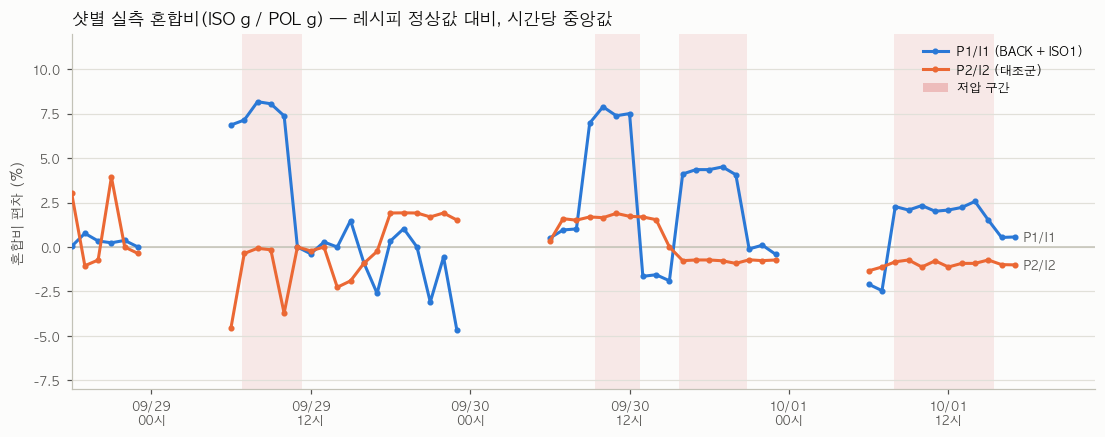

In [39]:
lo, hi = pd.Timestamp("2026-09-28 18:00"), pd.Timestamp("2026-10-01 18:00")
hd = shots.set_index("_time").groupby("pair").dev_pct.resample("h").median().unstack(0)
hn = shots.set_index("_time").groupby("pair").dev_pct.resample("h").size().unstack(0)
hd = hd.where(hn >= 10).reindex(pd.date_range(lo, hi, freq="h"))

fig, ax = plt.subplots(figsize=(12, 4.2), facecolor=SURFACE)
style_ax(ax)
shade_episodes(ax, lo, hi)
ax.axhline(0, color=AXIS, lw=1, zorder=1)
for col, color, name in [("P1/I1", BLUE, "P1/I1 (BACK + ISO1)"), ("P2/I2", ORANGE, "P2/I2 (대조군)")]:
    ax.plot(hd.index, hd[col], color=color, lw=2, marker="o", ms=3, zorder=3, label=name)
    last = hd[col].dropna()
    ax.text(last.index[-1] + pd.Timedelta(minutes=40), last.iloc[-1], name.split(" ")[0], color=INK2, fontsize=8,
            va="center")
ax.set_xlim(lo, hi + pd.Timedelta(hours=5))
ax.set_ylim(-8, 12)
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d\n%H시"))
ax.set_ylabel("혼합비 편차 (%)", color=INK2, fontsize=9)
ax.set_title("샷별 실측 혼합비(ISO g / POL g) — 레시피 정상값 대비, 시간당 중앙값", loc="left", color=INK, fontsize=11,
             fontweight="bold")
ax.legend(handles=ax.get_legend_handles_labels()[0] + [Patch(facecolor=CRITICAL, alpha=0.25, label="저압 구간")],
          loc="upper right", fontsize=8, frameon=False)
plt.show()

- **P1/I1 쌍의 혼합비가 9/29 오전·9/30 오전에 +7% 안팎**(레시피별 +6.7~7.4%, 시간당 중앙값 최대 +8%) 틀어진 채 생산됐다. 9/30 저녁은 +4% 대(15:27 Auto-Cal 로
  Hz/SV 가 −4% 된 만큼 일부 상쇄), 10/1 은 +2% 대. 저항이 컸던 9/29 밤에는 반대로 **−3~−5%**.
- 대조군 P2/I2 는 같은 기간 ±2% 안팎 — **ISO1 라인만의 문제**라는 §7 결론과 일치한다.
- 이 숫자는 PLC 가 **매 샷 이미 계산해서 HMI 로 보내던 값**이다. 판정할 재료는 있었는데, 비교하는 로직이 없었다.

### 8-5. 그럼 지금은 무엇으로 판단하나

PLC 안에는 판단 장치가 없으므로, 지금 체계에서 이상을 알아챌 수 있는 길은 사람 쪽이다(추정):
- **HMI 화면** — 운전 중 FT·PT, 샷 리포트(샷별 g)를 사람이 보고 판단. HMI 프로젝트 자체에 태그 알람이 설정돼
  있을 수는 있다(이 분석으로는 볼 수 없음 → 확인 필요).
- **테스트샷 + 저울** — 컵에 쏴서 무게를 재고 HMI 에 입력하는 Gain Set 경로(§1-4 b). 이번 기간엔 미사용.
- **제품 품질** — 혼합비가 틀어지면 경도·밀도·외관이 달라진다. 결국 제품 검사에서 걸리는 구조.
- **Auto-Cal** — 이상하다 싶으면 라인을 세우고 다시 보정(§2-4). 단 노즐을 다시 만지면 무의미해진다(§6-2).

왜 PLC 에 없을까에 대한 답은 설계 의도라 데이터로는 알 수 없다. 다만 구조상 이 설비는 **"보정해 두면 그대로
나온다"는 개루프 전제**로 만들어졌고, 알람은 설비 보호용만 넣은 것으로 보인다. 노즐 조정처럼 보정 이후에 유로를
바꾸는 행위가 잦다면 그 전제가 깨진다.

---
## §9. 결론 · 현장 확인 요청 · 한계

### 결론

1. **계수 변경이 아니다.** 9/29 오전 전후로 Hz/SV(제어 계수의 곱)는 3.0273 으로 동일하고, FT 계측 계수도
   그대로다. 기간 중 실제로 바뀐 계수는 **Auto-Cal 2회(9/27 11:40, 9/30 15:27, 둘 다 HMI 수동 시작)** 뿐이다.
2. **바뀐 건 ISO1 라인 하류의 유로 저항이다.** PT 가 같은 SV 정상값의 74~84% 로 떨어졌고, 그만큼 펌프 내부
   누설이 줄어 **같은 Hz 에서 실제로 약 7~9% 더 토출**했다. FT 는 그걸 정확히 잰 것이다(슬립 곡선 잔차 ±1%).
3. **ISO1 만의 문제다.** 같은 헤드의 P1 은 그대로이고, 탱크 레벨·재료온도·PT 스케일도 그대로다.
4. **제어와 무관하다.** SV·보정계수를 안 쓰는 20 Hz 순환운전에서도 같은 변화가 있고, 증압과 순환의 유로 저항(K)이
   함께 약 1/3 내려갔다 → 공통 경로의 오리피스형 저항(**헤드 ISO 노즐 추정**)이 열렸다.
5. **바뀐 시점이 사람 손을 가리킨다.** 9/29 은 야간 정지(23:58~06:13) 중에 열렸고, 11:23:01~07 **증압 도중
   지령이 고정된 상태에서 6초에 걸쳐** 원래대로 조여졌다.
6. **반복되고, 반대 방향도 있다.** 저압(과토출) 구간은 9/29 06:50~11:22, 9/30 09:23~12:48, 9/30 15:44~20:48,
   10/1 07:54~15:25. 저항이 높아진 9/28 오후·9/29 밤에는 반대로 FT/SV 0.94~0.98 (덜 토출).
7. **Auto-Cal 은 사람이 필요할 때 누르는 것이다.** 자동운전을 내려야만 시작되고, 한 달 3회뿐이다. 9/30 은 노즐 조정과
   Auto-Cal 이 한 세션으로 이어졌지만, 보정 후 저항이 또 바뀌어 보정이 무의미해졌다.
8. **토출량을 판정하는 장치가 PLC 에 없다.** 알람 220개 중 유량·샷량·혼합비 관련 0개, 사출은 시간으로 끝나고, 샷별 실측 g 은
   리포트로만 나간다. 그 리포트 데이터로 보면 9/29 오전 **샷별 혼합비가 +7% 안팎** 틀어진 채 생산됐다.

### 현장 확인 요청

| 시각 | 확인할 것 |
|---|---|
| 9/28 23:58 ~ 9/29 06:13 (야간 정지) | HD1 헤드 ISO 노즐 / ISO1 라인 밸브 작업·청소·교체 이력 |
| 9/29 11:23 (증압 도중, 약 6초) | 노즐·밸브를 다시 조정한 사람 — 무엇을 보고(사출 품질? 압력 게이지?) 했는지 |
| 9/30 09:23, 12:48, 15:44(Auto-Cal 16분 뒤), 20:49 / 10/1 07:54, 15:25 | 같은 조작인지 |
| 9/27 11:40, 9/30 15:20~15:45, 10/5 15:00 | Auto-Cal 을 누가 왜 돌렸는지 — **HMI 조작 이력**(기종에 따라 operation log) 확인 |
| HMI 프로젝트 | 샷 리포트·FT 태그에 HMI 쪽 알람/허용범위 설정이 있는지 |
| 9/29 오전 생산품 | 혼합비 +7% 구간 제품의 품질(경도·밀도·외관) 이상 여부 |

### 감지 아이디어 — 이미 DB 에 있는 값으로 가능한 것

| 지표 | 데이터 | 9/29 에 언제 잡았을까 |
|---|---|---|
| 샷별 혼합비 편차 (§8-4) | `D00011~D00033` + 사출 신호 | 첫 샷(06:50)부터 +7% — **품질과 직결** |
| 유로 저항 K = PT/FT² (§7-3) | `Scale_Out___PT/FT` | **06:13 재가동 순환운전부터** — 생산 전에 잡을 수 있음 |
| Hz/SV 계단 변화 (§4) | `Hz_Out`, `g_s_SV` | Auto-Cal·Gain Set 이 언제 계수를 바꿨는지 기록 |

### 한계

- **노즐은 추정이다.** 데이터로 확정한 건 "증압·순환이 공통으로 지나는 오리피스형 저항이 계단식으로 바뀌었다"까지다.
  밸브 부분 개방이나 FT 하류의 바이패스도 같은 신호를 낼 수 있다. **바이패스라면 헤드에 실제 들어간 양은
  FT 보다 적을 수 있으니** 현장 확인이 중요하다.
- REAL 계수는 DB 에 하위 16bit 만 남아 직접 불변 증명은 불완전하다 — 대신 §5 슬립 곡선으로 간접 확인했다.
- 제어측 계수(`A_CAL_*`, `Cal_Scale_Buff_*`)는 DB 미수집이라 Hz/SV 로 간접 확인했다. 수집 대상에 넣으면
  다음부터는 직접 볼 수 있다.
- Auto-Cal 은 **보정 순간의 노즐 상태를 계수에 고정**한다. 노즐 상태가 바뀌면 개루프 구조상 FT/SV 는 다시 벌어진다.
  FT/SV 를 감시하려면 **Hz/SV(제어) · PT/FT²(유로) · FT/Hz vs PT/Hz(슬립)** 을 같이 봐야 원인이 갈린다.

---
## §10. 진단 지표 정리 — 제어·펌프계·배관·계측을 어떻게 가르나

### 10-1. FT/SV 를 네 조각으로 나누기

신호는 한 방향으로 흐른다.

```
SV ──[제어: Auto-Cal 표]──▶ Hz ──[펌프계: 인버터·모터·펌프]──▶ FT ──[배관·노즐]──▶ PT
```

FT/SV = (Hz/SV) × (FT/Hz) 이고, 각 구간을 따로 보는 지표가 하나씩 있다.

| 지표 | 보는 곳 | 기준 | 성격 |
|---|---|---|---|
| **Hz/SV** | 제어 (PLC 계수) | Auto-Cal 때만 계단식으로 바뀜 (§4-2) | Auto-Cal 기록 없이 바뀌면 이상 |
| **펌프 잔차** = FT/Hz 의 슬립 직선 대비 편차 (§5) | 펌프계 | 펌프 고유의 직선 | 배관이 바뀌어도 직선 **위를** 움직일 뿐 |
| **K = PT/FT²** (§7-3) | 배관·노즐 | 유로 고유의 저항 | 펌프 상태와 무관 |
| **FT/SV** (= 혼합비, §8-4) | 결과 (품질) | 1.0 (직전 Auto-Cal 기준) | 문제가 있다는 건 알려주지만 원인은 못 가름 |

### 10-2. 압력과 토출량을 떼어놓는 원리 — 펌프 곡선과 배관 곡선

- **펌프 곡선**: 이 Hz 로 돌릴 때 걸리는 압력에 따라 얼마나 내보내나 (압력↑ → 내부 누설↑ → 덜 나감)
- **배관 곡선**: 이만큼 흘리면 압력이 얼마나 걸리나 (PT = K·FT²)

실제 운전점은 두 곡선의 교점이다.
- **배관이 바뀌면** 배관 곡선이 움직이고, 운전점은 펌프 곡선을 따라 미끄러진다 → **K 변화, 펌프 잔차 0**
  (9/29 실측: K −32%, 펌프 잔차 ±1% — §5, §7-3)
- **펌프계가 바뀌면** 펌프 곡선이 움직이고, 운전점은 배관 곡선을 따라 미끄러진다 → **펌프 잔차 변화, K 그대로**

같은 PT·FT 두 측정값이라도 **관계식 두 개를 따로 보면** 펌프 문제와 배관 문제를 떼어낼 수 있다.

### 10-3. 상황별 지문

| 상황 | Hz/SV | K | 펌프 잔차 | FT/SV |
|---|---|---|---|---|
| 노즐 열림 (9/29 오전) | – | **↓** | 0 | ↑ |
| 노즐 조임·막힘 (9/28 오후, 9/29 밤) | – | **↑** | 0 | ↓ |
| 펌프 마모·모터 미끄럼 증가 | – | – | **↓** | ↓ |
| 재료온도 상승 — ISO (점도↓ → 누설↑, §11) | – | – | **↓** | ↓ |
| 재료온도 상승 — 폴리올 (점도↓ → 배관 마찰↓, §11) | – | **↓** (점성분) | – | – |
| Auto-Cal · Gain 변경 | **계단** | – | 0 | 계단 |
| 유량계가 x% 높게 읽음 | – | ↓ (2x%) | ↑ (x%) | ↑ |
| 압력계가 y% 낮게 읽음 | – | ↓ (y%) | ↓ | – |

규칙: **실제 물리 변화는 지표 하나만 움직이고, 센서 고장은 두 지표를 정해진 비율로 함께 움직인다.**
(펌프 마모 행은 물리 원리에서 나온 예측이다 — 이 기간 데이터에 펌프 고장 사례는 없다.)

### 10-4. 인버터 피드백 없이 펌프계를 보는 법

**(a) 인버터에서 PLC 로 들어오는 신호는 트립 접점뿐이다.**

In [40]:
show_il("Pump_Control.il", r"AND\s+P00031", 2, before=1)
MAP_DIR = os.path.normpath(os.path.join(IL_DIR, "..", "mapping_csv"))
dev = pd.read_csv(os.path.join(MAP_DIR, "Device_Description.csv"), header=None, names=["주소", "형식", "크기", "설명"])
print("\n", dev[dev["주소"] == "P00031"].to_string(index=False))
var = pd.read_csv(os.path.join(MAP_DIR, "line2_variable.csv"))
fb = var[var.Variable.str.contains(r"전류|Current|Ampere|Torque|토크|인버터|Inverter|VFD|_FB\b|Feedback", case=False, regex=True, na=False)]
print("\n■ 전류·토크·인버터 피드백으로 보이는 태그:", sorted(fb.Variable.unique()) or "없음")
print("■ Pump_rpm_I1 은 HMI 에 넣는 명판값(1150)이지 측정값이 아니다. Pump_Run_I1 도 PLC 가 내보내는 운전 지령이다.")

Pump_Control.il:25    MLOAD
Pump_Control.il:26    AND	P00031
Pump_Control.il:27    SET	Pump_Trip_I1

     주소  형식  크기             설명
P00031 BIT   1 1-1펌프 ISO Trip

■ 전류·토크·인버터 피드백으로 보이는 태그: 없음
■ Pump_rpm_I1 은 HMI 에 넣는 명판값(1150)이지 측정값이 아니다. Pump_Run_I1 도 PLC 가 내보내는 운전 지령이다.


- 인버터 전류·실제 주파수·통신 피드백이 없다. `Hz_Out_I1` 은 **지령값**이다.
- 그래서 "펌프계"는 인버터·모터·펌프가 한 덩어리다. 이 안을 더 쪼개려면 전류나 회전수 신호가 필요하다.

**(b) 대신 유량계가 회전계 역할을 한다.** 용적식 펌프(A2VK)는 회전수에 비례해 토출하므로, 같은 압력 조건에서
FT/Hz 가 줄었다면 **지령만큼 안 돌았거나(인버터·모터) 돈 만큼 안 나왔다(펌프 누설)** 는 뜻이다. §5 의 슬립 직선을
기준선으로 두고 편차를 **펌프 잔차**로 쓴다. 증압 사이클과 20 Hz 순환운전 두 조건에서 각각 계산한다.

**(c) 가속 시간**: 증압이 시작될 때 Hz 지령이 순환값(20 Hz)에서 목표로 한 번에 오른다. FT 가 안정값의 95% 에
닿기까지 걸린 시간은 인버터 가속 설정과 모터 토크로 정해지고 배관과는 거의 무관하다. 로그 간격이 약 0.5초라
해상도는 거칠다.

In [41]:
SLIP_B0, SLIP_B1 = b0, b1   # §5 의 정상 사이클 슬립 직선 그대로


def slip_resid_pct(ft, hz, pt):
    """슬립 직선(기준 펌프 곡선) 대비 회전당 토출 편차 %. 음수 = 같은 압력 조건에서 덜 나옴."""
    return (ft / hz / (SLIP_B0 + SLIP_B1 * pt / hz * 1000) - 1) * 100


cyc["slip_resid"] = slip_resid_pct(cyc.FT, cyc.Hz, cyc.PT)
cyc["TT"] = cyc["cyc"].map(ticks.groupby("cyc").Scale_Out___TT_I1.median())
circ["slip_resid"] = slip_resid_pct(circ.Scale_Out___FT_I1, 2000, circ.Scale_Out___PT_I1)

# 가속 시간: 증압 시작 → FT 가 그 사이클 안정 FT 의 95% 에 처음 도달
on_bu = df[df.Pump_BuildUp_I1.fillna(0).astype(int) == 1]
steady_ft = cyc.set_index("cyc").FT
ramp = {}
for cid, g in on_bu.groupby("cyc"):
    if cid in steady_ft.index and len(g) >= 8:
        hit = g.Time[g.Scale_Out___FT_I1 >= 0.95 * steady_ft[cid]]
        if len(hit):
            ramp[cid] = (hit.iloc[0] - g.Time.iloc[0]).total_seconds()
cyc["ramp_s"] = cyc["cyc"].map(ramp)

running = df[df.Scale_Out___FT_I1 > 300]
daily = pd.DataFrame({
    "증압 사이클": cyc.groupby(cyc.t0.dt.date).size(),
    "K (증압)": cyc.groupby(cyc.t0.dt.date).K.median(),
    "펌프잔차_증압 %": cyc.groupby(cyc.t0.dt.date).slip_resid.median(),
    "펌프잔차_순환20Hz %": circ.groupby(circ.Time.dt.date).slip_resid.median(),
    "가속시간_SV1210 평균 s": cyc[cyc.SV == 1210].groupby(cyc.t0.dt.date).ramp_s.mean(),
    "재료온도 ℃": running.groupby(running.Time.dt.date).Scale_Out___TT_I1.median() / 10,
})
daily.index.name = "날짜"
daily.round(2)

,증압 사이클,K (증압),펌프잔차_증압 %,펌프잔차_순환20Hz %,가속시간_SV1210 평균 s,재료온도 ℃
날짜,,,,,,
2026-09-22,2689,5.82,0.56,-0.23,1.60,22.1
2026-09-23,2331,5.81,0.68,-0.30,1.61,22.0
2026-09-27,1,5.78,-4.13,-4.02,NaN,26.0
2026-09-28,1814,6.99,-0.77,-1.75,1.61,22.0
2026-09-29,2266,6.54,-0.14,-1.42,1.62,21.8
2026-09-30,2025,5.61,0.72,-0.47,1.60,22.0
2026-10-01,1931,5.41,0.67,-0.23,1.60,21.9


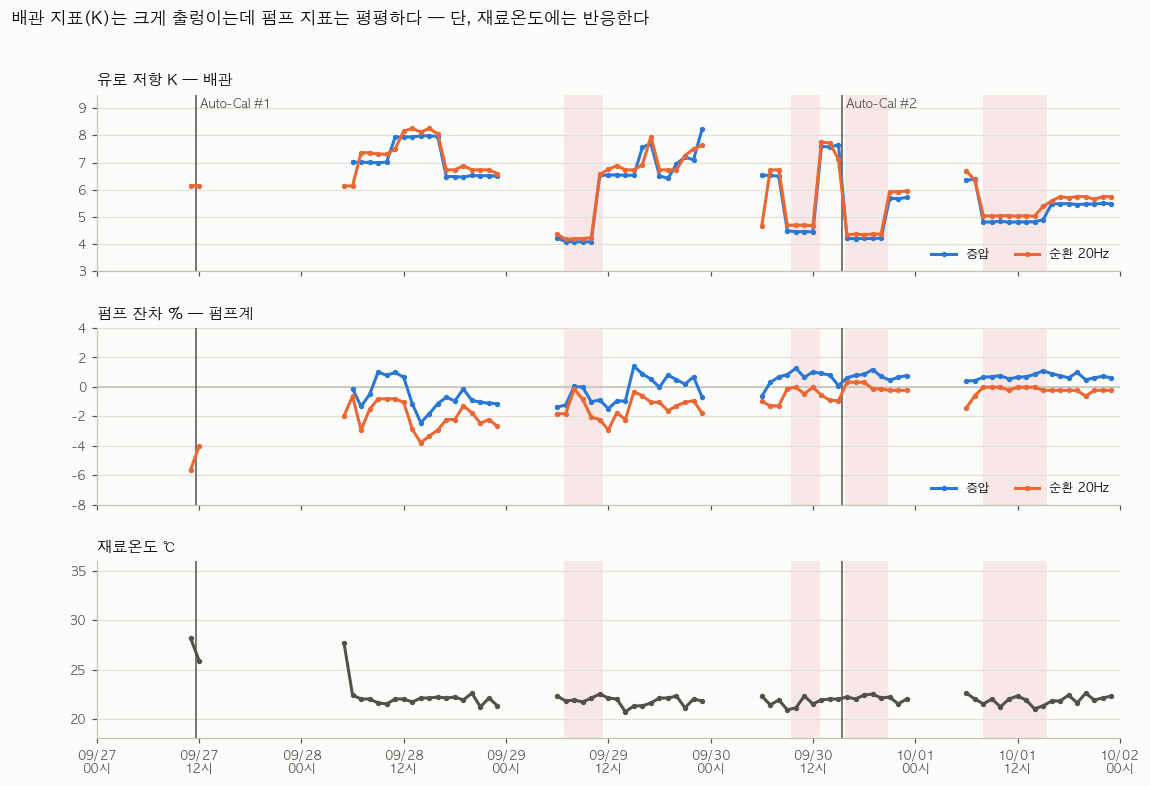

In [42]:
lo, hi = pd.Timestamp("2026-09-27 00:00"), pd.Timestamp("2026-10-02 00:00")
H = pd.date_range(lo, hi, freq="h")
def hourly(s, t, min_n):
    v = s.groupby(t.dt.floor("h")).median()
    n = s.groupby(t.dt.floor("h")).size()
    return v.where(n >= min_n).reindex(H)

panels = [
    ("유로 저항 K — 배관", [(hourly(cyc.K, cyc.t0, 10), BLUE, "증압"), (hourly(circ.K, circ.Time, 300), ORANGE, "순환 20Hz")], (3, 9.5), None),
    ("펌프 잔차 % — 펌프계", [(hourly(cyc.slip_resid, cyc.t0, 10), BLUE, "증압"),
                          (hourly(circ.slip_resid, circ.Time, 300), ORANGE, "순환 20Hz")], (-8, 4), 0),
    ("재료온도 ℃", [(hourly(running.Scale_Out___TT_I1 / 10, running.Time, 50), INK2, "TT_I1")], (18, 36), None),
]
fig, axes = plt.subplots(3, 1, figsize=(12, 7.6), sharex=True, facecolor=SURFACE, gridspec_kw={"hspace": 0.32})
for ax, (title, series, ylim, ref) in zip(axes, panels):
    style_ax(ax)
    shade_episodes(ax, lo, hi)
    for t, label in AUTOCAL:
        ax.axvline(t, color=INK2, lw=1, zorder=2)
    if ref is not None:
        ax.axhline(ref, color=AXIS, lw=1, zorder=1)
    for s, color, name in series:
        ax.plot(s.index, s.values, color=color, lw=2, marker="o", ms=2.5, zorder=3, label=name)
    ax.set_ylim(*ylim)
    ax.set_title(title, loc="left", color=INK, fontsize=10, fontweight="bold")
    if len(series) > 1:
        ax.legend(loc="lower right", fontsize=8, frameon=False, ncol=2)
axes[0].text(AUTOCAL[0][0], 9.4, " Auto-Cal #1", color=INK2, fontsize=8, va="top")
axes[0].text(AUTOCAL[1][0], 9.4, " Auto-Cal #2", color=INK2, fontsize=8, va="top")
axes[2].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%m/%d\n%H시"))
axes[2].set_xlim(lo, hi)
fig.suptitle("배관 지표(K)는 크게 출렁이는데 펌프 지표는 평평하다 — 단, 재료온도에는 반응한다", x=0.06, ha="left",
             color=INK, fontsize=11, fontweight="bold")
plt.show()

- **K 는 저압 구간마다 ±30% 넘게 움직이는데, 펌프 잔차는 그 구간에서도 ±2% 안에서 평평하다.** 배관 변화가 펌프 지표를 오염시키지
  않는다는 뜻이다 — 10-2 의 원리가 실데이터에서 그대로 보인다.
- 가속 시간도 날마다 평균 1.6 초로 같다. 노즐이 열린 날에도 변하지 않는다 → 인버터·모터 쪽은 이 기간 정상.
- **예외는 9/27 이다.** 연휴로 라인이 정체돼 재료가 데워져 있었고(정지 중 최고 35℃, 가동 시 26~32℃ — 평소 21~22℃),
  그때 펌프 잔차가 −4~−6% 로 떨어졌다. 점도가 낮아져 내부 누설이 늘어난 것으로, **펌프 고장이 아니라 온도 효과**다.
  → 펌프 잔차로 펌프 이상을 판단하려면 **온도가 비슷한 구간끼리 비교하거나 온도 보정**을 해야 한다.
- 순환 20 Hz 의 잔차는 증압보다 전반적으로 약간 낮게 나온다(직선을 증압 사이클로 맞춰서 순환 조건은 살짝 외삽).
  절대값보다 **매일 같은 조건에서의 추세**로 보면 된다 — 매일 아침 재가동 직후 순환운전이 자연스러운 **표준 시험**이다.

**(d) Auto-Cal 은 그 자체로 6점 펌프 곡선 측정이다.** 30 → 55 Hz 를 차례로 돌리며 FT·PT 를 재므로, 그 점들이
슬립 직선 위에 있는지 보면 보정 당시 펌프 상태를 알 수 있다.

,보정,Hz,n,FT,PT,PT/Hz×1000,FT/Hz,펌프잔차 %,재료온도 ℃
0,09/27 11:40,4500.0,3,1430.0,118.0,26.222,0.318,-6.087,32.1
1,09/30 15:27,3000.0,9,1053.0,68.0,22.667,0.351,0.081,21.5
2,09/30 15:27,3500.0,8,1199.5,89.0,25.429,0.343,0.464,21.5
3,09/30 15:27,4000.0,6,1355.0,112.0,28.000,0.339,1.970,21.5
4,09/30 15:27,4500.0,7,1492.0,136.0,30.222,0.332,2.176,21.6
5,09/30 15:27,5000.0,8,1616.0,159.0,31.800,0.323,1.311,21.6
6,09/30 15:27,5500.0,8,1729.0,182.0,33.091,0.314,-0.055,21.6


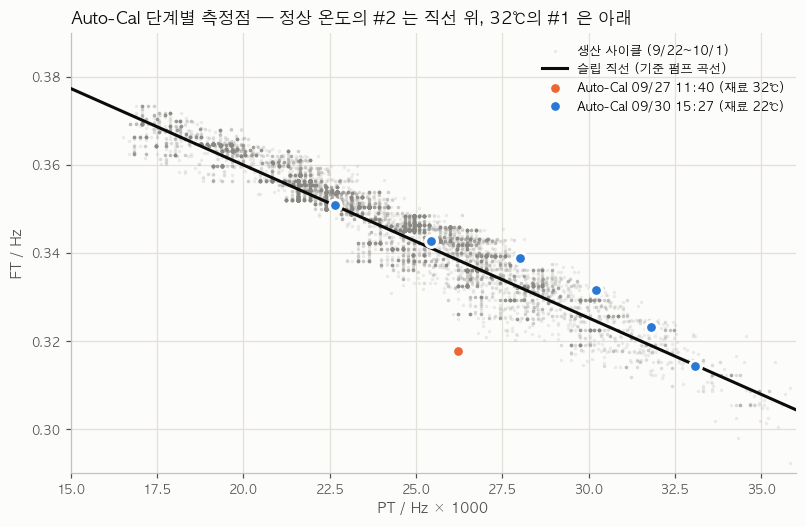

In [43]:
cal_pts = []
for _, r in cal_runs[cal_runs["펌프"].str.contains("I1")].iterrows():
    w = df[(df.Time >= r["시작"]) & (df.Time <= r["시작"] + pd.Timedelta(seconds=int(r["소요_초"]) + 1))]
    g = (w.groupby("Hz_Out_I1").agg(n=("Time", "size"), FT=("Scale_Out___FT_I1", "median"),
                                    PT=("Scale_Out___PT_I1", "median"), TT=("Scale_Out___TT_I1", "median"))
         .query("n >= 3 and index >= 3000").reset_index().rename(columns={"Hz_Out_I1": "Hz"}))
    g.insert(0, "보정", f"{r['시작']:%m/%d %H:%M}")
    cal_pts.append(g)
cal_pts = pd.concat(cal_pts, ignore_index=True)
cal_pts["PT/Hz×1000"] = cal_pts.PT / cal_pts.Hz * 1000
cal_pts["FT/Hz"] = cal_pts.FT / cal_pts.Hz
cal_pts["펌프잔차 %"] = slip_resid_pct(cal_pts.FT, cal_pts.Hz, cal_pts.PT)
cal_pts["재료온도 ℃"] = cal_pts.TT / 10
display(cal_pts.drop(columns="TT").round(3))

fig, ax = plt.subplots(figsize=(8.5, 5.2), facecolor=SURFACE)
style_ax(ax)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.scatter(cyc.PTn, cyc.FT_Hz, s=5, color=MUTED, alpha=0.15, lw=0, zorder=2, label="생산 사이클 (9/22~10/1)")
xs = np.linspace(15, 36, 50)
ax.plot(xs, SLIP_B0 + SLIP_B1 * xs, color=INK, lw=2, zorder=3, label="슬립 직선 (기준 펌프 곡선)")
for (name, g), color in zip(cal_pts.groupby("보정", sort=False), [ORANGE, BLUE]):
    tt = g["재료온도 ℃"].median()
    ax.scatter(g["PT/Hz×1000"], g["FT/Hz"], s=60, color=color, edgecolor=SURFACE, linewidth=2, zorder=4,
               label=f"Auto-Cal {name} (재료 {tt:.0f}℃)")
ax.set_xlim(15, 36)
ax.set_ylim(0.29, 0.39)
ax.set_xlabel("PT / Hz × 1000", color=INK2, fontsize=9)
ax.set_ylabel("FT / Hz", color=INK2, fontsize=9)
ax.set_title("Auto-Cal 단계별 측정점 — 정상 온도의 #2 는 직선 위, 32℃의 #1 은 아래", loc="left", color=INK,
             fontsize=11, fontweight="bold")
ax.legend(loc="upper right", fontsize=8, frameon=False)
plt.show()

- **9/30 Auto-Cal(#2, 21~22℃)의 6점은 슬립 직선 ±2% 안에 들어온다**(생산 사이클 산포 수준) → 보정 당시 펌프는 정상.
- **9/27 Auto-Cal(#1)은 재료온도 약 32℃에서 실행됐고, 측정점이 직선보다 6% 아래**에 있다(누설↑). 9/26 18:00~9/27 12:00 은
  로거가 열화된 구간이라 기록된 단계가 적다.
- 실무적 함의: **Auto-Cal 은 정상 운전 온도에서 해야 한다.** 따뜻한 재료로 보정하면 그 온도의 누설까지 계수에
  박히고, 재료가 식으면 같은 SV 에 더 많이 나간다.

### 10-5. 판단 순서 — "배관이 아니면 펌프계"

```
FT/SV(혼합비)가 기준을 벗어났다
 ├─ Hz/SV 가 계단식으로 바뀌었나?            → 예: 제어 (Auto-Cal·Gain 변경 — 이력 확인)
 ├─ K 가 바뀌었나? 펌프 잔차는 0 인가?        → 예: 배관·노즐 (조정·막힘·청소)
 ├─ K 와 펌프 잔차가 정해진 비율로 같이 움직이나? → 예: 계측 (유량계·압력계)
 ├─ 펌프 잔차만 바뀌었나?
 │    ├─ 재료온도가 평소와 다른가?             → 예: 점도 효과 (이상 아님, 온도 보정)
 │    └─ 아니다                              → 펌프계 (펌프 마모 / 모터·인버터) — 가속 시간도 같이 본다
 └─ 어느 것도 아니다                          → 테스트샷 + 저울로 절대값 확인
```

### 10-6. 사이클별 지표 계산 함수 — 다른 펌프·다른 기간에 그대로 쓰기

위 지표들을 한 번에 만드는 함수다. 예지보전 모델(HDI_MODEL) 입력 후보로 쓸 수 있다.
펌프마다 슬립 직선이 다르므로 `fit_slip()` 으로 정상 구간에서 먼저 맞춘다.

In [44]:
def cycle_indicators(raw, pump, slip=None, steady_min=STEADY_MIN):
    """사이클별 진단 지표. raw 는 LogExtractor.get_data 결과(펌프 하나 분량).

    필요한 태그: Pump_BuildUp_{p}, g_s_SV_{p}, Hz_Out_{p}, Scale_Out___FT_{p}, Scale_Out___PT_{p},
               Scale_Out___TT_{p}, AL_Line_Bit
    slip: (b0, b1) — 없으면 펌프 잔차는 계산하지 않는다 (fit_slip 으로 먼저 구할 것).
    """
    d = raw.ffill().reset_index()
    bu = d[f"Pump_BuildUp_{pump}"].fillna(0).astype(int)
    d["cyc"] = (bu.diff().fillna(0) != 0).cumsum()
    on = d[bu == 1].copy()
    on["hz_grp"] = (on[f"Hz_Out_{pump}"].diff().fillna(0) != 0).cumsum()
    on["since_hz"] = on.groupby("hz_grp").cumcount()
    st = on[(on.since_hz >= steady_min) & (on[f"g_s_SV_{pump}"] > 0) & (on[f"Hz_Out_{pump}"] > 0)
            & ((on["AL_Line_Bit"].fillna(0) == 0) if "AL_Line_Bit" in on else True)]
    c = (st.groupby("cyc").agg(t0=("Time", "min"), n=("Time", "size"), SV=(f"g_s_SV_{pump}", "median"),
                                Hz=(f"Hz_Out_{pump}", "median"), FT=(f"Scale_Out___FT_{pump}", "median"),
                                PT=(f"Scale_Out___PT_{pump}", "median"), TT=(f"Scale_Out___TT_{pump}", "median"))
         .query("n >= 10").reset_index())
    c["Hz_SV"], c["FT_SV"], c["FT_Hz"] = c.Hz / c.SV, c.FT / c.SV, c.FT / c.Hz
    c["PTn"] = c.PT / c.Hz * 1000
    c["K"] = c.PT / c.FT ** 2 * 1e5
    if slip is not None:
        c["slip_resid"] = (c.FT_Hz / (slip[0] + slip[1] * c.PTn) - 1) * 100
    steady = c.set_index("cyc").FT
    rmp = {}
    for cid, g in on.groupby("cyc"):
        if cid in steady.index and len(g) >= 8:
            hit = g.Time[g[f"Scale_Out___FT_{pump}"] >= 0.95 * steady[cid]]
            if len(hit):
                rmp[cid] = (hit.iloc[0] - g.Time.iloc[0]).total_seconds()
    c["ramp_s"] = c["cyc"].map(rmp)
    return c


def fit_slip(c, mask=None):
    """정상 구간 사이클로 슬립 직선 FT/Hz = b0 + b1·(PT/Hz×1000) 을 맞춘다."""
    s = c if mask is None else c[mask]
    b1_, b0_ = np.polyfit(s.PTn, s.FT_Hz, 1)
    return b0_, b1_


# 검증: I1 로 다시 계산해서 위 결과와 같은지
ci = cycle_indicators(raw, "I1", slip=(SLIP_B0, SLIP_B1))
print(f"사이클 {len(ci):,}개 (위 cyc 와 같은 정의: {len(cyc):,}개)")
ci.groupby(ci.t0.dt.date)[["Hz_SV", "FT_SV", "K", "slip_resid", "ramp_s"]].median().round(3)

사이클 13,057개 (위 cyc 와 같은 정의: 13,057개)


,Hz_SV,FT_SV,K,slip_resid,ramp_s
t0,,,,,
2026-09-22,2.948,1.024,5.818,0.556,1.563
2026-09-23,2.948,1.024,5.807,0.677,1.565
2026-09-27,2.948,0.975,5.784,-4.130,2.125
2026-09-28,3.027,1.011,6.989,-0.770,1.563
2026-09-29,3.027,1.026,6.537,-0.139,1.564
2026-09-30,3.027,1.040,5.609,0.715,1.564
2026-10-01,2.902,1.032,5.411,0.666,1.563


---
## §11. 온도(점도) 보정 — 온도 계수를 식의 어디에, 어떤 형태로 넣나

§10 에서 펌프 잔차가 재료온도에 반응하는 걸 봤고, 팀 분석(`HDI_MODEL/예지보전_설계정리.md` 5절)에서도 P1 압력이
온도와 −0.61 상관이었다. 여기서 답할 질문:

1. 온도를 **절대온도로 바꿔서** 식에 넣으면 되나?
2. 원료표의 **지수식을 그대로** 넣어야 하나, **근사식**(선형 등)으로 충분한가?
3. 온도는 **토출량과 압력 중 어디에** 영향을 주나?

### 11-1. 원료 점도표 — 절대온도는 "지수 안"에 들어간다

출처: `OJT/공정도.xls` 의 `온도별 점도 (3)` 시트 (2013.5.12 측정, 북경공장 자료 — 현재 원료 등급과 같은지는 확인 필요).
액체 점도는 **Andrade 식** μ = A·exp(B / T_K) 를 따른다. 절대온도 T_K 는 이 지수 안에서 쓰인다.

In [45]:
VISC_T = np.array([20, 21, 23, 26, 29, 32, 35, 38, 40], float)
VISC = {   # cP — OJT/공정도.xls '온도별 점도 (3)' (2013.5.12)
    "TM-337 (POL, BACK)": [2289, 2118, 1869, 1585, 1302, 1076, 873, 730, 655],
    "AM-315 (POL, CUSH)": [2661, 2512, 2255, 1860, 1545, 1300, 1076, 927, 825],
    "MBR-360 (POL, 고탄성)": [3511, 3180, 2774, 2280, 1936, 1618, 1359, 1181, 1084],
    "TM-20 (ISO)": [4.91, 4.85, 4.69, 4.44, 4.24, 3.98, 3.73, 3.44, 3.15],
    "MC-70 (ISO)": [11.6, 11.29, 10.6, 9.73, 9.13, 8.36, 7.62, 6.74, 6.16],
}
T_REF = 22.0    # 이 라인의 평소 재료온도


def mu_rel(T_c, B, T_ref=T_REF):
    """μ(T)/μ(T_ref) — Andrade. T_c 는 ℃, B 는 원료별 상수(K)."""
    return np.exp(B * (1 / (np.asarray(T_c, float) + 273.15) - 1 / (T_ref + 273.15)))


B_VISC, rows = {}, []
for name, mu in VISC.items():
    mu = np.array(mu, float)
    B, lnA = np.polyfit(1 / (VISC_T + 273.15), np.log(mu), 1)
    B_VISC[name.split()[0]] = B
    pred = np.exp(lnA + B / (VISC_T + 273.15))
    lin = VISC_T <= 32
    s1, s0 = np.polyfit(VISC_T[lin], mu[lin], 1)
    rows.append({"원료": name, "μ(22℃) cP": round(np.exp(lnA + B / (T_REF + 273.15)), 2), "B (K)": round(B),
                 "점도 변화율 %/℃": round(-B / (T_REF + 273.15) ** 2 * 100, 2),
                 "Andrade 최대오차 % (20~40℃)": round(np.abs(pred / mu - 1).max() * 100, 1),
                 "선형 최대오차 % (20~32℃)": round(np.abs((s0 + s1 * VISC_T[lin]) / mu[lin] - 1).max() * 100, 1)})
print(f"절대온도를 그냥 곱했을 때(μ ∝ 1/T_K) 변화율: {-100 / (T_REF + 273.15):.2f} %/℃")
pd.DataFrame(rows)

절대온도를 그냥 곱했을 때(μ ∝ 1/T_K) 변화율: -0.34 %/℃


,원료,μ(22℃) cP,B (K),점도 변화율 %/℃,Andrade 최대오차 % (20~40℃),선형 최대오차 % (20~32℃)
0,"TM-337 (POL, BACK)",2012.17,5756,-6.61,2.2,4.6
1,"AM-315 (POL, CUSH)",2367.49,5418,-6.22,1.4,4.9
2,"MBR-360 (POL, 고탄성)",2981.25,5360,-6.15,3.9,7.3
3,TM-20 (ISO),4.80,1921,-2.21,4.9,0.4
4,MC-70 (ISO),11.04,2781,-3.19,4.3,1.7


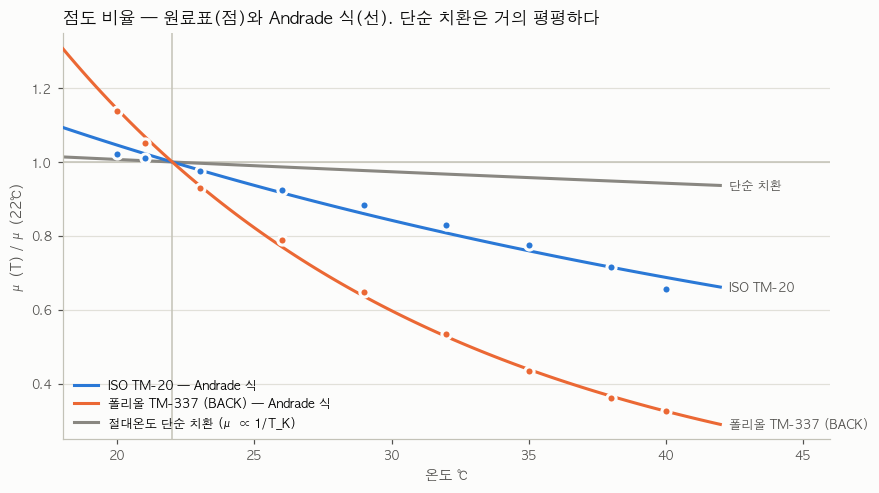

In [46]:
Tg = np.linspace(18, 42, 100)
fig, ax = plt.subplots(figsize=(9, 4.8), facecolor=SURFACE)
style_ax(ax)
for key, color, label in [("TM-20", BLUE, "ISO TM-20"), ("TM-337", ORANGE, "폴리올 TM-337 (BACK)")]:
    name = next(n for n in VISC if n.startswith(key))
    mu = np.array(VISC[name], float)
    lnA = np.polyfit(1 / (VISC_T + 273.15), np.log(mu), 1)[1]
    mu22 = np.exp(lnA + B_VISC[key] / (T_REF + 273.15))
    ax.plot(Tg, mu_rel(Tg, B_VISC[key]), color=color, lw=2, zorder=3, label=f"{label} — Andrade 식")
    ax.plot(VISC_T, mu / mu22, "o", ms=6, color=color, markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
    ax.text(42.3, mu_rel(42, B_VISC[key]), label, color=INK2, fontsize=8, va="center")
ax.plot(Tg, (T_REF + 273.15) / (Tg + 273.15), color=MUTED, lw=2, zorder=2, label="절대온도 단순 치환 (μ ∝ 1/T_K)")
ax.text(42.3, (T_REF + 273.15) / (42 + 273.15), "단순 치환", color=INK2, fontsize=8, va="center")
ax.axhline(1, color=AXIS, lw=1, zorder=1)
ax.axvline(T_REF, color=AXIS, lw=1, zorder=1)
ax.set_xlim(18, 46)
ax.set_ylim(0.25, 1.35)
ax.set_xlabel("온도 ℃", color=INK2, fontsize=9)
ax.set_ylabel("μ(T) / μ(22℃)", color=INK2, fontsize=9)
ax.set_title("점도 비율 — 원료표(점)와 Andrade 식(선). 단순 치환은 거의 평평하다", loc="left", color=INK, fontsize=11,
             fontweight="bold")
ax.legend(loc="lower left", fontsize=8, frameon=False)
plt.show()

- 폴리올은 **−6.2~−6.6 %/℃**, ISO 는 **−2.2~−3.2 %/℃** 로 변한다.
- 절대온도를 그냥 곱하면(μ ∝ 1/T_K) **−0.34 %/℃** 뿐이다 — 폴리올의 1/20, ISO 의 1/6~1/9. 온도 효과를 거의 못 잡는다.
- Andrade 식은 20~40℃ 전 범위를 최대 1.4~4.9% 오차로 맞춘다. **절대온도는 이렇게 지수 안에 넣을 때 의미가 있다.**

### 11-2. 지수식을 그대로 넣어도 되나, 근사식이면 되나

세 가지 형태를 22℃ 기준으로 비교한다.
- **Andrade**: μ_rel = exp[B·(1/T_K − 1/T_ref,K)] — 원료표에 맞춘 식 그대로
- **섭씨 지수 근사**: μ_rel = exp[−β·(T − T_ref)], β = B / T_ref,K² — 절대온도 없이 섭씨로
- **선형 근사**: μ_rel = 1 − β·(T − T_ref) — "정비례처럼 보인다"는 관찰 그대로

In [47]:
rows = []
for key in ["TM-20", "TM-337"]:
    B = B_VISC[key]
    beta = B / (T_REF + 273.15) ** 2
    for dT in [-5, -2, 2, 5, 10, 15]:
        a = float(mu_rel(T_REF + dT, B))
        e, l = np.exp(-beta * dT), 1 - beta * dT
        rows.append({"원료": key, "β %/℃": round(beta * 100, 2), "ΔT ℃": dT, "Andrade": round(a, 4),
                     "섭씨 지수 오차 %": round((e / a - 1) * 100, 2), "선형 오차 %": round((l / a - 1) * 100, 1)})
pd.DataFrame(rows).set_index(["원료", "β %/℃", "ΔT ℃"])

Andrade  섭씨 지수 오차 %  선형 오차 %
원료     β %/℃ ΔT ℃                              
TM-20  2.21  -5     1.1187       -0.19     -0.8
             -2     1.0454       -0.03     -0.1
              2     0.9571       -0.03     -0.1
              5     0.8972       -0.18     -0.8
              10    0.8079       -0.72     -3.5
              15    0.7299       -1.59     -8.3
TM-337 6.61  -5     1.3994       -0.57     -4.9
             -2     1.1423       -0.09     -0.9
              2     0.8770       -0.09     -1.0
              5     0.7226       -0.55     -7.3
              10    0.5278       -2.14    -35.7
              15    0.3894       -4.68    -97.7

- **지수식은 그대로 넣어도 된다.** 원료별 상수 B 를 고정하면 μ_rel(T) 는 사이클마다 미리 계산하는 **곱셈 계수**일 뿐이라,
  뒤의 회귀식(슬립 직선, 압력식)은 여전히 미지수에 대해 선형이다. 계산 부담도 없다.
- **섭씨 지수 근사는 사실상 같다** — ±5℃ 에서 0.6% 이내, +10℃ 에서도 ISO 0.7%·폴리올 2.1%. 설명하기 쉬운 형태가 필요하면 이걸 쓴다.
  게다가 로그를 취하면 직선(ln μ_rel = −β·ΔT)이라, **원료표가 없을 때 데이터로 β 를 추정하기 쉽다**(11-4 에서 그렇게 했다).
- **선형 근사는 범위가 좁을 때만 된다.** ISO 는 ±5℃ 까지 1% 이내지만, 폴리올은 ±5℃ 에서 5~7%, +10℃ 에서 −36%,
  +15℃ 에서는 점도가 0 에 가까워지는 엉터리 값이 된다. 연휴 뒤 30℃ 넘는 재료가 들어오는 일이 실제로 있었으니(9/27) 쓰지 않는다.
- 평소 운전(22±1℃)에서는 세 형태의 차이가 0.1% 수준이다. **형태보다 B(원료 상수)의 정확도가 더 중요하다.**

### 11-3. 온도는 토출량과 압력 중 어디에 들어가나 — 원료마다 다르다

점도가 식에 들어가는 자리는 물리적으로 세 곳이다.

| 자리 | 물리 | 식 | ISO (I1, 약 5 cP) | 폴리올 (P1, 약 2,000 cP) |
|---|---|---|---|---|
| **펌프 누설** | 좁은 틈새의 층류 → 누설 ∝ 압력/점도 | FT/Hz = D − c·(PT/Hz) **/ μ_rel(T)** | **주효과** → 토출량에 직접 | 점도가 커서 누설 자체가 작다 |
| **배관 압력** | 관 마찰(층류 ∝ μ·Q) + 노즐(관성 ∝ Q²) | PT = K·FT² + R·**μ_rel(T)**·FT | 노즐 항이 지배 → 온도 무관 | **점성 마찰 항이 크다** → 압력에 직접 |
| 유량계 비중 | 밀도가 온도로 약간 변함 | FT 환산식의 SG(1.2 고정) | 0.1%/℃ 수준, 부차적 | 같음 |

그리고 압력과 유량은 PT = K·FT² 로 묶여 있어서, 한쪽이 바뀌면 다른 쪽도 따라간다.

```
ISO   : 온도↑ → 점도↓ → 펌프 누설↑ → 토출량↓ (직접) → 압력↓ (토출량을 따라서, 간접)
폴리올 : 온도↑ → 점도↓ → 배관 마찰↓ → 압력↓ (직접)    → 토출량은 거의 그대로
```

### 11-4. ISO(I1) 검증 — 온도는 토출량에 들어간다

**(a) 자연 실험: 9/28 아침, 20 Hz 고정 순환 중 재료가 식는 동안**

,재료온도,FT,PT,K
Time,,,,
2026-09-28 05:20:00,29.4,721.0,32.0,6.08
2026-09-28 05:30:00,28.9,733.0,32.0,6.14
2026-09-28 05:40:00,26.8,733.0,32.0,6.14
2026-09-28 05:50:00,24.8,733.0,33.0,6.14
2026-09-28 06:00:00,22.9,733.0,33.0,6.14
2026-09-28 06:10:00,22.5,743.0,33.0,6.11
2026-09-28 06:20:00,22.5,741.0,33.0,6.11
2026-09-28 06:30:00,22.1,746.0,34.0,6.11
2026-09-28 06:40:00,22.9,735.0,33.0,6.11


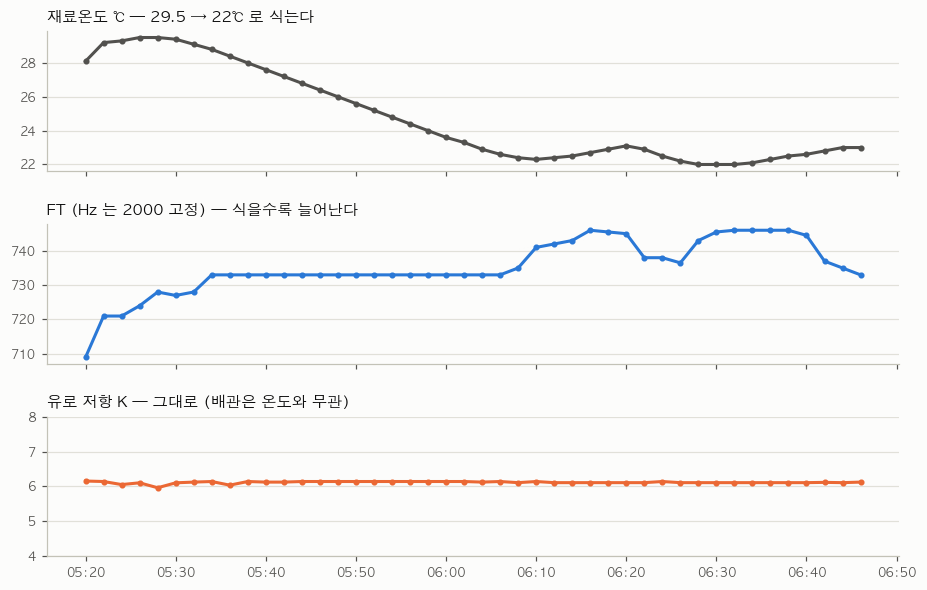

In [48]:
lo, hi = pd.Timestamp("2026-09-28 05:15"), pd.Timestamp("2026-09-28 06:48")
cw = circ[(circ.Time >= lo) & (circ.Time < hi)].copy()
cw["T_C"] = cw.Scale_Out___TT_I1 / 10
cm = cw.groupby(cw.Time.dt.floor("10min")).agg(재료온도=("T_C", "median"), FT=("Scale_Out___FT_I1", "median"),
                                               PT=("Scale_Out___PT_I1", "median"), K=("K", "median"))
display(cm.round(2))

c5 = cw.groupby(cw.Time.dt.floor("2min")).agg(T=("T_C", "median"), FT=("Scale_Out___FT_I1", "median"), K=("K", "median"))
fig, axes = plt.subplots(3, 1, figsize=(10, 6.2), sharex=True, facecolor=SURFACE, gridspec_kw={"hspace": 0.38})
for ax, (col, title, color) in zip(axes, [("T", "재료온도 ℃ — 29.5 → 22℃ 로 식는다", INK2),
                                          ("FT", "FT (Hz 는 2000 고정) — 식을수록 늘어난다", BLUE),
                                          ("K", "유로 저항 K — 그대로 (배관은 온도와 무관)", ORANGE)]):
    style_ax(ax)
    ax.plot(c5.index, c5[col], color=color, lw=2, marker="o", ms=3, zorder=3)
    ax.set_title(title, loc="left", color=INK, fontsize=10, fontweight="bold")
axes[2].set_ylim(4, 8)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.show()

지령(20 Hz)과 배관(K 6.0~6.1)이 그대로인 채 온도만 7℃ 넘게 내려가자 FT 가 약 3.5% 늘었다(PT 도 K·FT² 를 따라 32 → 34).
FT 는 유량계 분해능 때문에 계단식(약 12 단위)으로 움직인다. 온도가 **배관이 아니라 펌프 누설을 통해 토출량에** 들어간다는 직접 증거다.

**(b) 데이터로 점도 변화율 추정 — 원료표 없이도 β 를 구할 수 있다**

순환운전 5분 중앙값마다 "누설 배율" = (D − FT/Hz) / (c·PT/Hz) 를 구한다. 22℃ 슬립 직선 대비 누설이 몇 배인지이고,
이게 μ(22)/μ(T) 다. 배관 상태가 비슷한 구간(K 5.5~6.6)만 쓴다.

In [49]:
g = circ.copy()
g["T_C"] = g.Scale_Out___TT_I1 / 10
g5 = g.groupby(g.Time.dt.floor("5min")).agg(n=("K", "size"), FT=("Scale_Out___FT_I1", "median"),
                                           PT=("Scale_Out___PT_I1", "median"), T=("T_C", "median"), K=("K", "median"))
g5 = g5[(g5.n >= 30) & g5.K.between(5.5, 6.6)].copy()
g5["누설배율"] = (SLIP_B0 - g5.FT / 2000) / (-SLIP_B1 * g5.PT / 2000 * 1000)
g5 = g5[g5["누설배율"] > 0]
beta_hat = np.polyfit(g5["T"] - T_REF, np.log(g5["누설배율"]), 1)[0]
print(f"순환 {len(g5)}점, 온도 {g5['T'].min():.1f}~{g5['T'].max():.1f}℃")
print(f"데이터 추정 점도 변화율: {-beta_hat * 100:.2f} %/℃   |   원료표: TM-20 {-B_VISC['TM-20'] / 295.15 ** 2 * 100:.2f}, "
      f"MC-70 {-B_VISC['MC-70'] / 295.15 ** 2 * 100:.2f} %/℃")
g5["온도구간"] = pd.cut(g5["T"], [19, 22, 23, 25, 27, 29, 31, 34])
g5.groupby("온도구간", observed=True).agg(점=("T", "size"), FT=("FT", "median"), PT=("PT", "median"),
                                        K=("K", "median"), 누설배율=("누설배율", "median")).round(3)

순환 628점, 온도 19.9~33.2℃
데이터 추정 점도 변화율: -2.36 %/℃   |   원료표: TM-20 -2.21, MC-70 -3.19 %/℃


,점,FT,PT,K,누설배율
온도구간,,,,,
"(19, 22]",314,746.0,32.0,5.750,1.015
"(22, 23]",271,746.0,32.0,5.750,1.015
"(23, 25]",22,739.5,32.0,5.839,1.052
"(25, 27]",10,721.0,32.0,6.156,1.240
"(27, 29]",4,721.0,31.5,6.149,1.262
"(29, 31]",4,722.5,32.0,6.086,1.227
"(31, 34]",3,721.0,31.0,6.156,1.280


**(c) 보정을 적용하면** — 누설 항을 μ_rel(T) 로 나눈 슬립 직선을 다시 맞추고, 32℃ 에서 한 Auto-Cal #1 점과 일별 잔차를 본다.

In [50]:
def visc_factor(T_c, how):
    if how == "보정 없음":
        return np.ones_like(np.asarray(T_c, float))
    if how == "데이터 추정 β":
        return np.exp(-beta_hat * (np.asarray(T_c, float) - T_REF))
    return mu_rel(T_c, B_VISC[how])


rows = []
fit_mask = (cyc.t0 >= "2026-09-28") & (cyc.EP == 0)
for how in ["보정 없음", "TM-20", "MC-70", "데이터 추정 β"]:
    xT = cyc.PTn / visc_factor(cyc.TT / 10, how)
    d1, d0 = np.polyfit(xT[fit_mask], cyc.FT_Hz[fit_mask], 1)
    res = (cyc.FT_Hz / (d0 + d1 * xT) - 1) * 100
    calx = cal_pts["PT/Hz×1000"] / visc_factor(cal_pts["재료온도 ℃"], how)
    cal_res = (cal_pts["FT/Hz"] / (d0 + d1 * calx) - 1) * 100
    day = res.groupby(cyc.t0.dt.date).median()
    rows.append({"보정": how, "Auto-Cal #1 (32℃) 잔차 %": round(cal_res.iloc[0], 1),
                 "Auto-Cal #2 (22℃) 잔차 범위 %": f"{cal_res.iloc[1:].min():+.1f} ~ {cal_res.iloc[1:].max():+.1f}",
                 "9/27 사이클 잔차 %": round(day.get(pd.Timestamp('2026-09-27').date(), np.nan), 1),
                 "평소 일별 잔차 범위 %": f"{day.drop(pd.Timestamp('2026-09-27').date()).min():+.1f} ~ "
                                      f"{day.drop(pd.Timestamp('2026-09-27').date()).max():+.1f}",
                 "전체 잔차 표준편차 %": round(res.std(), 2)})
pd.DataFrame(rows)

,보정,Auto-Cal #1 (32℃) 잔차 %,Auto-Cal #2 (22℃) 잔차 범위 %,9/27 사이클 잔차 %,평소 일별 잔차 범위 %,전체 잔차 표준편차 %
0,보정 없음,-6.1,-0.1 ~ +2.2,-4.1,-0.8 ~ +0.7,1.04
1,TM-20,0.4,-0.4 ~ +1.9,2.3,-0.8 ~ +0.9,1.03
2,MC-70,3.8,-0.7 ~ +1.7,5.8,-0.8 ~ +0.9,1.09
3,데이터 추정 β,1.2,-0.4 ~ +1.9,3.2,-0.8 ~ +0.9,1.03


- 데이터로 추정한 점도 변화율이 원료표의 **ISO TM-20 과 거의 같다**(MC-70 과는 다르다) → I1 원료는 TM-20 처럼 거동한다.
- TM-20 계수로 보정하면 **32℃ Auto-Cal #1 의 잔차 −6% 가 ±1% 안으로** 들어온다. MC-70 은 과보정이다.
- 9/27 증압 사이클(1개)은 반대로 +2% 대로 과보정된다. 재료가 33 → 26℃ 로 빠르게 식던 시점이라 측정 위치(워킹탱크 쪽 센서, 11-7)와
  펌프 내부 온도가 달랐을 수 있다. 표본이 1개라 판단은 보류한다.
- 평소(22±1℃) 일별 잔차와 전체 산포는 보정 전후가 거의 같다 — 온도가 평소와 다를 때만 차이가 난다.

### 11-5. 폴리올(P1) 검증 — 온도는 압력에 들어간다

팀이 받아둔 P1 데이터(`cache/raw_P1_2026-09-14_0000_2026-09-20_0000.pkl`, 탱크온도 `TK_Temp_PV_P1` 포함)를 쓴다.
SV 마다 안정 PT 를 **PT = a + b·μ_rel(T)** (TM-337 계수)로 맞추고, b/(a+b) 를 "점성 마찰 비중"으로 본다.
증압 직전 바닥 압력 P0 도 같은 식으로 본다.

In [51]:
P1T_PATH = os.path.join(CACHE_DIR, "raw_P1_2026-09-14_0000_2026-09-20_0000.pkl")
P1T_TAGS = ["Pump_BuildUp_P1", "g_s_SV_P1", "Hz_Out_P1", "Scale_Out___FT_P1", "Scale_Out___PT_P1", "TK_Temp_PV_P1",
            "AL_Line_Bit"]
if os.path.exists(P1T_PATH):
    with open(P1T_PATH, "rb") as f:
        p1t = pickle.load(f)
    print("[team cache]", os.path.basename(P1T_PATH))
else:
    p1t = cached("ftsv_P1_temp_20260914_20260920",
                 lambda: extractor().get_data("2026-09-14 00:00:00", "2026-09-20 00:00:00", P1T_TAGS))

q = p1t.ffill().reset_index()
bu1 = q.Pump_BuildUp_P1.fillna(0).astype(int)
q["cyc"] = (bu1.diff().fillna(0) != 0).cumsum()
start_idx = q.index[bu1.diff() == 1]
p0 = pd.Series(q.loc[start_idx - 1, "Scale_Out___PT_P1"].to_numpy(), index=q.loc[start_idx, "cyc"].to_numpy())
on1 = q[bu1 == 1].copy()
on1["hzg"] = (on1.Hz_Out_P1.diff().fillna(0) != 0).cumsum()
on1 = on1[on1.groupby("hzg").cumcount() >= STEADY_MIN]
c1 = on1.groupby("cyc").agg(n=("Time", "size"), SV=("g_s_SV_P1", "median"), Hz=("Hz_Out_P1", "median"),
                            FT=("Scale_Out___FT_P1", "median"), PT=("Scale_Out___PT_P1", "median"),
                            T=("TK_Temp_PV_P1", "median"))
c1 = c1[c1.n >= 8].copy()
if c1["T"].median() > 100:      # Scale_Max 1000 이면 0.1℃ 단위 (Log_Extractor.TEMP_HINT 참고)
    c1["T"] = c1["T"] / 10
c1["P0"] = c1.index.map(p0)
c1["mu"] = mu_rel(c1["T"], B_VISC["TM-337"])
c1["FT_Hz"] = c1.FT / c1.Hz
print(f"탱크온도 {c1['T'].quantile(0.01):.1f}~{c1['T'].quantile(0.99):.1f}℃ (μ_rel {c1.mu.quantile(0.01):.2f}~{c1.mu.quantile(0.99):.2f})")

rows, P1_FITS = [], {}
for sv in c1.SV.value_counts().index[:4]:
    g = c1[(c1.SV == sv) & c1.P0.notna()]
    b_, a_ = np.polyfit(g.mu, g.PT, 1)
    bp, ap = np.polyfit(g.mu, g.P0, 1)
    P1_FITS[sv] = (a_, b_)
    rows.append({"SV": int(sv), "사이클": len(g), "corr(PT,T)": round(g.PT.corr(g["T"]), 2),
                 "PT 변화 %/℃": round(np.polyfit(g["T"], g.PT, 1)[0] / g.PT.median() * 100, 2),
                 "점성 마찰 비중 % (22℃)": round(b_ / (a_ + b_) * 100, 1),
                 "P0 점성분 b": round(bp, 1), "corr(P0,T)": round(g.P0.corr(g["T"]), 2),
                 "FT/Hz 변화 %/℃": round(np.polyfit(g["T"], g.FT_Hz, 1)[0] / g.FT_Hz.median() * 100, 2)})
pd.DataFrame(rows)

[team cache] raw_P1_2026-09-14_0000_2026-09-20_0000.pkl
탱크온도 19.3~23.7℃ (μ_rel 0.89~1.20)


,SV,사이클,"corr(PT,T)",PT 변화 %/℃,점성 마찰 비중 % (22℃),P0 점성분 b,"corr(P0,T)",FT/Hz 변화 %/℃
0,2150,4148,-0.68,-1.71,25.1,19.0,-0.58,0.06
1,2010,3641,-0.68,-1.77,26.1,19.0,-0.57,0.06
2,2680,3455,-0.52,-1.60,23.4,20.2,-0.61,0.11
3,2300,1686,-0.64,-1.67,24.5,18.7,-0.60,0.04


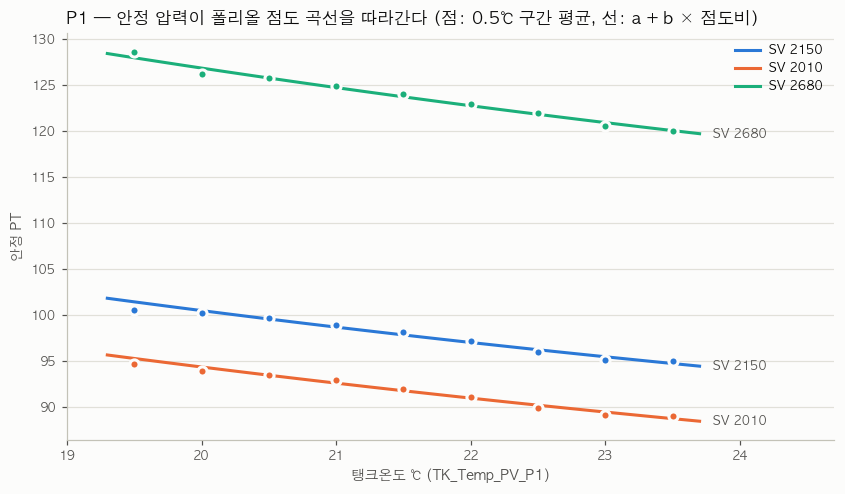

In [52]:
fig, ax = plt.subplots(figsize=(9, 4.8), facecolor=SURFACE)
style_ax(ax)
Tg1 = np.linspace(c1["T"].quantile(0.01), c1["T"].quantile(0.99), 50)
for (sv, (a_, b_)), color in zip(list(P1_FITS.items())[:3], [BLUE, ORANGE, "#1baf7a"]):
    g = c1[c1.SV == sv]
    binned = g.groupby((g["T"] * 2).round() / 2).PT.agg(["mean", "size"])
    binned = binned[binned["size"] >= 30]
    ax.plot(binned.index, binned["mean"], "o", ms=6, color=color, markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
    ax.plot(Tg1, a_ + b_ * mu_rel(Tg1, B_VISC["TM-337"]), color=color, lw=2, zorder=3, label=f"SV {sv:.0f}")
    ax.text(Tg1[-1] + 0.1, a_ + b_ * mu_rel(Tg1[-1], B_VISC["TM-337"]), f"SV {sv:.0f}", color=INK2, fontsize=8,
            va="center")
ax.set_xlim(Tg1[0] - 0.3, Tg1[-1] + 1.0)
ax.set_xlabel("탱크온도 ℃ (TK_Temp_PV_P1)", color=INK2, fontsize=9)
ax.set_ylabel("안정 PT", color=INK2, fontsize=9)
ax.set_title("P1 — 안정 압력이 폴리올 점도 곡선을 따라간다 (점: 0.5℃ 구간 평균, 선: a + b × 점도비)", loc="left",
             color=INK, fontsize=11, fontweight="bold")
ax.legend(loc="upper right", fontsize=8, frameon=False)
plt.show()

- 폴리올은 **압력이 온도를 따라간다**(1℃당 PT 약 −1.6~−1.8%). 22℃ 기준 안정 PT 의 약 4분의 1(23~26%)이 점성 마찰이고,
  나머지는 노즐 등 온도와 무관한 부분이다.
- **토출량(FT/Hz)은 1℃당 0.1% 안팎**으로 거의 안 변한다 — ISO 와 정반대다.
- 바닥 압력 P0 에도 비슷한 크기의 점성분(b ≈ 19~20)이 있다. 팀이 **P0 를 빼서 온도 상관을 −0.61 → −0.21 로 줄인 것**은 이 공통 점성분이
  빠졌기 때문이다. 점도 항을 식에 직접 넣으면 같은 보정을 물리적으로, 극단 온도에서도 맞게 할 수 있다.
- 한계: 이 기간 탱크온도가 4℃ 범위뿐이라 **원료표 기울기 자체를 데이터로 검증하지는 못했다**(이 범위에선 선형과 지수가 구분 안 됨).
  탱크온도 태그와 라인 온도 태그의 관계, 그리고 다른 기간 검증은 11-7 에서 한다.

### 11-6. 정리 — 보정식과 함수

```
μ_rel(T) = exp[ B · (1/T_K − 1/T_ref,K) ]         (섭씨 근사: exp[−β·(T−T_ref)], β = B/T_ref,K²)

ISO    펌프 잔차 : FT/Hz = D − c · (PT/Hz) / μ_rel(T)        → 누설 항을 점도로 나눈다
폴리올 압력     : PT    = a + b · μ_rel(T)   (SV 별)          → 22℃ 기준 압력 PT_22 = PT − b·(μ_rel − 1)
```

| 결정 | 권장 |
|---|---|
| 식의 형태 | Andrade 또는 섭씨 지수 근사. **선형은 ISO ±5℃ 이내에서만** |
| 원료 상수 B | 원료표 값(2013) → 현재 원료 TDS 로 갱신. 없으면 11-4(b) 처럼 데이터로 β 추정 |
| 온도 신호 | `Scale_Out___TT_*` (= `TK_Temp_PV_*`, **같은 센서** — 11-7). 원료당 센서가 하나뿐이라 펌프 내부 온도와는 다를 수 있다 |
| 어디에 넣나 | **ISO → 펌프 누설 항, 폴리올 → 압력 점성 항** |

§10-6 의 `cycle_indicators()` 결과에 온도 보정 컬럼을 붙이는 함수:

In [53]:
def add_temperature_terms(c, B=None, beta=None, temp_col="TT", T_ref=T_REF):
    """cycle_indicators() 결과에 점도 보정 컬럼을 붙인다. temp_col 은 0.1℃ 단위 원값.

    B(원료표 Andrade 상수) 또는 beta(섭씨 지수 근사, 1/℃) 중 하나를 준다.
      mu_rel : μ(T)/μ(T_ref)
      PTn_T  : (PT/Hz×1000)/mu_rel — ISO 슬립 직선의 온도 보정 x
    """
    out = c.copy()
    T_c = out[temp_col] / 10
    out["mu_rel"] = mu_rel(T_c, B, T_ref) if B is not None else np.exp(-beta * (T_c - T_ref))
    out["PTn_T"] = out.PTn / out.mu_rel
    return out


def fit_slip_T(c, mask=None):
    """온도 보정 슬립 직선 FT/Hz = b0 + b1·PTn_T."""
    s = c if mask is None else c[mask]
    b1_, b0_ = np.polyfit(s.PTn_T, s.FT_Hz, 1)
    return b0_, b1_


def pressure_at_ref(c, fits):
    """폴리올: SV 별 (a, b) 로 PT 를 기준온도 압력으로 환산. c 에 mu(= μ_rel) 컬럼이 있어야 한다."""
    out = c.copy()
    out["PT_ref"] = np.nan
    for sv, (a_, b_) in fits.items():
        m = out.SV == sv
        out.loc[m, "PT_ref"] = out.loc[m, "PT"] - b_ * (out.loc[m, "mu"] - 1)
    return out


# I1 적용 예 — §10-6 의 ci 에 TM-20 보정
ciT = add_temperature_terms(ci, B=B_VISC["TM-20"])
slipT = fit_slip_T(ciT, (ciT.t0 >= "2026-09-28"))
ciT["slip_resid_T"] = (ciT.FT_Hz / (slipT[0] + slipT[1] * ciT.PTn_T) - 1) * 100
print("■ I1 일별 펌프 잔차 — 보정 전 / 후")
display(ciT.groupby(ciT.t0.dt.date)[["slip_resid", "slip_resid_T"]].median().round(2))

# P1 적용 예 — 기준온도(22℃) 압력으로 환산하면 온도 상관이 사라지는지
c1r = pressure_at_ref(c1, P1_FITS)
print("■ P1 온도 상관 — 원래 PT / 22℃ 환산 PT")
pd.DataFrame({int(sv): {"corr(PT,T)": round(c1r[c1r.SV == sv].PT.corr(c1r[c1r.SV == sv]["T"]), 2),
                        "corr(PT_22,T)": round(c1r[c1r.SV == sv].PT_ref.corr(c1r[c1r.SV == sv]["T"]), 2)}
              for sv in P1_FITS}).T

■ I1 일별 펌프 잔차 — 보정 전 / 후


,slip_resid,slip_resid_T
t0,,
2026-09-22,0.56,0.55
2026-09-23,0.68,0.65
2026-09-27,-4.13,2.35
2026-09-28,-0.77,-0.86
2026-09-29,-0.14,-0.33
2026-09-30,0.72,0.53
2026-10-01,0.67,0.49


■ P1 온도 상관 — 원래 PT / 22℃ 환산 PT


,"corr(PT,T)","corr(PT_22,T)"
2150,-0.68,-0.0
2010,-0.68,-0.0
2680,-0.52,-0.0
2300,-0.64,-0.0


- I1: 보정 후에도 평소 날짜들의 잔차는 그대로이고, 온도가 달랐던 9/27 만 움직인다(위 11-4 c 의 과보정 주의 그대로).
- P1: 22℃ 환산 압력의 온도 상관이 0 이 되는 건 **같은 데이터로 (a, b) 를 맞췄기 때문에 당연한 결과**다.
  진짜 검증은 다른 기간에 이 계수를 그대로 적용해서 상관이 사라지는지 보는 것이다 — 11-7 에서 한다.

### 11-7. 라인 온도(`Scale_Out___TT_P1`)로 다시 검증 + 다른 기간에 적용

11-5 는 팀 캐시의 탱크온도(`TK_Temp_PV_P1`)로 했다. 라인 온도 태그로 같은 기간(9/14~9/20)을 다시 받아 비교하고,
여기서 맞춘 계수를 **다른 기간(9/28~10/1)에 그대로 적용**해서 온도 상관이 사라지는지 본다.

**(a) 두 태그는 같은 센서다**

In [54]:
show_il("Scale_PGM.il", r"MOV\s+Ana_In___TT_P1 Ana_In", 13)
print()
show_il("Scale_PGM.il", r"MOV\s+Scale_Out___TT_I1 TK_Temp_PV_I1", 1)
show_il("Tank_Control.il", r"LOAD<\s+TK_Temp_PV_P1 TK_Temp_SV_P1", 1)

P1TT_TAGS = ["Pump_BuildUp_P1", "g_s_SV_P1", "Hz_Out_P1", "Scale_Out___FT_P1", "Scale_Out___PT_P1", "Scale_Out___TT_P1",
             "TK_Temp_PV_P1", "AL_Line_Bit"]
p1tt = cached("ftsv_P1_TT_20260914_20260920",
              lambda: extractor().get_data("2026-09-14 00:00:00", "2026-09-20 00:00:00", P1TT_TAGS))
both = p1tt[["Scale_Out___TT_P1", "TK_Temp_PV_P1"]].dropna()
print(f"\n두 태그 값이 같은 비율: {(both.iloc[:, 0] == both.iloc[:, 1]).mean():.1%}")

Scale_PGM.il:446   MOV	Ana_In___TT_P1 Ana_In
Scale_PGM.il:447   MOV	Ana_Max___TT_P1 Ana_Max
Scale_PGM.il:448   MOV	Scale_Max___TT_P1 Scale_Max
Scale_PGM.il:449   MOV	Gain___TT_P1 Gain
Scale_PGM.il:450   MOV	OffSet___TT_P1 OffSet
Scale_PGM.il:451   CALL	AD_Convert
Scale_PGM.il:452   LOAD	Scale_Err
Scale_PGM.il:453   SET	Err__TT_P1
Scale_PGM.il:454   LOAD NOT	Scale_Err
Scale_PGM.il:455   RST	Err__TT_P1
Scale_PGM.il:456   LOAD	_RUN
Scale_PGM.il:457   MOV	Scale_Out Scale_Out___TT_P1
Scale_PGM.il:458   MOV	Scale_Out___TT_P1 TK_Temp_PV_P1

Scale_PGM.il:533   MOV	Scale_Out___TT_I1 TK_Temp_PV_I1
Tank_Control.il:637   LOAD<	TK_Temp_PV_P1 TK_Temp_SV_P1
[cache] ftsv_P1_TT_20260914_20260920

두 태그 값이 같은 비율: 100.0%


- `Scale_PGM.il` 이 아날로그 입력 `Ana_In___TT_P1` 을 환산해 `Scale_Out___TT_P1` 을 만들고, **그 값을 그대로 `TK_Temp_PV_P1` 에 복사**한다.
  I1 도 같다. 두 태그는 처음부터 같은 값이다(일치율 100%).
- 이 값으로 `Tank_Control.il` 이 워킹탱크 온도를 제어한다 → **원료마다 재료온도 센서는 하나이고, 워킹탱크 쪽 온도**다.
  펌프·배관 내부 온도를 따로 재는 센서는 없다. 앞에서 "탱크온도는 상류값이라 라인 온도를 써야 한다"고 한 것은 정정한다 —
  어느 태그를 써도 같고, 대신 **펌프 내부 온도와의 차이**(11-4 c 의 9/27 과보정)는 이 센서 구조의 한계다.

**(b) 라인 온도로 다시 맞추고, 다른 기간(9/28~10/1)에 그대로 적용**

In [55]:
def p1_cycles(rawp, temp_tag="Scale_Out___TT_P1"):
    qq = rawp.ffill().reset_index()
    b_ = qq.Pump_BuildUp_P1.fillna(0).astype(int)
    qq["cyc"] = (b_.diff().fillna(0) != 0).cumsum()
    oo = qq[b_ == 1].copy()
    oo["hzg"] = (oo.Hz_Out_P1.diff().fillna(0) != 0).cumsum()
    oo = oo[oo.groupby("hzg").cumcount() >= STEADY_MIN]
    cc = oo.groupby("cyc").agg(t0=("Time", "min"), n=("Time", "size"), SV=("g_s_SV_P1", "median"),
                               FT=("Scale_Out___FT_P1", "median"), PT=("Scale_Out___PT_P1", "median"),
                               T=(temp_tag, "median"))
    cc = cc[cc.n >= 8].copy()
    cc["T"] = cc["T"] / 10
    cc["mu"] = mu_rel(cc["T"], B_VISC["TM-337"])
    return cc


train = p1_cycles(p1tt)                       # 9/14~9/20, 라인 온도
p1_raw = cached("ftsv_P1_20260928_20261001", lambda: extractor().get_data(AUX_START, AUX_END, P1_TAGS))   # §7-1 과 같은 데이터
test = p1_cycles(p1_raw)                      # 9/28~10/1, 라인 온도
print(f"학습 9/14~20: 온도 {train['T'].quantile(0.01):.1f}~{train['T'].quantile(0.99):.1f}℃ | "
      f"검증 9/28~10/1: {test['T'].quantile(0.01):.1f}~{test['T'].quantile(0.99):.1f}℃")

FITS_TT, rows = {}, []
for sv in train.SV.value_counts().index[:4]:
    g = train[train.SV == sv]
    b_, a_ = np.polyfit(g.mu, g.PT, 1)
    FITS_TT[sv] = (a_, b_)
    h = test[test.SV == sv]
    row = {"SV": int(sv), "학습 사이클": len(g), "학습 corr(PT,T)": round(g.PT.corr(g["T"]), 2),
           "점성 마찰 비중 %": round(b_ / (a_ + b_) * 100, 1), "검증 사이클": len(h)}
    if len(h) >= 100:
        pt22 = h.PT - b_ * (h.mu - 1)
        row.update({"검증 corr(PT,T)": round(h.PT.corr(h["T"]), 2), "검증 corr(PT_22,T)": round(pt22.corr(h["T"]), 2),
                    "검증 기울기 %/℃ 실측": round(np.polyfit(h["T"], h.PT, 1)[0] / h.PT.median() * 100, 2),
                    "검증 기울기 %/℃ 예측": round(np.polyfit(h["T"], a_ + b_ * h.mu, 1)[0] / h.PT.median() * 100, 2),
                    "압력 수준 차이 (검증−예측 중앙)": round(np.median(h.PT - (a_ + b_ * h.mu)), 1)})
    rows.append(row)
pd.DataFrame(rows)

[cache] ftsv_P1_20260928_20261001
학습 9/14~20: 온도 19.3~23.7℃ | 검증 9/28~10/1: 19.4~23.7℃


,SV,학습 사이클,"학습 corr(PT,T)",점성 마찰 비중 %,검증 사이클,"검증 corr(PT,T)","검증 corr(PT_22,T)",검증 기울기 %/℃ 실측,검증 기울기 %/℃ 예측,압력 수준 차이 (검증−예측 중앙)
0,2150,4131,-0.68,25.2,1552,-0.59,-0.03,-1.83,-1.76,-3.8
1,2010,3632,-0.68,26.1,1380,-0.70,-0.24,-2.38,-1.79,-1.3
2,2680,3449,-0.52,23.4,2176,-0.52,0.13,-1.30,-1.58,-0.7
3,2300,1685,-0.64,24.6,0,NaN,NaN,NaN,NaN,NaN


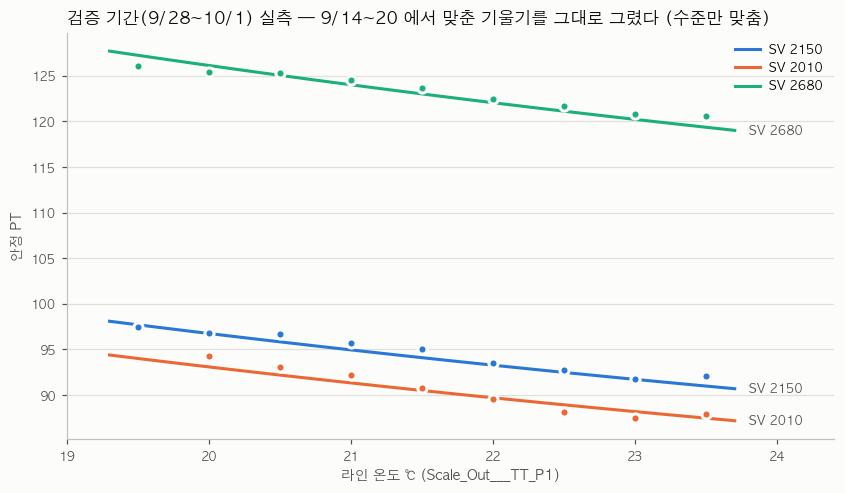

In [56]:
fig, ax = plt.subplots(figsize=(9, 4.8), facecolor=SURFACE)
style_ax(ax)
Tg2 = np.linspace(19.3, 23.7, 50)
for (sv, (a_, b_)), color in zip([(s, FITS_TT[s]) for s in [2150.0, 2010.0, 2680.0]], [BLUE, ORANGE, "#1baf7a"]):
    h = test[test.SV == sv]
    bm = h.groupby((h["T"] * 2).round() / 2).PT.agg(["mean", "size"])
    bm = bm[bm["size"] >= 30]
    off = np.median(h.PT - (a_ + b_ * h.mu))
    ax.plot(Tg2, a_ + off + b_ * mu_rel(Tg2, B_VISC["TM-337"]), color=color, lw=2, zorder=3, label=f"SV {sv:.0f}")
    ax.plot(bm.index, bm["mean"], "o", ms=6, color=color, markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
    ax.text(Tg2[-1] + 0.1, a_ + off + b_ * mu_rel(Tg2[-1], B_VISC["TM-337"]), f"SV {sv:.0f}", color=INK2,
            fontsize=8, va="center")
ax.set_xlim(19.0, 24.4)
ax.set_xlabel("라인 온도 ℃ (Scale_Out___TT_P1)", color=INK2, fontsize=9)
ax.set_ylabel("안정 PT", color=INK2, fontsize=9)
ax.set_title("검증 기간(9/28~10/1) 실측 — 9/14~20 에서 맞춘 기울기를 그대로 그렸다 (수준만 맞춤)", loc="left",
             color=INK, fontsize=11, fontweight="bold")
ax.legend(loc="upper right", fontsize=8, frameon=False)
plt.show()

- **9/14~20 에서 맞춘 온도 계수를 9/28~10/1 에 그대로 적용해도 온도 상관이 대부분 사라진다.** 같은 데이터로 맞춘 게 아니라서
  이번엔 진짜 검증이다(SV 2150: −0.59 → −0.03, SV 2680: −0.52 → +0.13, SV 2010: −0.70 → −0.24).
- 기울기도 비교하면 예측 −1.6~−1.8 %/℃ 에 실측 −1.3~−2.4 %/℃ — SV 2150 은 거의 일치(−1.76 vs −1.83), SV 2010 은 실측이 더
  가파르고 SV 2680 은 덜 가파르다. 방향과 크기는 맞고, SV 별 세부 차이는 남는다.
- 다만 **압력 수준 자체**는 기간 사이에 몇 단위 달라졌다(표의 마지막 열). 온도와 무관한 부분(노즐 등)이 그사이 바뀐 것이고,
  그래서 그림은 기울기만 학습값을 쓰고 수준은 검증 기간에 맞췄다. 실시간에 쓸 때는 `a` 를 주기적으로 다시 잡거나,
  팀 방식처럼 P0 를 빼는 것과 함께 쓰는 게 안전하다.
- 온도 범위가 두 기간 모두 19~24℃ 라 **지수식과 선형식은 여기서도 구분되지 않는다**(11-2 의 권장 그대로 지수식을 쓴다).
  원료표 B 값 자체의 검증은 겨울철 저온 시동이나 연휴 뒤 고온처럼 범위가 넓은 데이터가 쌓이면 다시 해야 한다.